In [ ]:
from google.colab import drive

**Cell 1: Setup and Installations
Run this cell to import the necessary libraries and mount your Google Drive.**

In [ ]:
import os
import pandas as pd
import numpy as np
import librosa
import librosa.display
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from google.colab import drive
from google.colab import files
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d # Added this import

# Mount Google Drive
drive.mount('/content/drive')

# Configuration parameters
CONFIG = {
    'csv_path': '/content/drive/MyDrive/train_synthetic_melody/all_melodies_metadata.csv',
    'audio_dir': '/content/drive/MyDrive/train_synthetic_melody/',
    'sr': 16000,
    'hop_length': 512,
    'n_bins': 84,           # 7 octaves for CQT
    'bins_per_octave': 12,
    'max_duration': 10.0,   # truncate or pad to 10 seconds
    'batch_size': 16,
    'epochs': 20,
    'lr': 0.001,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu'
}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Cell 2: Dataset Preparation**
This cell defines the PyTorch Dataset. It reads all_melodies_metadata.csv, converts the audio to CQT, and maps the start_time and end_time to frame-level binary targets (1 for boundary, 0 for steady/silence). To help the model learn, boundaries are smoothed (given a small window of activation).

In [ ]:
class FluteMelodyDataset(Dataset):
    def __init__(self, csv_path, audio_dir, config):
        self.config = config
        self.audio_dir = audio_dir

        # Read the metadata
        self.df = pd.read_csv(csv_path)
        self.melody_files = self.df['melody_file'].unique()

        # Calculate max frames based on max_duration
        self.max_samples = int(self.config['max_duration'] * self.config['sr'])
        self.max_frames = int(np.ceil(self.max_samples / self.config['hop_length']))

    def __len__(self):
        return len(self.melody_files)

    def __getitem__(self, idx):
        filename = self.melody_files[idx]
        file_path = os.path.join(self.audio_dir, filename)

        # 1. Load Audio
        y, sr = librosa.load(file_path, sr=self.config['sr'])

        # Pad or truncate audio to fixed length
        if len(y) > self.max_samples:
            y = y[:self.max_samples]
        else:
            y = np.pad(y, (0, self.max_samples - len(y)))

        # 2. Compute CQT
        cqt = np.abs(librosa.cqt(y, sr=sr, hop_length=self.config['hop_length'],
                                 n_bins=self.config['n_bins'],
                                 bins_per_octave=self.config['bins_per_octave']))

        # Convert to Decibels and normalize
        cqt_db = librosa.amplitude_to_db(cqt, ref=np.max)
        cqt_db = (cqt_db - cqt_db.min()) / (cqt_db.max() - cqt_db.min() + 1e-6)

        # Output shape: [Channels=1, Freq_bins, Time_frames]
        cqt_tensor = torch.tensor(cqt_db, dtype=torch.float32).unsqueeze(0)

        # 3. Create Boundary Labels (Updated with Gaussian smoothing)
        labels = np.zeros(self.max_frames)
        file_df = self.df[self.df['melody_file'] == filename]

        for _, row in file_df.iterrows():
            start_frame = int((row['start_time'] * sr) / self.config['hop_length'])
            end_frame = int((row['end_time'] * sr) / self.config['hop_length'])

            if 0 <= start_frame < self.max_frames:
                labels[start_frame] = 1.0
            if 0 <= end_frame < self.max_frames:
                labels[end_frame] = 1.0

        # Smooth targets into continuous Gaussian bells
        labels = gaussian_filter1d(labels, sigma=1.8)
        labels = labels / (labels.max() + 1e-6) # Normalize back to 0.0 - 1.0

        label_tensor = torch.tensor(labels, dtype=torch.float32)
        return cqt_tensor, label_tensor

# Initialize DataLoader
dataset = FluteMelodyDataset(CONFIG['csv_path'], CONFIG['audio_dir'], CONFIG)
dataloader = DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=True)

**Cell 3: The CRNN + Attention Model**
This model extracts spatial-spectral features using CNNs, passes them to a BiLSTM for temporal context, applies Multi-Head Attention to focus on boundary transitions, and outputs a probability score for each frame.

In [ ]:
class CRNNAttention(nn.Module):
    def __init__(self, n_bins=84):
        super(CRNNAttention, self).__init__()

        # CNN Block
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d((2, 1)), # Pool frequency, keep time

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 1)),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 1))
        )

        # Calculate RNN input size (n_bins / 2 / 2 / 2 = n_bins // 8)
        cnn_out_freq = n_bins // 8
        rnn_in_size = 64 * cnn_out_freq

        # BiLSTM Block
        self.rnn = nn.LSTM(rnn_in_size, 128, bidirectional=True, batch_first=True)

        # Attention Mechanism
        self.attention = nn.MultiheadAttention(embed_dim=256, num_heads=4, batch_first=True)

        # Classifier
        self.fc = nn.Sequential(
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        # x: [Batch, 1, Freq, Time]
        x = self.cnn(x)

        # Reshape for RNN: [Batch, Channels, Freq, Time] -> [Batch, Time, Channels*Freq]
        b, c, f, t = x.size()
        x = x.permute(0, 3, 1, 2).contiguous()
        x = x.view(b, t, c * f)

        # RNN
        rnn_out, _ = self.rnn(x) # rnn_out: [Batch, Time, 256]

        # Attention
        attn_out, _ = self.attention(rnn_out, rnn_out, rnn_out)

        # Classifier
        out = self.fc(attn_out).squeeze(-1) # [Batch, Time]
        return out

model = CRNNAttention(n_bins=CONFIG['n_bins']).to(CONFIG['device'])

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=2.0):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        bce_loss = nn.functional.binary_cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-bce_loss)
        focal_loss = self.alpha * ((1 - pt) ** self.gamma) * bce_loss
        return focal_loss.mean()

**Cell 4: Training Loop**
Because boundary frames are rare compared to silent/steady frames, we use a weighted Binary Cross-Entropy loss to penalize the model more when it misses a boundary.

In [ ]:
from tqdm.notebook import tqdm

criterion = FocalLoss(alpha=0.75, gamma=2.0) # Updated to FocalLoss
optimizer = optim.Adam(model.parameters(), lr=CONFIG['lr'])

print("Starting Training...")
for epoch in range(CONFIG['epochs']):
    model.train()
    running_loss = 0.0

    # Wrap the dataloader with tqdm
    progress_bar = tqdm(dataloader, desc=f"Epoch {epoch+1}/{CONFIG['epochs']}", leave=False)

    for cqt, labels in progress_bar:
        cqt = cqt.to(CONFIG['device'])
        labels = labels.to(CONFIG['device'])

        optimizer.zero_grad()
        outputs = model(cqt)

        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        # Update progress bar with the current batch loss
        progress_bar.set_postfix({'loss': f"{loss.item():.4f}"})

    avg_loss = running_loss / len(dataloader)
    print(f"Epoch [{epoch+1}/{CONFIG['epochs']}] - Loss: {avg_loss:.4f}")

print("Training Complete!")
# torch.save(model.state_dict(), 'crnn_boundary_model.pth')

Starting Training...


Epoch 1/20:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch [1/20] - Loss: 0.0704


Epoch 2/20:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch [2/20] - Loss: 0.0379


Epoch 3/20:   0%|          | 0/63 [00:00<?, ?it/s]

... (31 outputs left out)

Epoch 19/20:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch [19/20] - Loss: 0.0260


Epoch 20/20:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch [20/20] - Loss: 0.0257
Training Complete!


**Cell 5: Testing and Visualization (Upload your own audio)**
Run this cell to upload a .wav file. The model will process it, run it through the network, and plot the CQT spectrogram with red vertical lines wherever it detects a segmentation boundary.

Saving test1.wav to test1 (2).wav
Saving test2.wav to test2 (2).wav
Saving test3.wav to test3 (2).wav
Saving test4.wav to test4 (2).wav
Saving test5.wav to test5 (2).wav
Saving test6.wav to test6 (2).wav
Saving test7.wav to test7 (2).wav
Saving test8.wav to test8 (2).wav
Saving test9.wav to test9 (2).wav
Saving test10.wav to test10 (2).wav
Saving test11.wav to test11 (2).wav
Saving test12.wav to test12 (2).wav
Saving test13.wav to test13 (2).wav
Saving test14.wav to test14 (2).wav
Saving test15.wav to test15 (1).wav
Saving test16.wav to test16 (1).wav
Saving test17.wav to test17 (1).wav
Saving test18.wav to test18 (1).wav
Saving test19.wav to test19 (1).wav


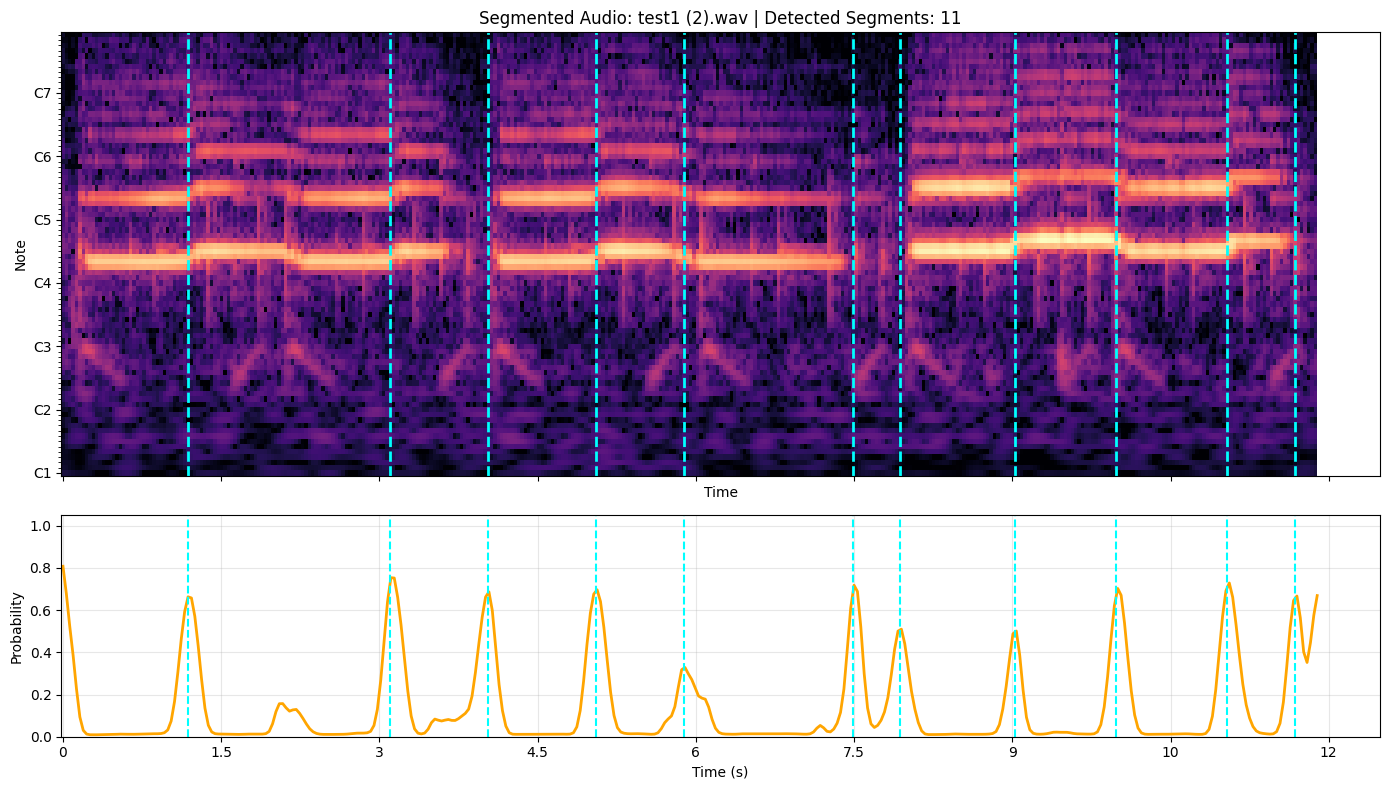

✅ Found 11 boundaries at timestamps (sec):
[ 1.184  3.104  4.032  5.056  5.888  7.488  7.936  9.024  9.984 11.04
 11.68 ]


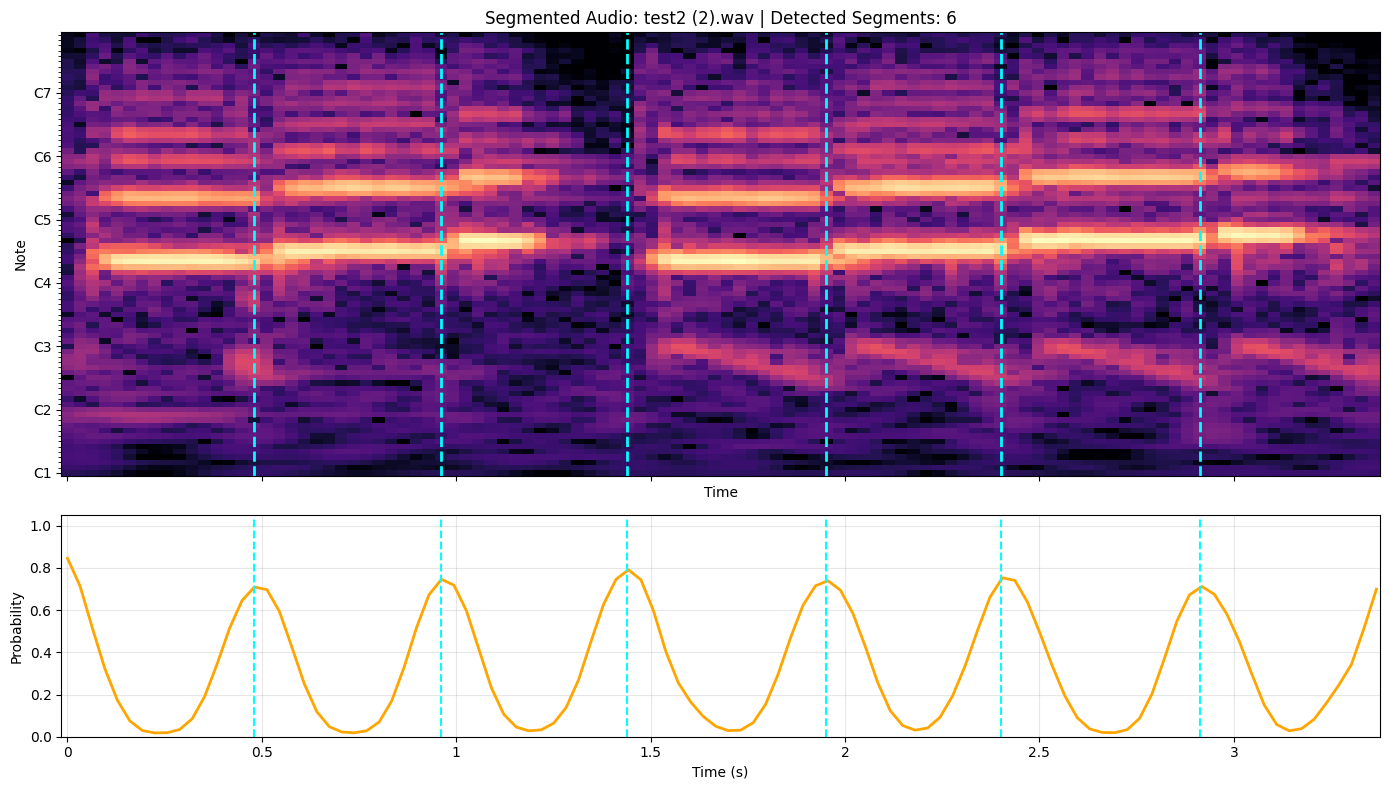

✅ Found 6 boundaries at timestamps (sec):
[0.48  0.96  1.44  1.952 2.4   2.912]


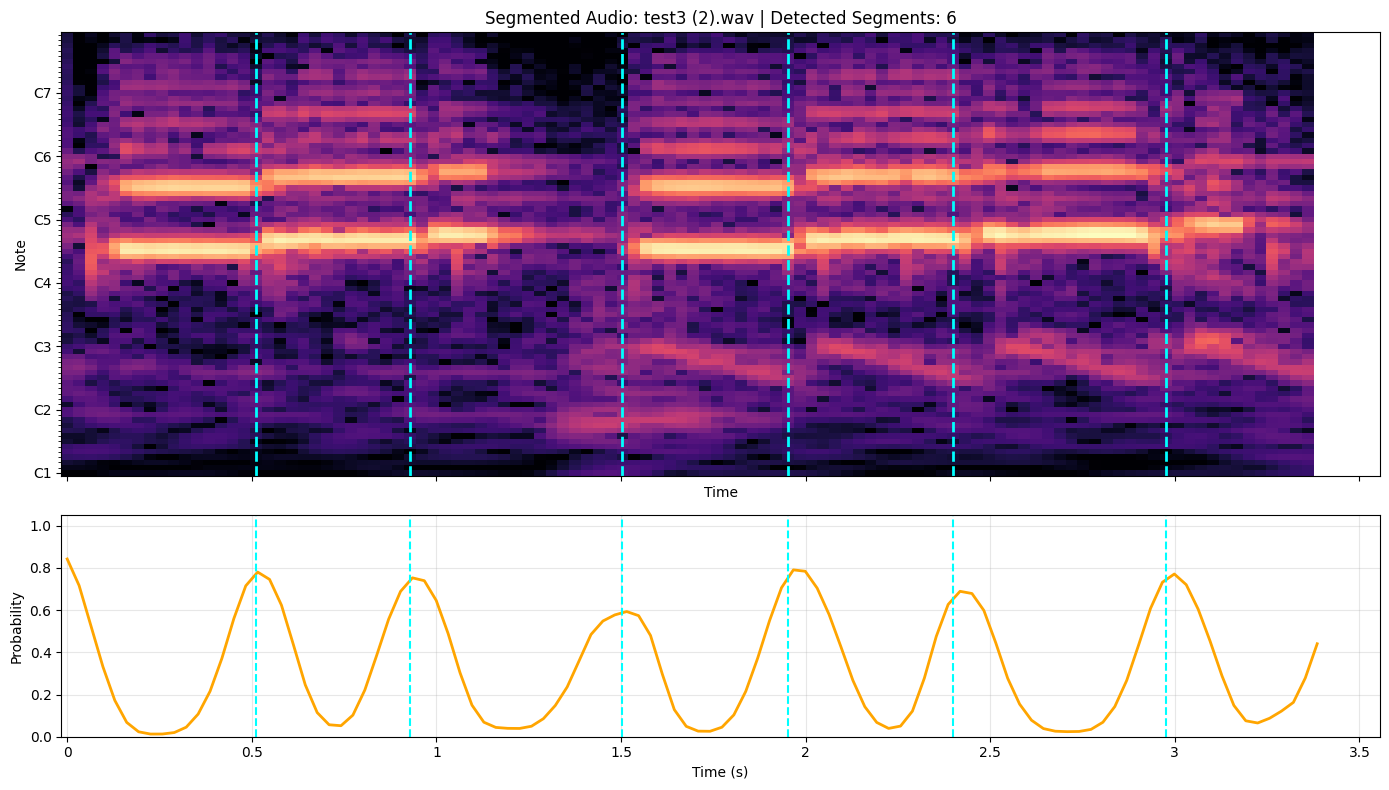

✅ Found 6 boundaries at timestamps (sec):
[0.512 0.928 1.504 1.952 2.4   2.976]


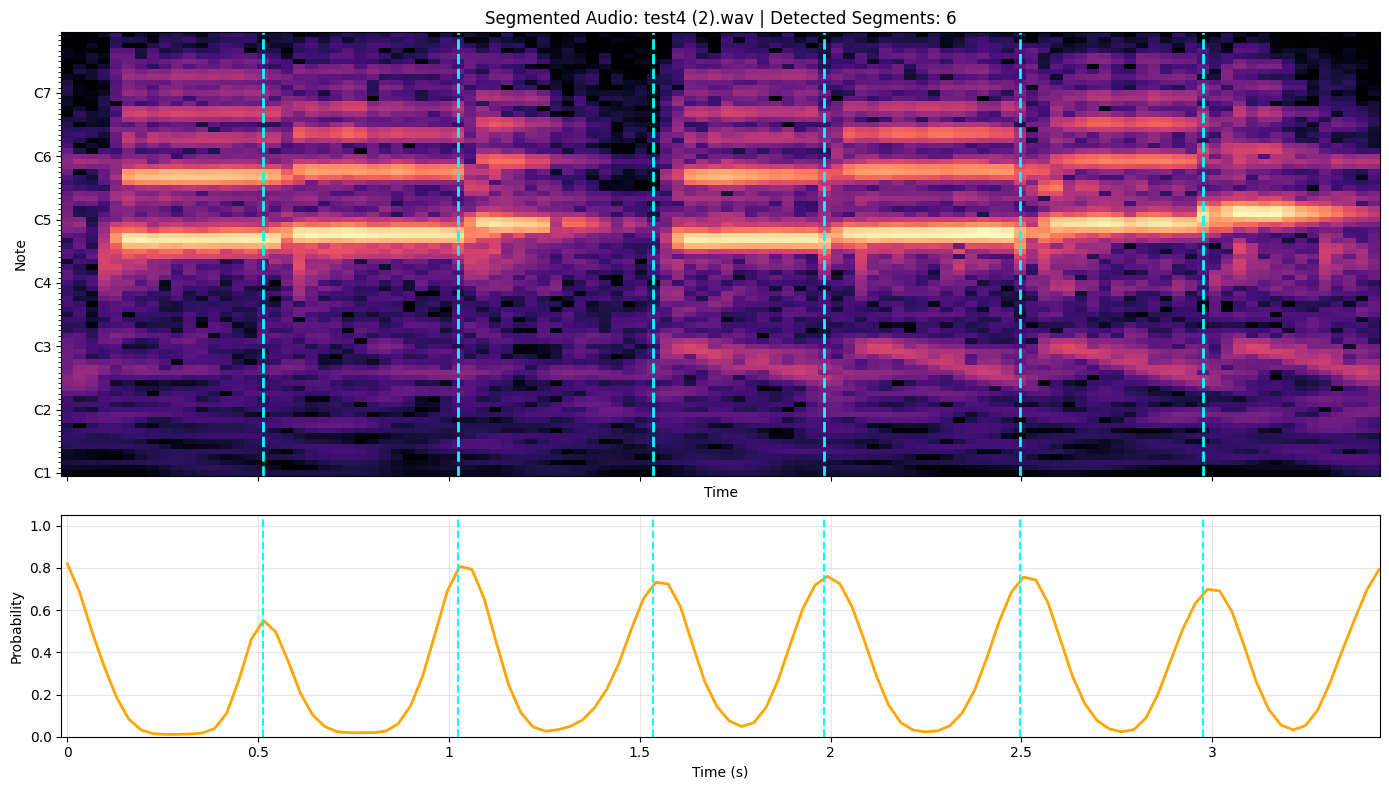

✅ Found 6 boundaries at timestamps (sec):
[0.512 1.024 1.536 1.984 2.496 2.976]


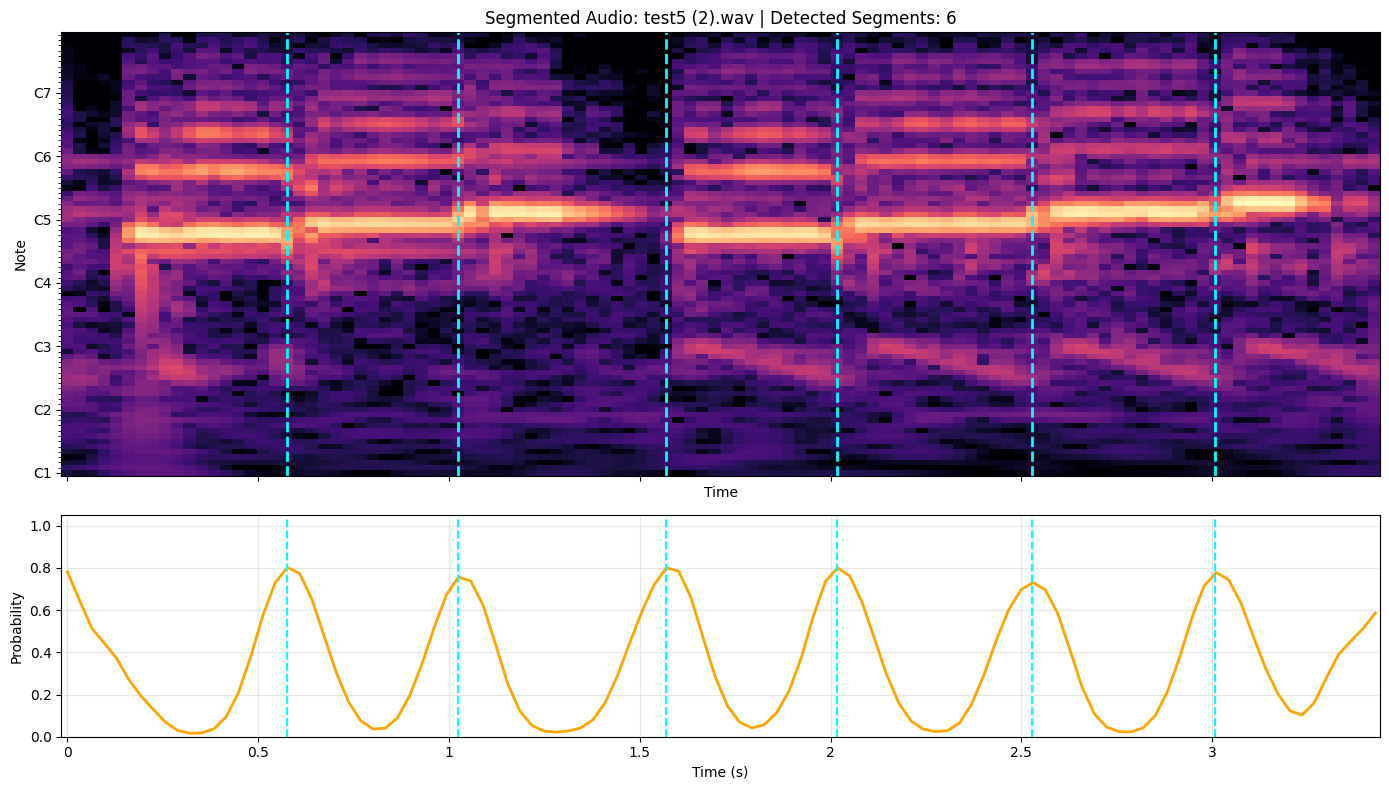

✅ Found 6 boundaries at timestamps (sec):
[0.576 1.024 1.568 2.016 2.528 3.008]


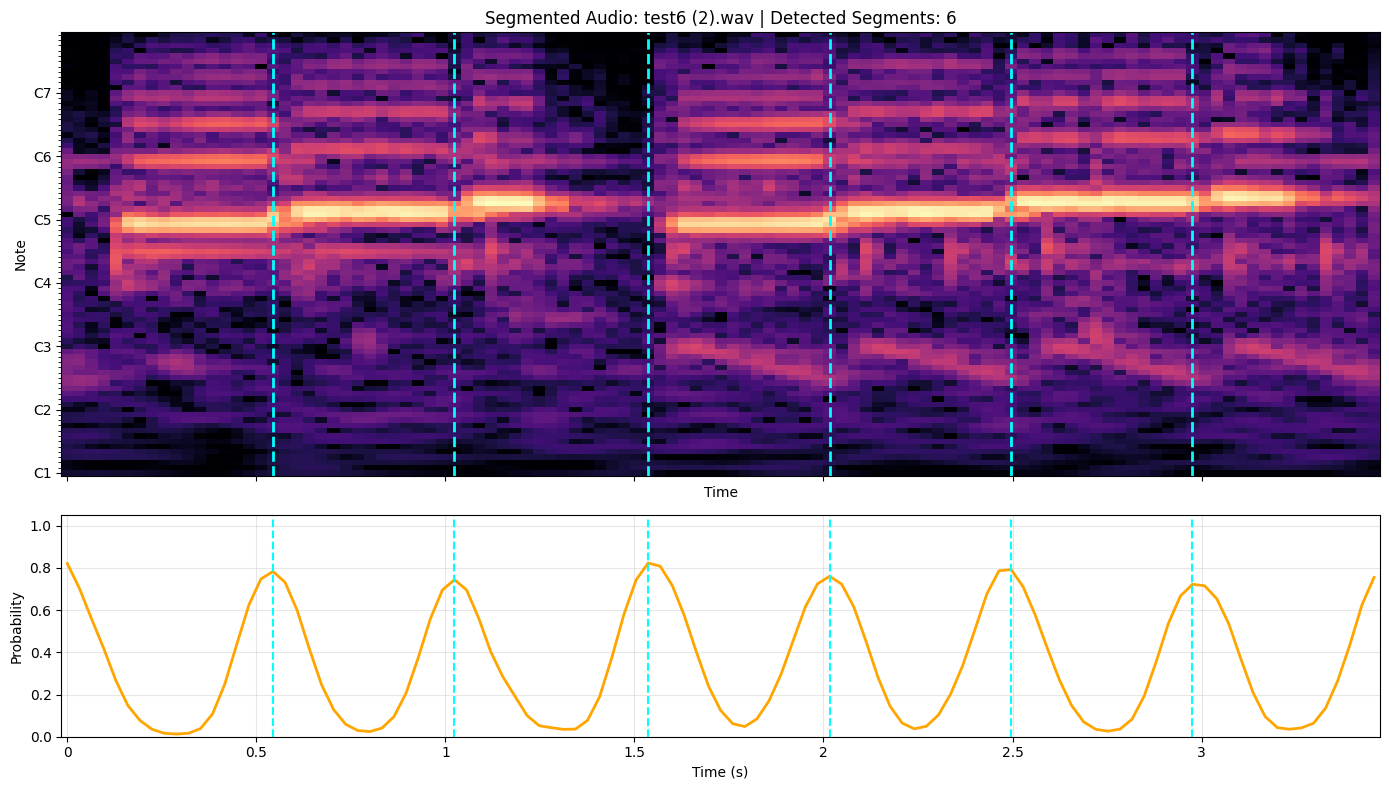

✅ Found 6 boundaries at timestamps (sec):
[0.544 1.024 1.536 2.016 2.496 2.976]


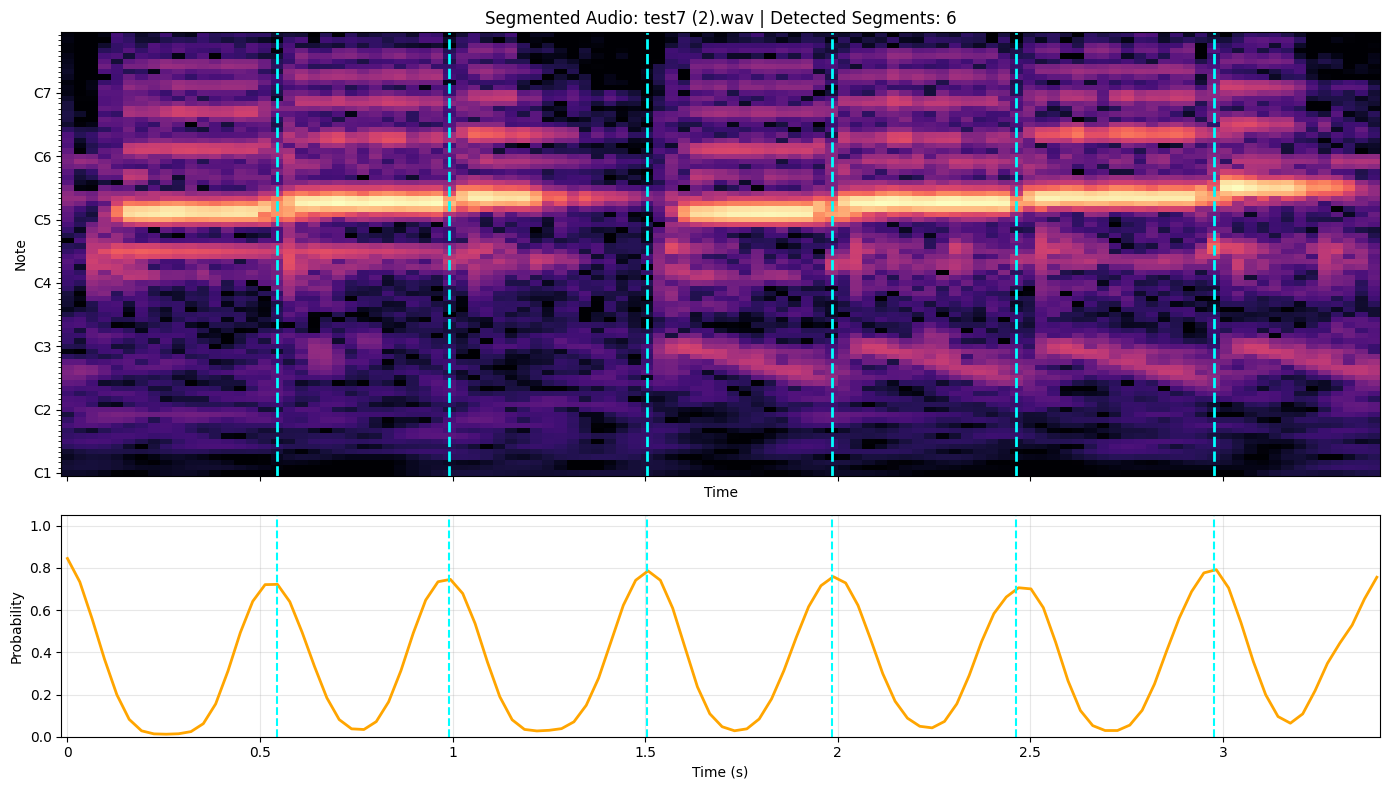

✅ Found 6 boundaries at timestamps (sec):
[0.544 0.992 1.504 1.984 2.464 2.976]


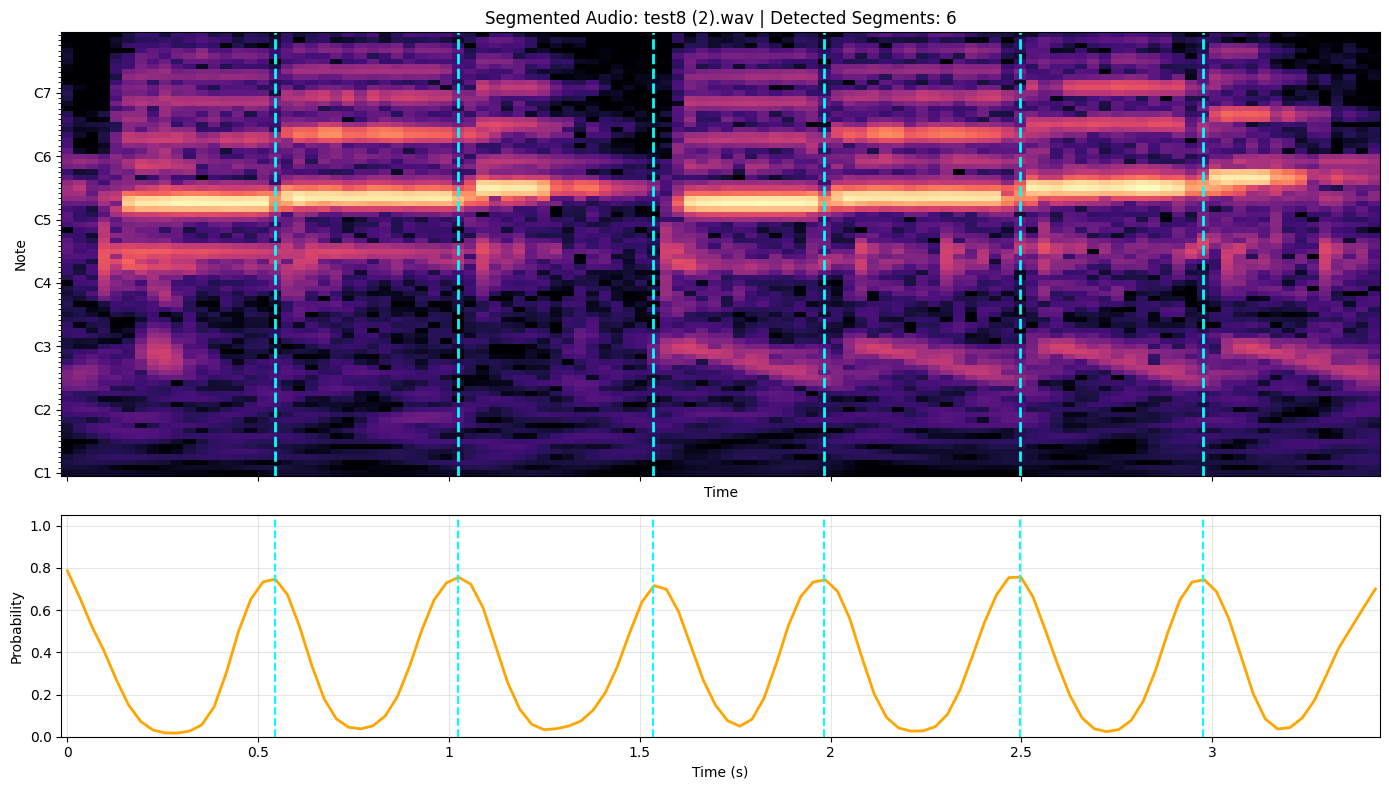

✅ Found 6 boundaries at timestamps (sec):
[0.544 1.024 1.536 1.984 2.496 2.976]


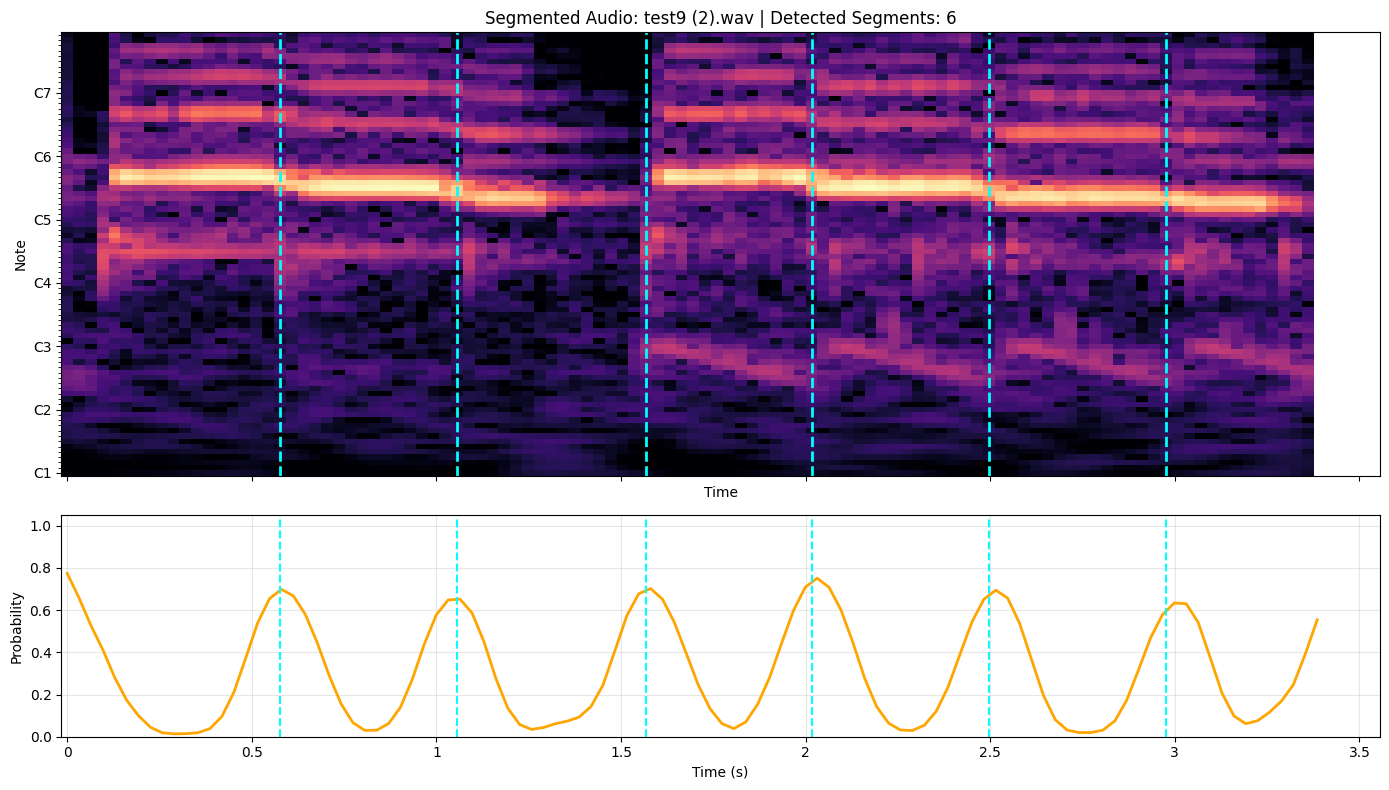

✅ Found 6 boundaries at timestamps (sec):
[0.576 1.056 1.568 2.016 2.496 2.976]


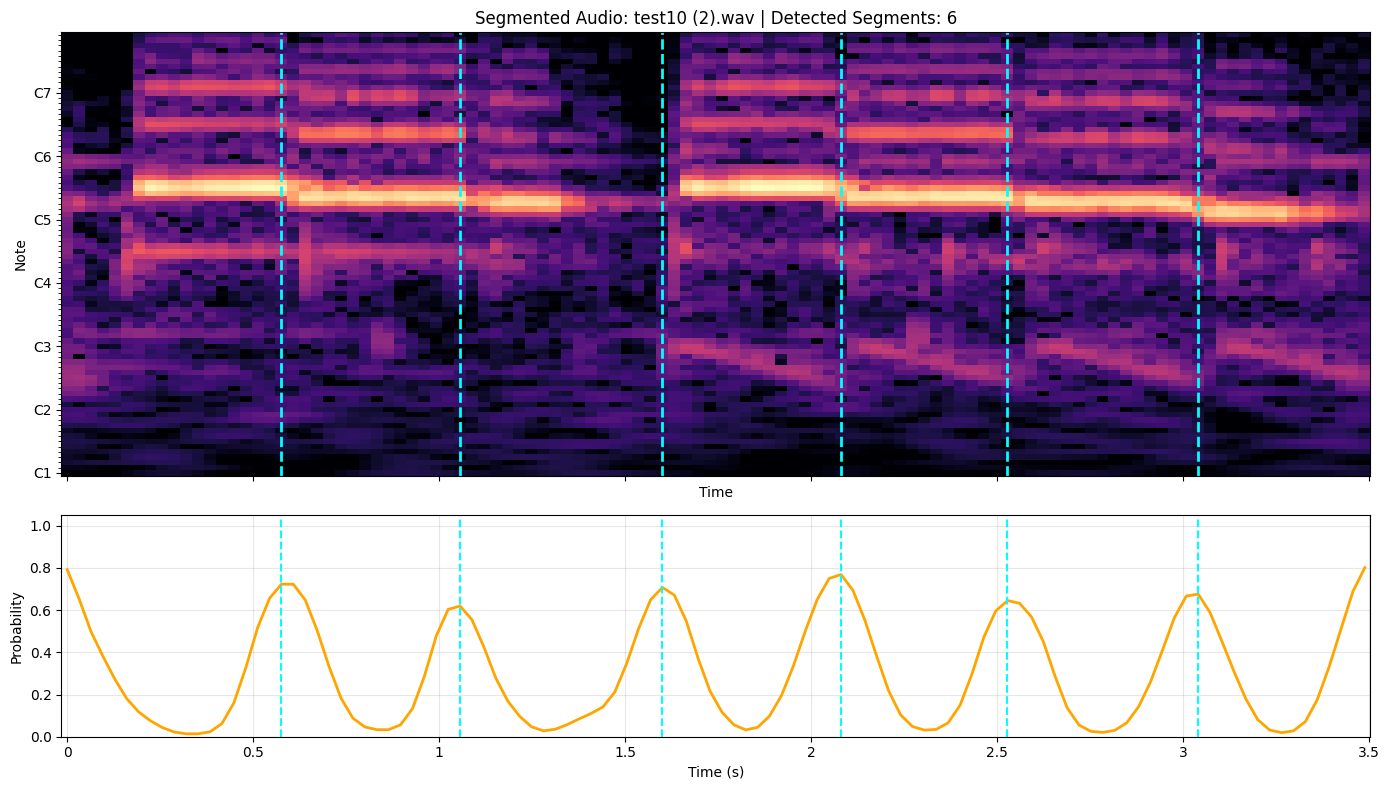

✅ Found 6 boundaries at timestamps (sec):
[0.576 1.056 1.6   2.08  2.528 3.04 ]


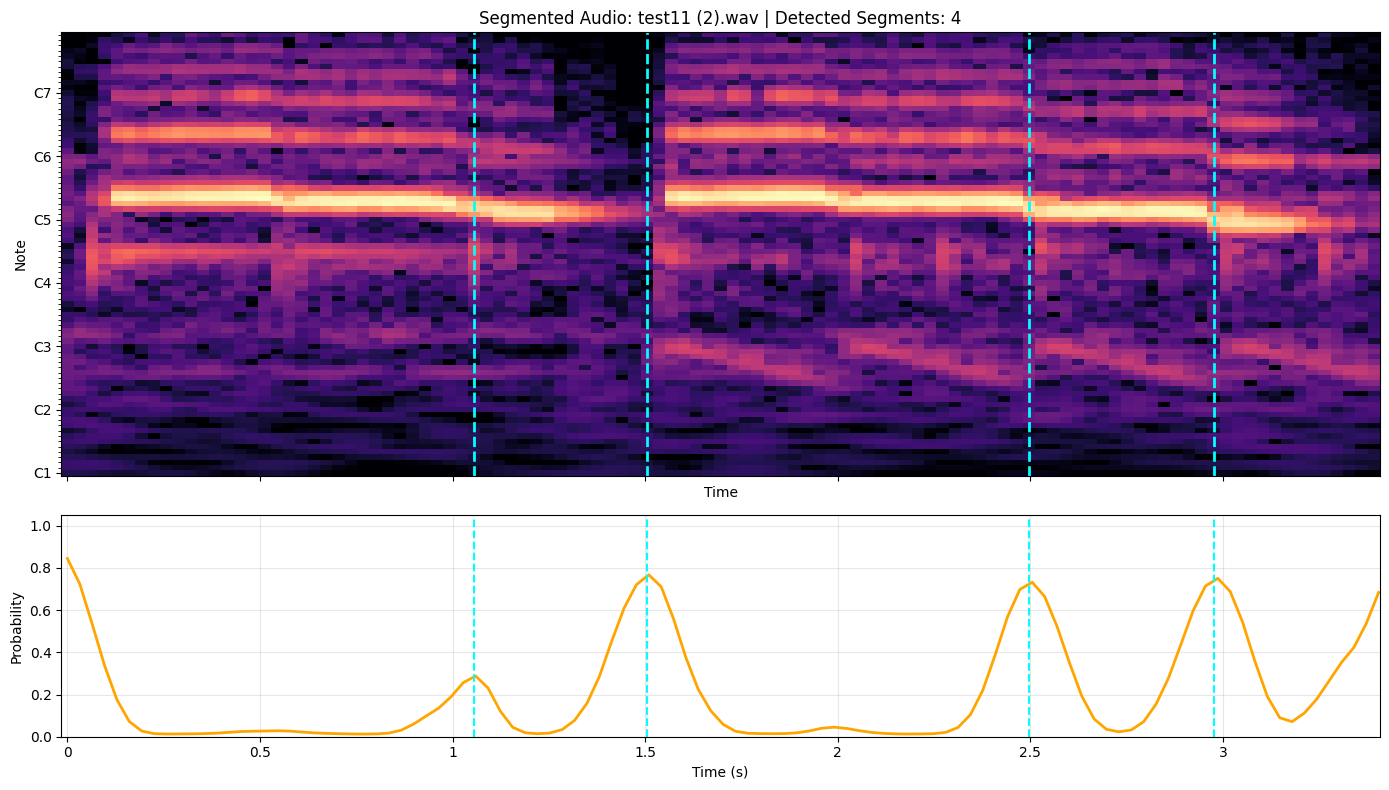

✅ Found 4 boundaries at timestamps (sec):
[1.056 1.504 2.496 2.976]


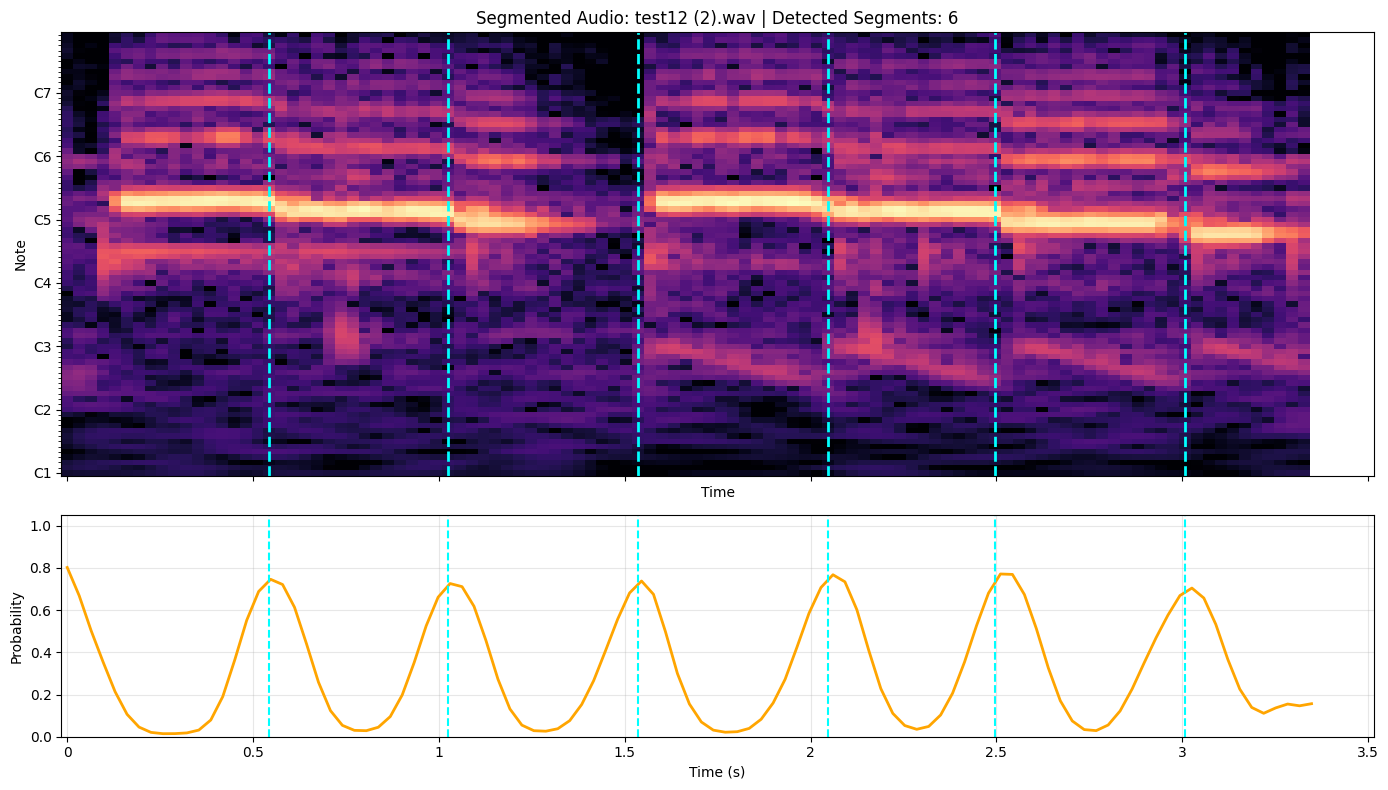

✅ Found 6 boundaries at timestamps (sec):
[0.544 1.024 1.536 2.048 2.496 3.008]


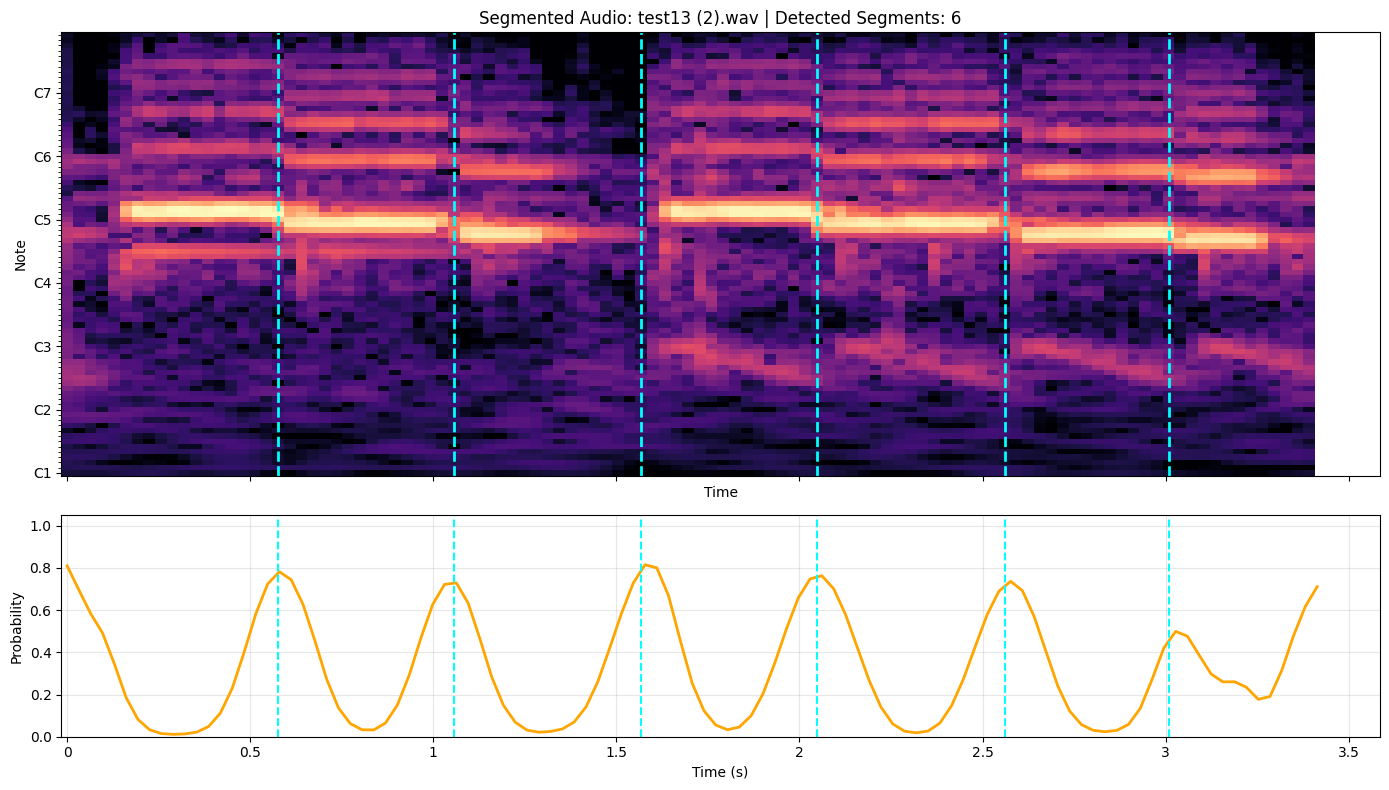

✅ Found 6 boundaries at timestamps (sec):
[0.576 1.056 1.568 2.048 2.56  3.008]


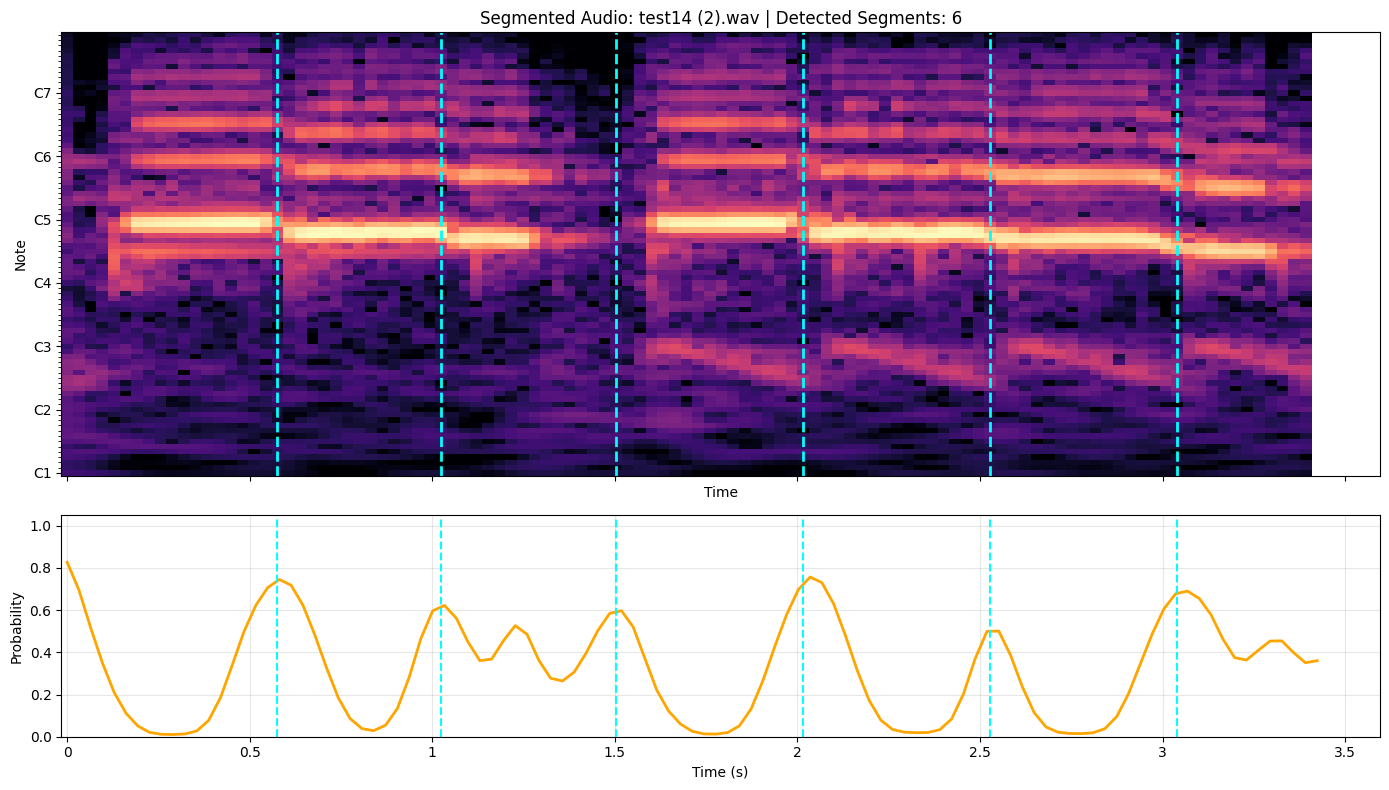

✅ Found 6 boundaries at timestamps (sec):
[0.576 1.024 1.504 2.016 2.528 3.04 ]


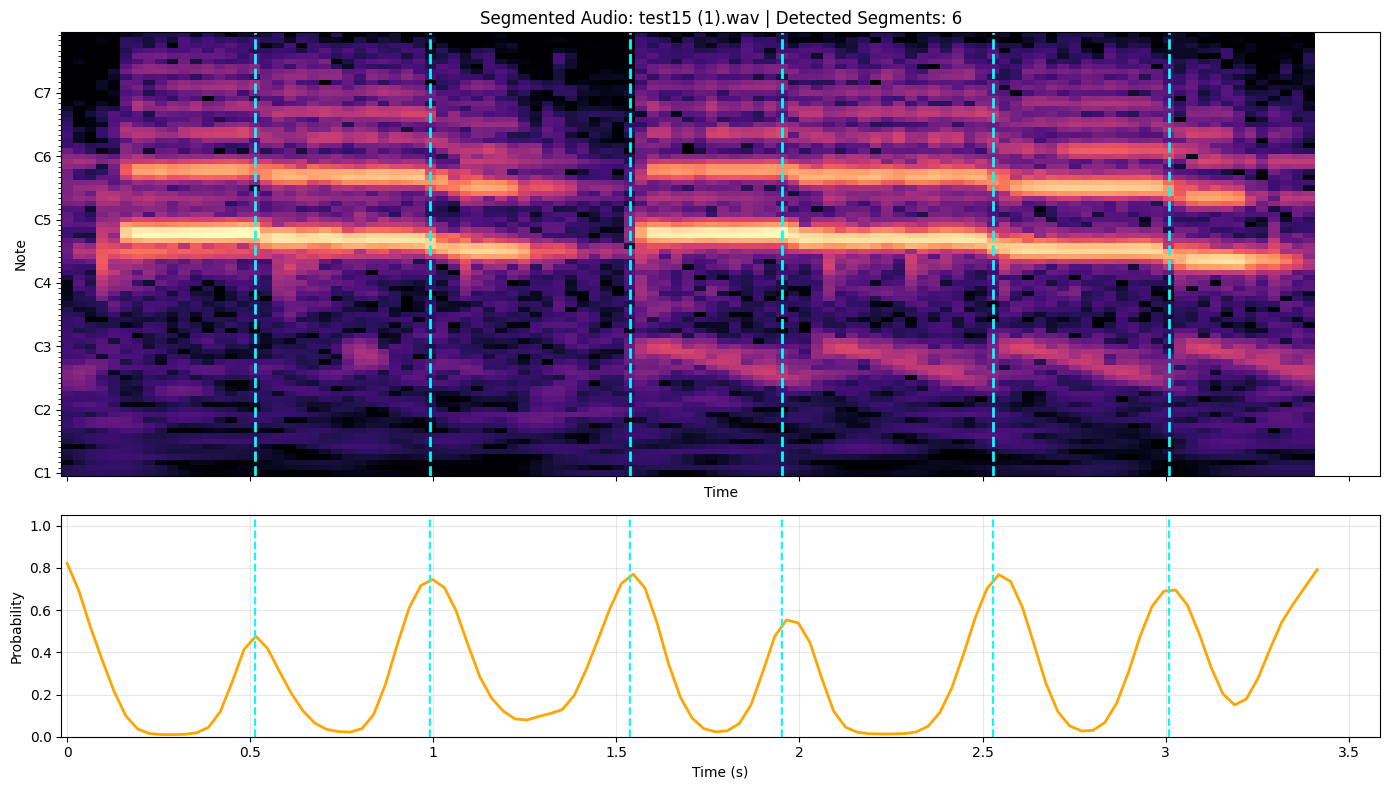

✅ Found 6 boundaries at timestamps (sec):
[0.512 0.992 1.536 1.952 2.528 3.008]


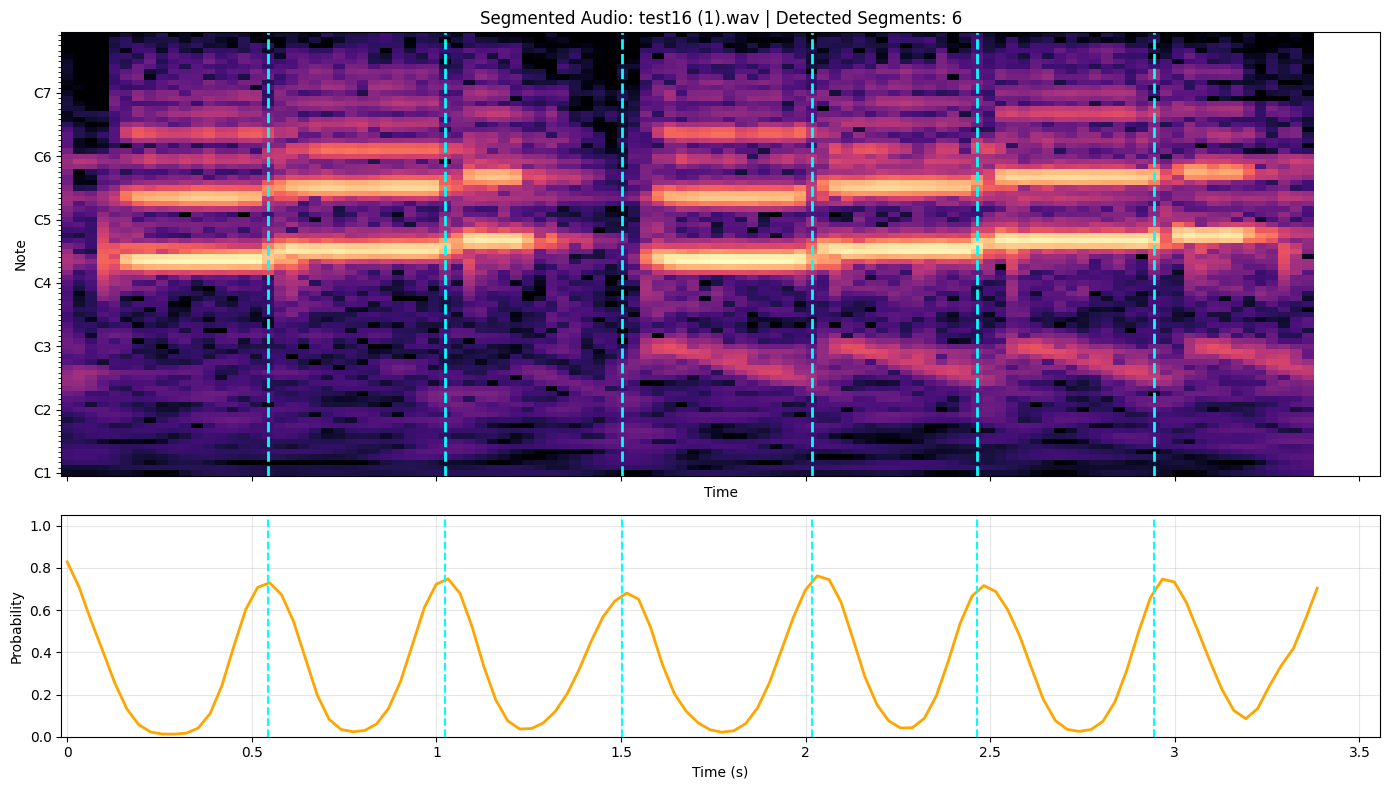

✅ Found 6 boundaries at timestamps (sec):
[0.544 1.024 1.504 2.016 2.464 2.944]


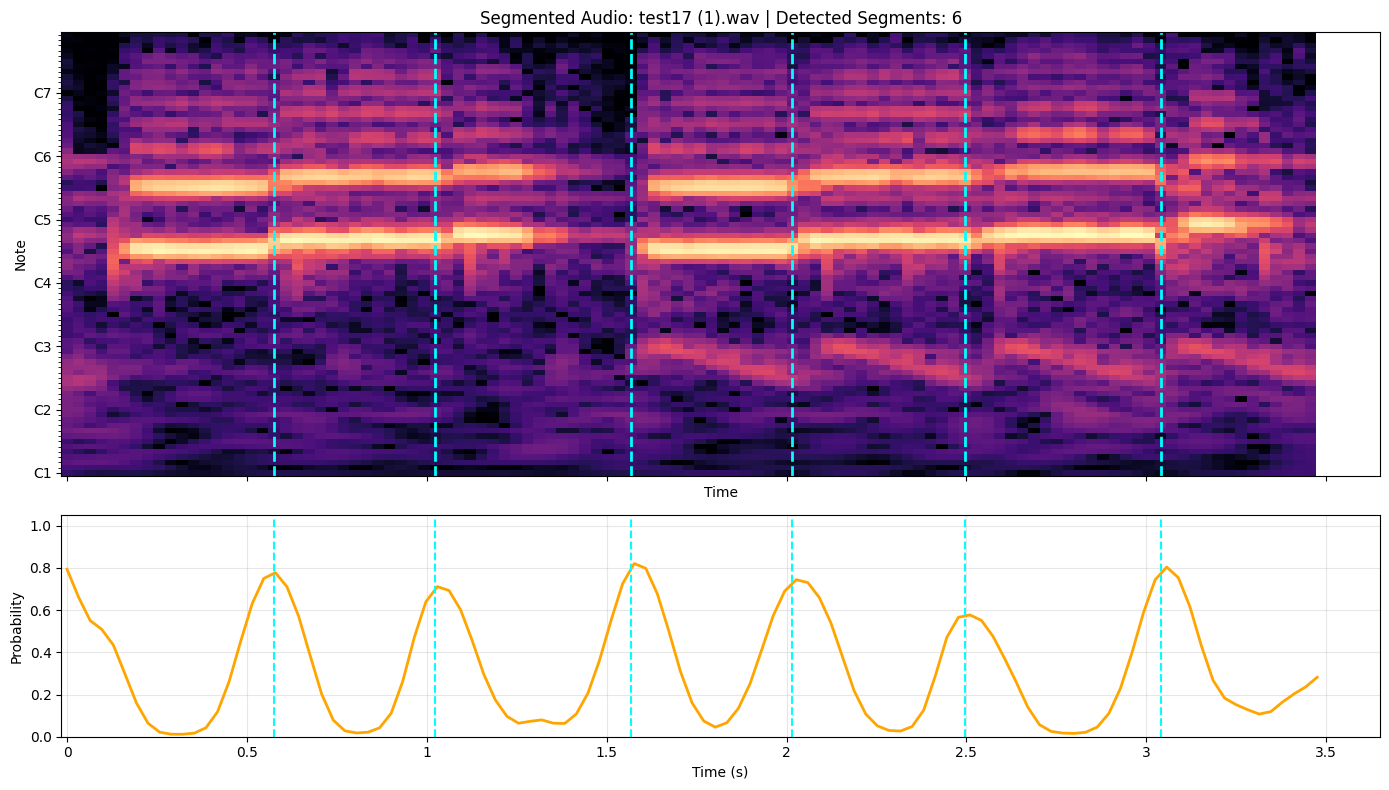

✅ Found 6 boundaries at timestamps (sec):
[0.576 1.024 1.568 2.016 2.496 3.04 ]


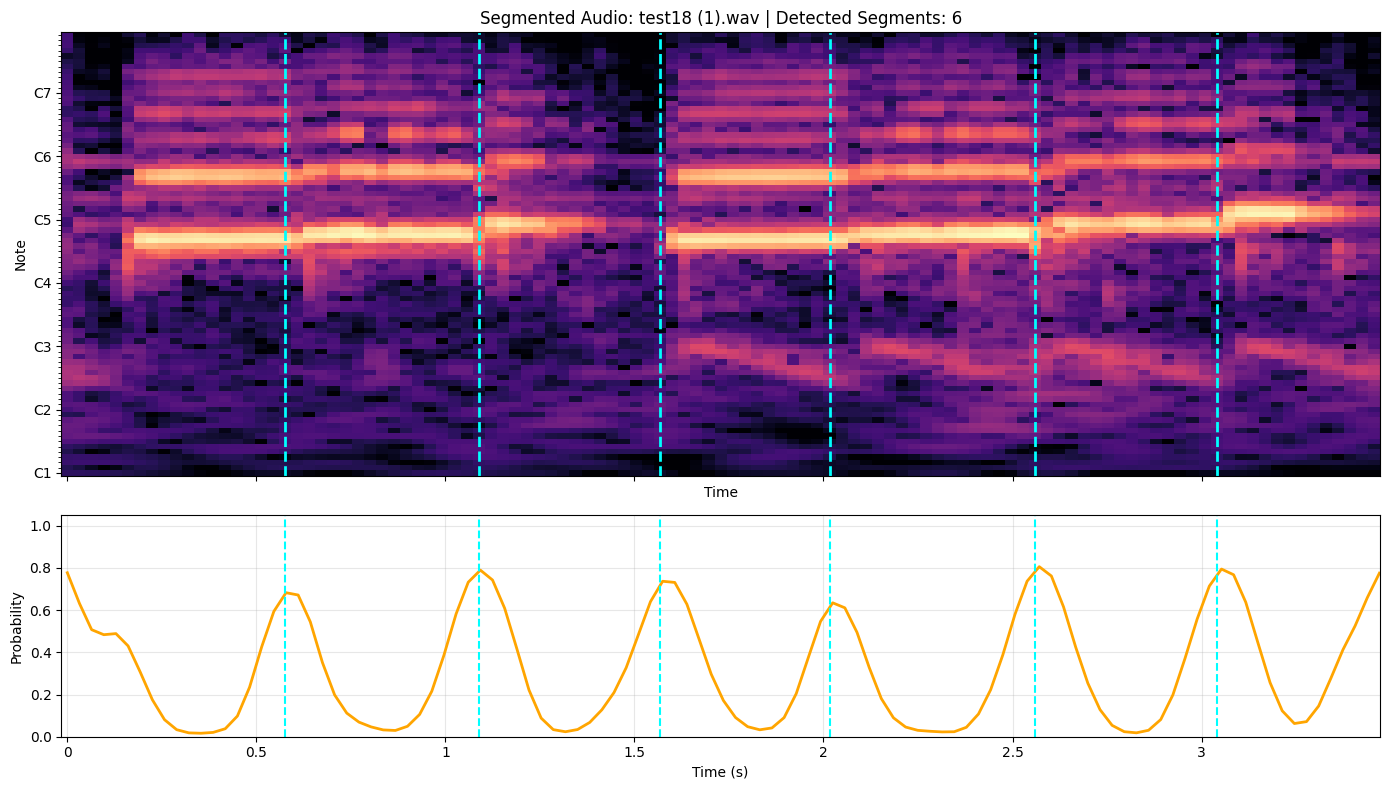

✅ Found 6 boundaries at timestamps (sec):
[0.576 1.088 1.568 2.016 2.56  3.04 ]


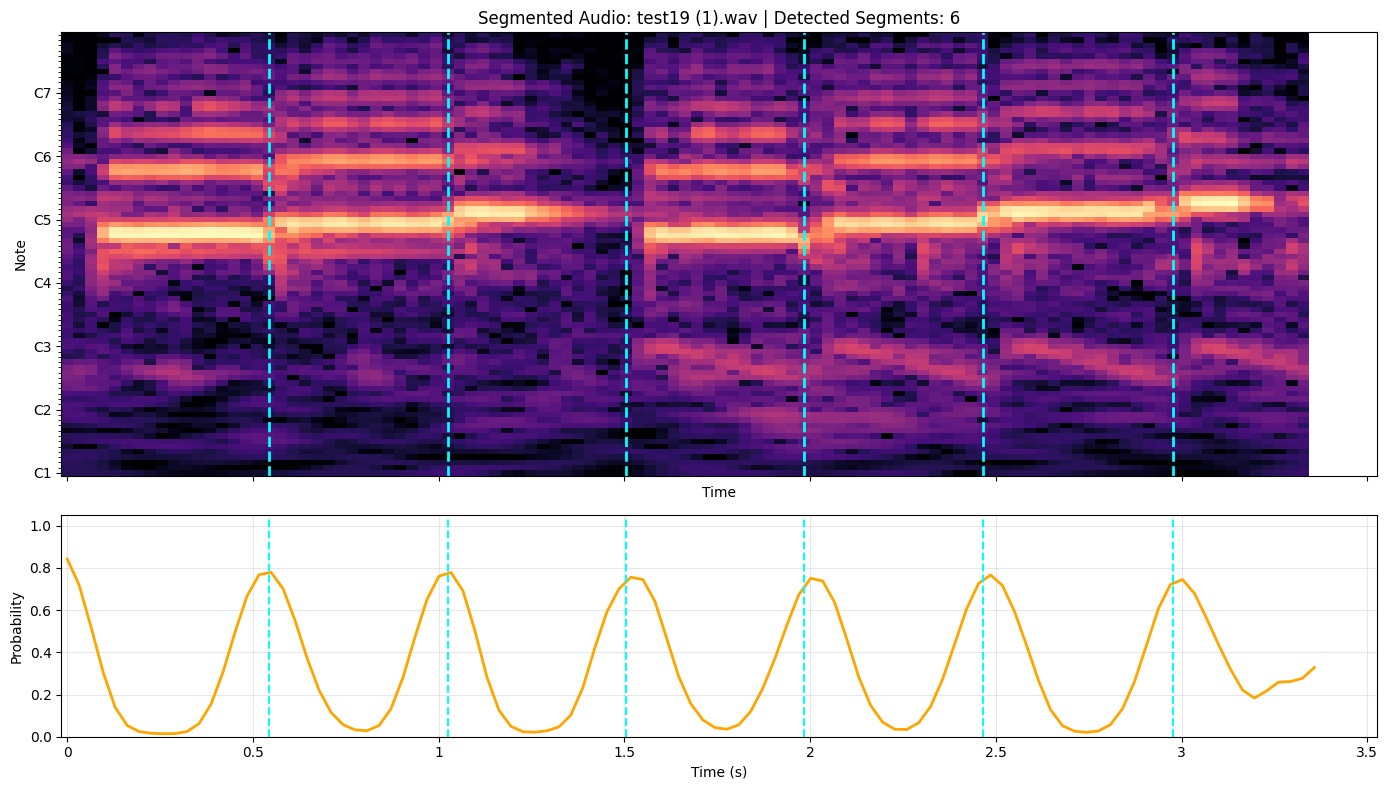

✅ Found 6 boundaries at timestamps (sec):
[0.544 1.024 1.504 1.984 2.464 2.976]


In [ ]:
def adaptive_peak_picking(preds, hop_length=512, sr=16000):
    # 1. Smooth predictions slightly to remove high-frequency jitter
    smooth_preds = gaussian_filter1d(preds, sigma=1.0)

    # 2. Compute a rolling local mean window (Adaptive Threshold)
    window_size = 15 # ~0.5 seconds window
    local_mean = np.convolve(smooth_preds, np.ones(window_size)/window_size, mode='same')

    # 3. Dynamic threshold: Peak must be higher than local average + offset
    dynamic_threshold = local_mean + 0.12

    # 4. Find peaks that stand out relative to their local neighbors
    peaks, _ = find_peaks(
        smooth_preds,
        height=dynamic_threshold,
        distance=12,         # At least ~380ms between note boundaries
        prominence=0.08      # Ensures peak stands out sharply from surrounding frames
    )

    peak_times = librosa.frames_to_time(peaks, sr=sr, hop_length=hop_length)
    return peak_times, smooth_preds

def test_and_visualize_melody(audio_path, model, config):
    model.eval()

    # 1. Load Audio and compute CQT
    y, sr = librosa.load(audio_path, sr=config['sr'])
    cqt = np.abs(librosa.cqt(y, sr=sr, hop_length=config['hop_length'],
                             n_bins=config['n_bins'], bins_per_octave=config['bins_per_octave']))
    cqt_db = librosa.amplitude_to_db(cqt, ref=np.max)
    cqt_db_norm = (cqt_db - cqt_db.min()) / (cqt_db.max() - cqt_db.min() + 1e-6)

    cqt_tensor = torch.tensor(cqt_db_norm, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(config['device'])

    # 2. Run Inference
    with torch.no_grad():
        preds = model(cqt_tensor).squeeze().cpu().numpy()

    # 3. Adaptive Segmentation
    peak_times, smooth_preds = adaptive_peak_picking(preds, hop_length=config['hop_length'], sr=config['sr'])

    # 4. Plot Spectrogram + Predictions
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

    # Top Plot: CQT Spectrogram with Segmentation Lines
    librosa.display.specshow(cqt_db, sr=config['sr'], hop_length=config['hop_length'],
                             x_axis='time', y_axis='cqt_note', ax=ax1, cmap='magma')
    ax1.set_title(f"Segmented Audio: {os.path.basename(audio_path)} | Detected Segments: {len(peak_times)}")

    for t in peak_times:
        ax1.axvline(x=t, color='cyan', linestyle='--', linewidth=2)

    # Bottom Plot: Predicted Boundary Probability Curve
    time_axis = np.linspace(0, len(y)/sr, len(smooth_preds))
    ax2.plot(time_axis, smooth_preds, label='Model Boundary Probability', color='orange', linewidth=2)
    ax2.set_ylabel("Probability")
    ax2.set_xlabel("Time (s)")
    ax2.set_ylim([0, 1.05])
    ax2.grid(True, alpha=0.3)

    for t in peak_times:
        ax2.axvline(x=t, color='cyan', linestyle='--', linewidth=1.5)

    plt.tight_layout()
    plt.show()

    print(f"✅ Found {len(peak_times)} boundaries at timestamps (sec):")
    print(np.round(peak_times, 3))

# Test on uploaded file
uploaded = files.upload()
for fn in uploaded.keys():
    test_and_visualize_melody(fn, model, CONFIG)

In [ ]:
import os
import torch

# 1. Define Drive save directory
SAVE_DIR = '/content/drive/MyDrive/crnn_flute_segmentation_checkpoint/'
os.makedirs(SAVE_DIR, exist_ok=True)

# 2. Package all essential components into a dictionary
checkpoint = {
    'epoch': CONFIG['epochs'],
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'config': CONFIG,
    'loss': avg_loss
}

# 3. Save full checkpoint for fine-tuning / complete recovery
checkpoint_path = os.path.join(SAVE_DIR, 'crnn_flute_checkpoint.pt')
torch.save(checkpoint, checkpoint_path)

# 4. Save model weights only for lightweight inference
weights_path = os.path.join(SAVE_DIR, 'crnn_flute_weights.pth')
torch.save(model.state_dict(), weights_path)

print(f"✅ Checkpoint successfully saved to:\n  -> {checkpoint_path}")
print(f"✅ Lightweight weights saved to:\n  -> {weights_path}")

✅ Checkpoint successfully saved to:
  -> /content/drive/MyDrive/crnn_flute_segmentation_checkpoint/crnn_flute_checkpoint.pt
✅ Lightweight weights saved to:
  -> /content/drive/MyDrive/crnn_flute_segmentation_checkpoint/crnn_flute_weights.pth


**Cell 1: Dataset Loader with Auto-Augmentation & Stratified Split**

In [ ]:
import os
import glob
import numpy as np
import librosa
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

# Configuration
DATASET_ROOT = '/content/drive/MyDrive/recording for paper/'
ALLOWED_CLASSES = ['sa', 're', 'ga', 'ma', 'pa', 'dha', 'ni'] # Ignores 'test'

CONFIG_CLF = {
    'sr': 16000,
    'hop_length': 512,
    'n_bins': 84,
    'bins_per_octave': 12,
    'target_duration': 2.0,  # Pad/truncate all isolated notes to 2 seconds
    'batch_size': 16,
    'epochs': 30,
    'lr': 0.0008,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu'
}

# 1. Gather all file paths and labels
file_paths = []
labels = []

swara2id = {name: i for i, name in enumerate(ALLOWED_CLASSES)}
id2swara = {i: name for i, name in enumerate(ALLOWED_CLASSES)}

for swara in ALLOWED_CLASSES:
    folder_path = os.path.join(DATASET_ROOT, swara)
    wav_files = glob.glob(os.path.join(folder_path, '*.wav'))
    for f in wav_files:
        file_paths.append(f)
        labels.append(swara2id[swara])

print(f"✅ Found {len(file_paths)} total isolated note files across {len(ALLOWED_CLASSES)} classes.")

# 2. Stratified 80/20 Train-Validation Split
train_paths, val_paths, train_labels, val_labels = train_test_split(
    file_paths, labels, test_size=0.20, random_state=42, stratify=labels
)
print(f" Training samples: {len(train_paths)} | Validation samples: {len(val_paths)}")

# 3. SpecAugment (Frequency & Time Masking)
def apply_spec_augment(cqt_norm, freq_mask_max=10, time_mask_max=12):
    augmented = cqt_norm.copy()
    num_bins, num_frames = augmented.shape

    # Freq Masking
    f_len = np.random.randint(0, freq_mask_max)
    f0 = np.random.randint(0, max(1, num_bins - f_len))
    augmented[f0:f0+f_len, :] = 0

    # Time Masking
    t_len = np.random.randint(0, time_mask_max)
    t0 = np.random.randint(0, max(1, num_frames - t_len))
    augmented[:, t0:t0+t_len] = 0

    return augmented

# 4. PyTorch Dataset
class IsolatedSwaraDataset(Dataset):
    def __init__(self, file_paths, labels, config, is_train=True):
        self.file_paths = file_paths
        self.labels = labels
        self.config = config
        self.is_train = is_train
        self.target_samples = int(config['target_duration'] * config['sr'])

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        file_path = self.file_paths[idx]
        label = self.labels[idx]

        # Load audio
        y, sr = librosa.load(file_path, sr=self.config['sr'])

        # On-the-fly Audio Augmentation for training
        if self.is_train:
            # Random Gain (Volume Jitter)
            y = y * np.random.uniform(0.8, 1.2)

            # Subtle Pitch Shift (±0.4 semitones)
            if np.random.rand() > 0.5:
                n_steps = np.random.uniform(-0.4, 0.4)
                y = librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

            # Add Gaussian Background Noise
            if np.random.rand() > 0.5:
                y = y + np.random.normal(0, 0.004, size=y.shape)

        # Pad or truncate to fixed duration
        if len(y) > self.target_samples:
            y = y[:self.target_samples]
        else:
            y = np.pad(y, (0, self.target_samples - len(y)))

        # Compute CQT
        cqt = np.abs(librosa.cqt(y, sr=sr, hop_length=self.config['hop_length'],
                                 n_bins=self.config['n_bins'],
                                 bins_per_octave=self.config['bins_per_octave']))
        cqt_db = librosa.amplitude_to_db(cqt, ref=np.max)
        cqt_norm = (cqt_db - cqt_db.min()) / (cqt_db.max() - cqt_db.min() + 1e-6)

        # SpecAugment for spectral regularization
        if self.is_train and np.random.rand() > 0.4:
            cqt_norm = apply_spec_augment(cqt_norm)

        cqt_tensor = torch.tensor(cqt_norm, dtype=torch.float32).unsqueeze(0)
        return cqt_tensor, label

train_dataset = IsolatedSwaraDataset(train_paths, train_labels, CONFIG_CLF, is_train=True)
val_dataset = IsolatedSwaraDataset(val_paths, val_labels, CONFIG_CLF, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=CONFIG_CLF['batch_size'], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG_CLF['batch_size'], shuffle=False)

✅ Found 748 total isolated note files across 7 classes.
 Training samples: 598 | Validation samples: 150


**Cell 2: CNN + Temporal Attention Classifier**

In [ ]:
class TemporalAttentionPooling(nn.Module):
    def __init__(self, in_dim):
        super(TemporalAttentionPooling, self).__init__()
        self.attn = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        # x: [Batch, Time, Features]
        attn_weights = torch.softmax(self.attn(x), dim=1)
        context = torch.sum(x * attn_weights, dim=1)
        return context

class RealSwaraClassifier(nn.Module):
    def __init__(self, n_bins=84, num_classes=7):
        super(RealSwaraClassifier, self).__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 1)),
            nn.Dropout2d(0.1),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 1)),
            nn.Dropout2d(0.2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d((2, 1)),
            nn.Dropout2d(0.2)
        )

        cnn_out_freq = n_bins // 8
        feature_dim = 128 * cnn_out_freq

        self.attention = TemporalAttentionPooling(feature_dim)

        self.fc = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        feat = self.cnn(x)
        b, c, f, t = feat.size()
        feat = feat.permute(0, 3, 1, 2).contiguous().view(b, t, c * f)
        context = self.attention(feat)
        return self.fc(context)

swara_model = RealSwaraClassifier(n_bins=CONFIG_CLF['n_bins'], num_classes=len(ALLOWED_CLASSES)).to(CONFIG_CLF['device'])

**
*Cell 3: Training & Validation Loop*
**


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(swara_model.parameters(), lr=CONFIG_CLF['lr'], weight_decay=1e-4)

best_val_acc = 0.0

for epoch in range(CONFIG_CLF['epochs']):
    # --- TRAINING ---
    swara_model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{CONFIG_CLF['epochs']}", leave=False)
    for cqts, labels in pbar:
        cqts, labels = cqts.to(CONFIG_CLF['device']), labels.to(CONFIG_CLF['device'])

        optimizer.zero_grad()
        outputs = swara_model(cqts)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, preds = outputs.max(1)
        train_total += labels.size(0)
        train_correct += preds.eq(labels).sum().item()

        pbar.set_postfix({'loss': f"{loss.item():.4f}"})

    train_acc = 100.0 * train_correct / train_total

    # --- VALIDATION ---
    swara_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for cqts, labels in val_loader:
            cqts, labels = cqts.to(CONFIG_CLF['device']), labels.to(CONFIG_CLF['device'])
            outputs = swara_model(cqts)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, preds = outputs.max(1)
            val_total += labels.size(0)
            val_correct += preds.eq(labels).sum().item()

    val_acc = 100.0 * val_correct / val_total

    # Save Best Model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        save_path = '/content/drive/MyDrive/recording for paper/best_swara_classifier.pth'
        torch.save(swara_model.state_dict(), save_path)
        saved_str = "⭐ Best Model Saved!"
    else:
        saved_str = ""

    print(f"Epoch [{epoch+1:02d}/{CONFIG_CLF['epochs']}] | Train Acc: {train_acc:.1f}% | Val Acc: {val_acc:.1f}% {saved_str}")

print(f"\n🎉 Training Finished! Best Validation Accuracy: {best_val_acc:.2f}%")

Epoch 1/30:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch [01/30] | Train Acc: 18.7% | Val Acc: 19.3% ⭐ Best Model Saved!


Epoch 2/30:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch [02/30] | Train Acc: 28.8% | Val Acc: 41.3% ⭐ Best Model Saved!


Epoch 3/30:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch [03/30] | Train Acc: 46.3% | Val Acc: 56.7% ⭐ Best Model Saved!


... (50 outputs left out)

Epoch 29/30:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch [29/30] | Train Acc: 94.5% | Val Acc: 99.3% 


Epoch 30/30:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch [30/30] | Train Acc: 94.6% | Val Acc: 99.3% 

🎉 Training Finished! Best Validation Accuracy: 99.33%


**Complete End-to-End Merged Pipeline Cell**

✅ Loaded Segmentation Model weights.
✅ Loaded Swara Classifier Model weights.
Upload a test melody (.wav) file to run full segmentation + classification:


Saving test1.wav to test1 (3).wav
Saving test2.wav to test2 (3).wav
Saving test3.wav to test3 (3).wav
Saving test4.wav to test4 (3).wav
Saving test5.wav to test5 (3).wav
Saving test6.wav to test6 (3).wav
Saving test7.wav to test7 (3).wav
Saving test8.wav to test8 (3).wav
Saving test9.wav to test9 (3).wav
Saving test10.wav to test10 (3).wav
Saving test11.wav to test11 (3).wav
Saving test12.wav to test12 (3).wav
Saving test13.wav to test13 (3).wav
Saving test14.wav to test14 (3).wav
Saving test15.wav to test15 (2).wav
Saving test16.wav to test16 (2).wav
Saving test17.wav to test17 (2).wav
Saving test18.wav to test18 (2).wav
Saving test19.wav to test19 (2).wav


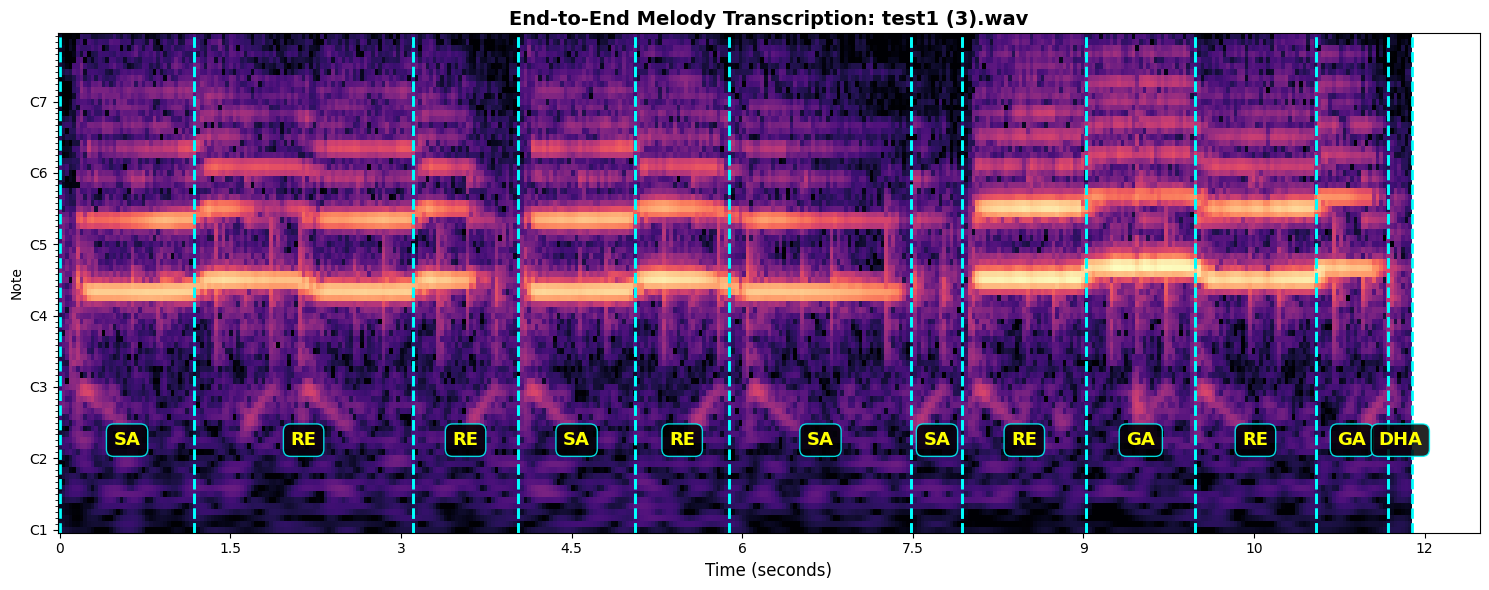


  AUDIO TRANSCRIPTION SUMMARY (12 Notes Detected)
 Segment 01 | [ 0.00s ➔  1.18s] | Predicted Swara: SA
 Segment 02 | [ 1.18s ➔  3.10s] | Predicted Swara: RE
 Segment 03 | [ 3.10s ➔  4.03s] | Predicted Swara: RE
 Segment 04 | [ 4.03s ➔  5.06s] | Predicted Swara: SA
 Segment 05 | [ 5.06s ➔  5.89s] | Predicted Swara: RE
 Segment 06 | [ 5.89s ➔  7.49s] | Predicted Swara: SA
 Segment 07 | [ 7.49s ➔  7.94s] | Predicted Swara: SA
 Segment 08 | [ 7.94s ➔  9.02s] | Predicted Swara: RE
 Segment 09 | [ 9.02s ➔  9.98s] | Predicted Swara: GA
 Segment 10 | [ 9.98s ➔ 11.04s] | Predicted Swara: RE
 Segment 11 | [11.04s ➔ 11.68s] | Predicted Swara: GA
 Segment 12 | [11.68s ➔ 11.89s] | Predicted Swara: DHA



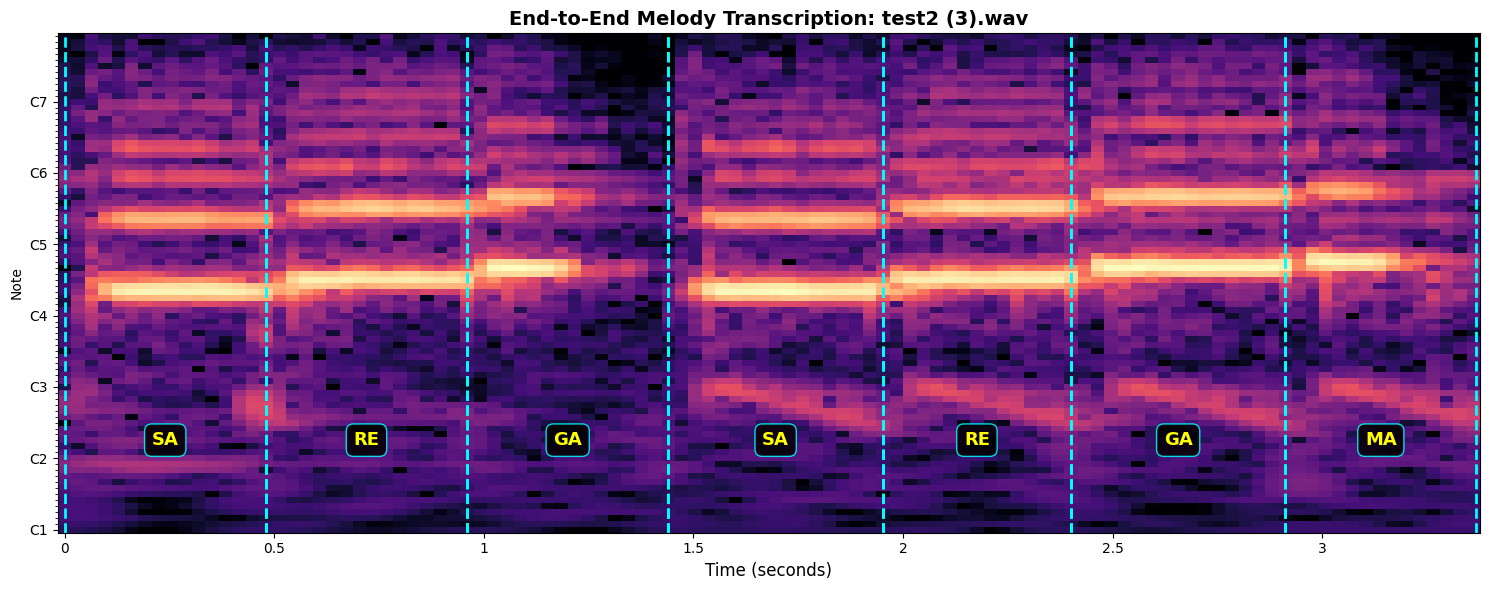


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.48s] | Predicted Swara: SA
 Segment 02 | [ 0.48s ➔  0.96s] | Predicted Swara: RE
 Segment 03 | [ 0.96s ➔  1.44s] | Predicted Swara: GA
 Segment 04 | [ 1.44s ➔  1.95s] | Predicted Swara: SA
 Segment 05 | [ 1.95s ➔  2.40s] | Predicted Swara: RE
 Segment 06 | [ 2.40s ➔  2.91s] | Predicted Swara: GA
 Segment 07 | [ 2.91s ➔  3.37s] | Predicted Swara: MA



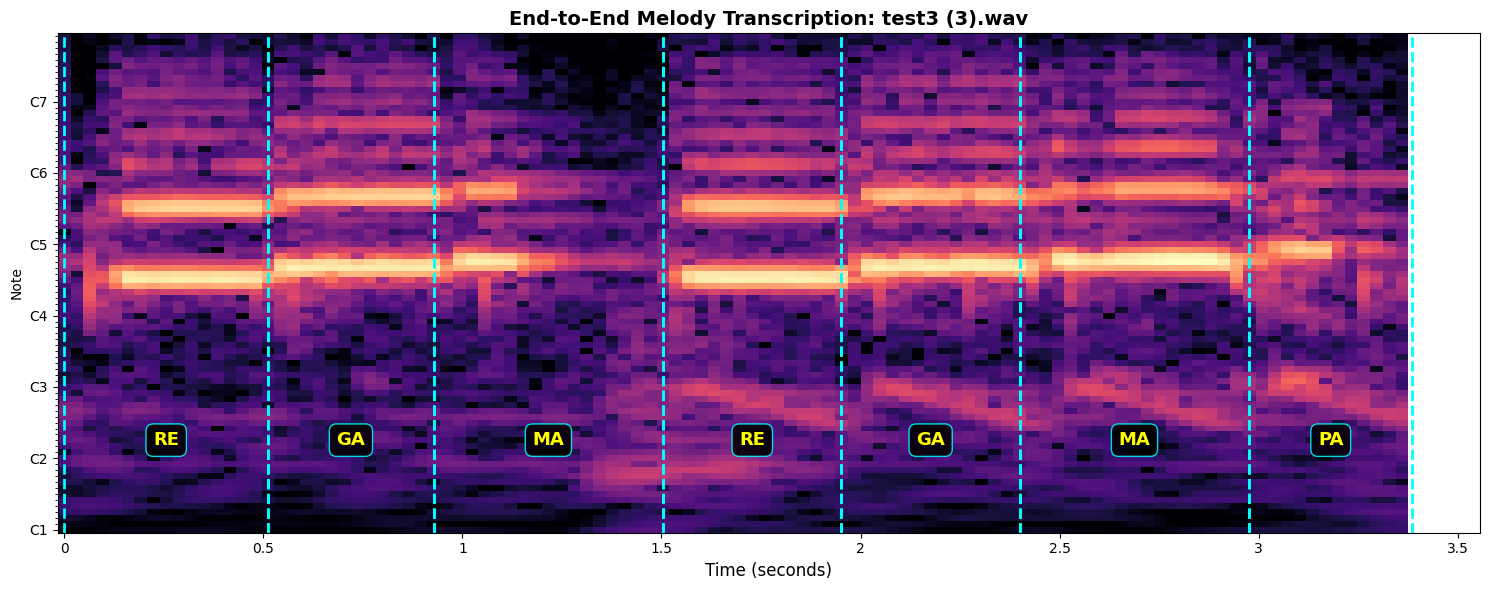


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.51s] | Predicted Swara: RE
 Segment 02 | [ 0.51s ➔  0.93s] | Predicted Swara: GA
 Segment 03 | [ 0.93s ➔  1.50s] | Predicted Swara: MA
 Segment 04 | [ 1.50s ➔  1.95s] | Predicted Swara: RE
 Segment 05 | [ 1.95s ➔  2.40s] | Predicted Swara: GA
 Segment 06 | [ 2.40s ➔  2.98s] | Predicted Swara: MA
 Segment 07 | [ 2.98s ➔  3.39s] | Predicted Swara: PA



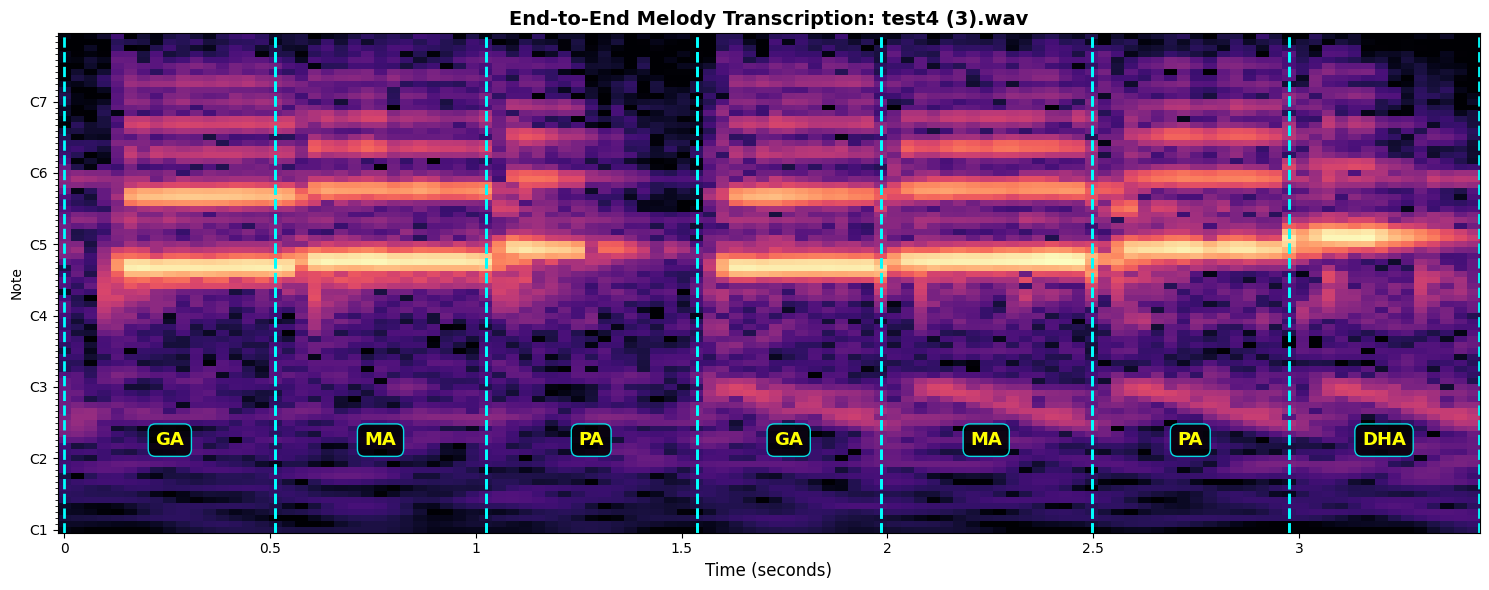


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.51s] | Predicted Swara: GA
 Segment 02 | [ 0.51s ➔  1.02s] | Predicted Swara: MA
 Segment 03 | [ 1.02s ➔  1.54s] | Predicted Swara: PA
 Segment 04 | [ 1.54s ➔  1.98s] | Predicted Swara: GA
 Segment 05 | [ 1.98s ➔  2.50s] | Predicted Swara: MA
 Segment 06 | [ 2.50s ➔  2.98s] | Predicted Swara: PA
 Segment 07 | [ 2.98s ➔  3.44s] | Predicted Swara: DHA



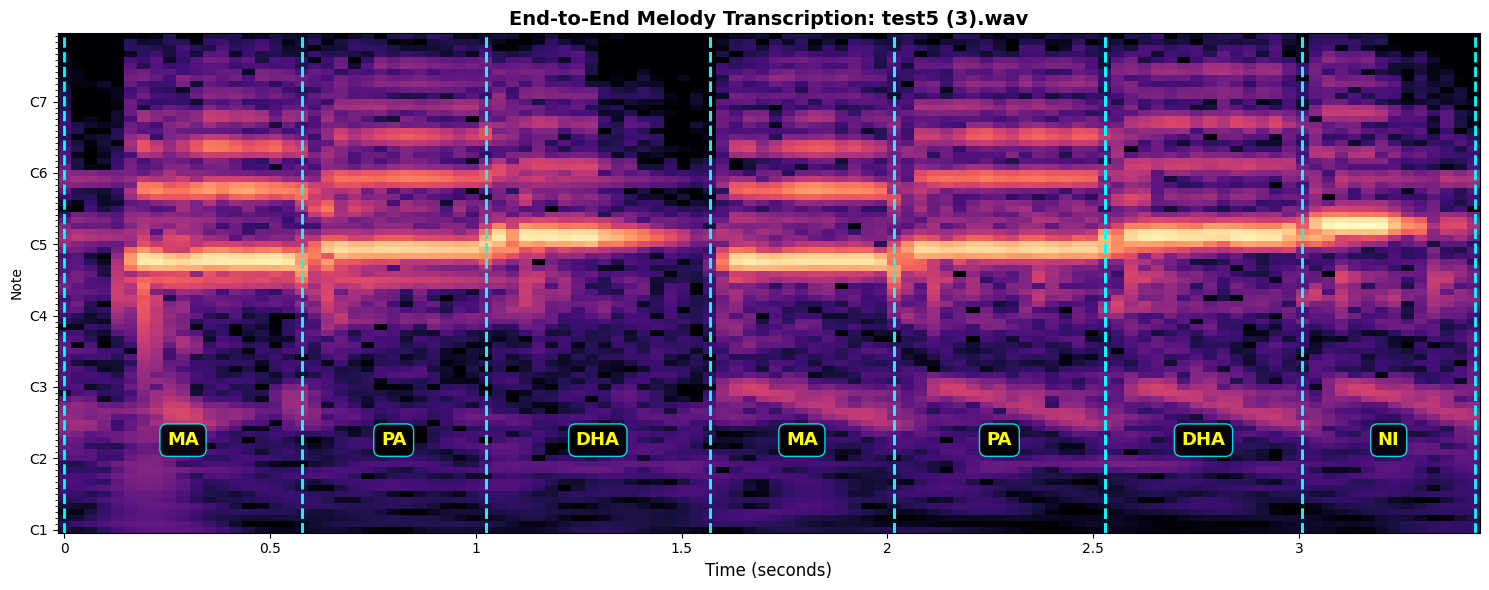


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.58s] | Predicted Swara: MA
 Segment 02 | [ 0.58s ➔  1.02s] | Predicted Swara: PA
 Segment 03 | [ 1.02s ➔  1.57s] | Predicted Swara: DHA
 Segment 04 | [ 1.57s ➔  2.02s] | Predicted Swara: MA
 Segment 05 | [ 2.02s ➔  2.53s] | Predicted Swara: PA
 Segment 06 | [ 2.53s ➔  3.01s] | Predicted Swara: DHA
 Segment 07 | [ 3.01s ➔  3.43s] | Predicted Swara: NI



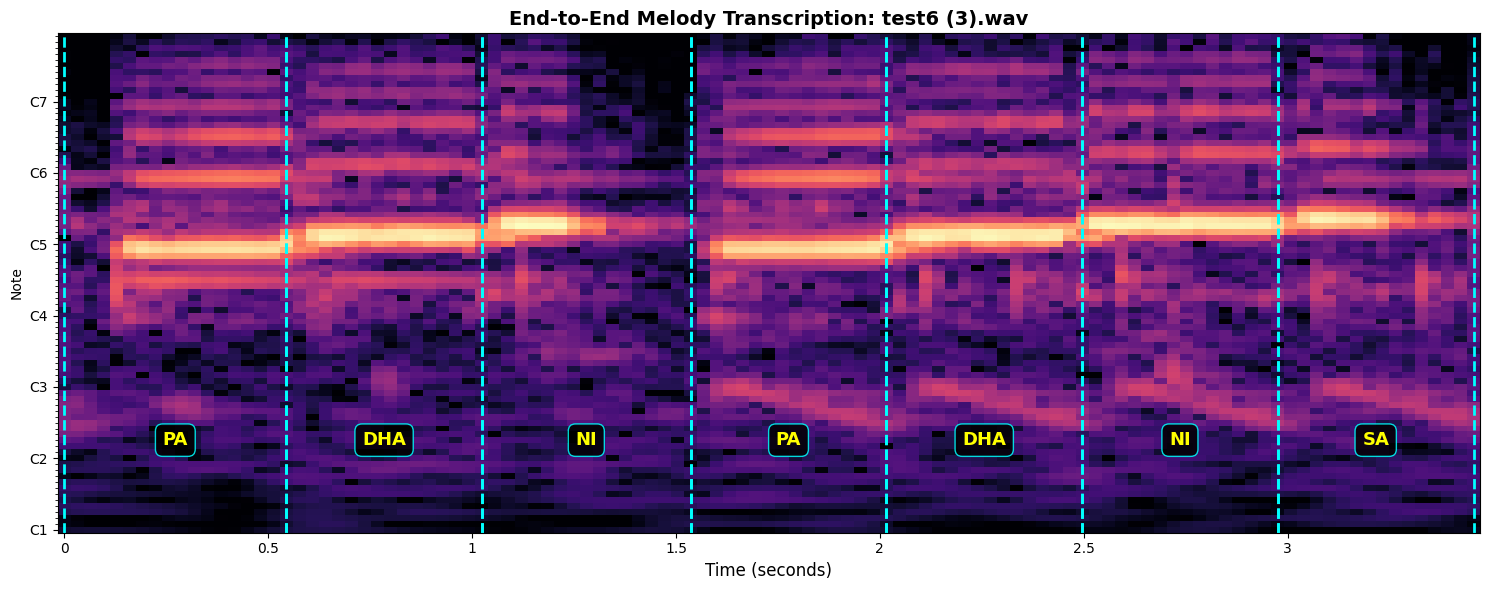


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.54s] | Predicted Swara: PA
 Segment 02 | [ 0.54s ➔  1.02s] | Predicted Swara: DHA
 Segment 03 | [ 1.02s ➔  1.54s] | Predicted Swara: NI
 Segment 04 | [ 1.54s ➔  2.02s] | Predicted Swara: PA
 Segment 05 | [ 2.02s ➔  2.50s] | Predicted Swara: DHA
 Segment 06 | [ 2.50s ➔  2.98s] | Predicted Swara: NI
 Segment 07 | [ 2.98s ➔  3.46s] | Predicted Swara: SA



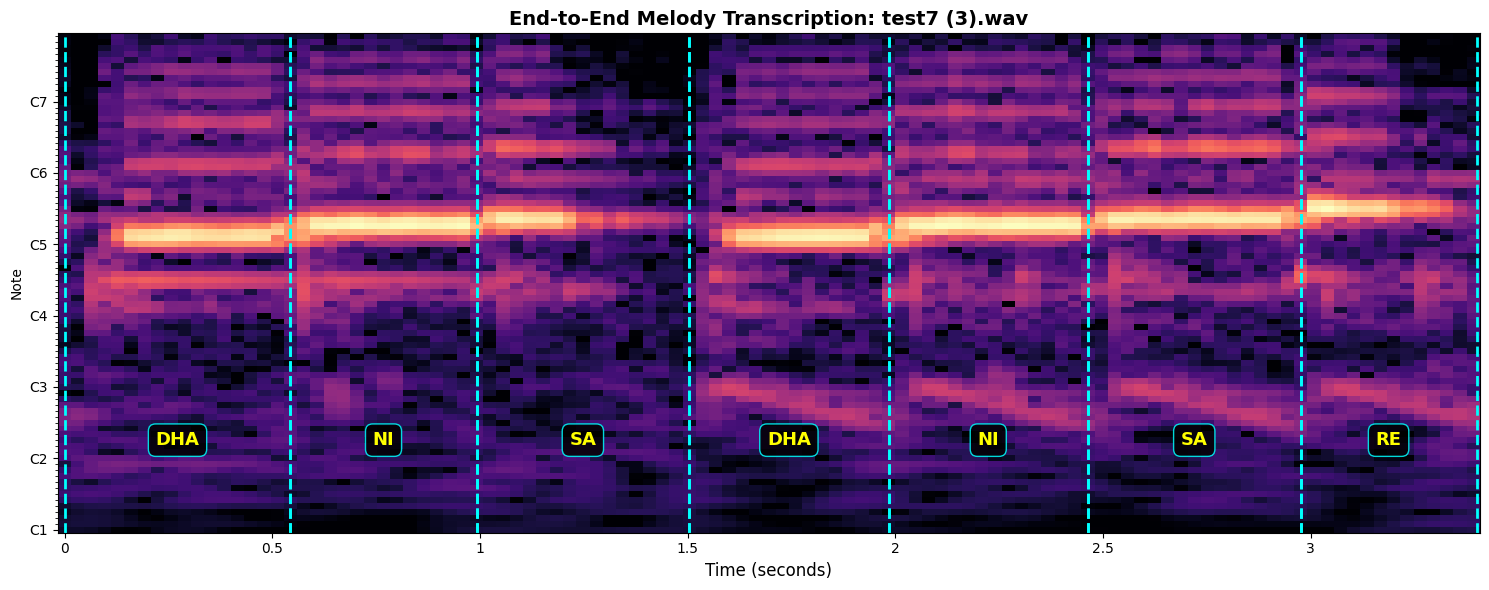


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.54s] | Predicted Swara: DHA
 Segment 02 | [ 0.54s ➔  0.99s] | Predicted Swara: NI
 Segment 03 | [ 0.99s ➔  1.50s] | Predicted Swara: SA
 Segment 04 | [ 1.50s ➔  1.98s] | Predicted Swara: DHA
 Segment 05 | [ 1.98s ➔  2.46s] | Predicted Swara: NI
 Segment 06 | [ 2.46s ➔  2.98s] | Predicted Swara: SA
 Segment 07 | [ 2.98s ➔  3.40s] | Predicted Swara: RE



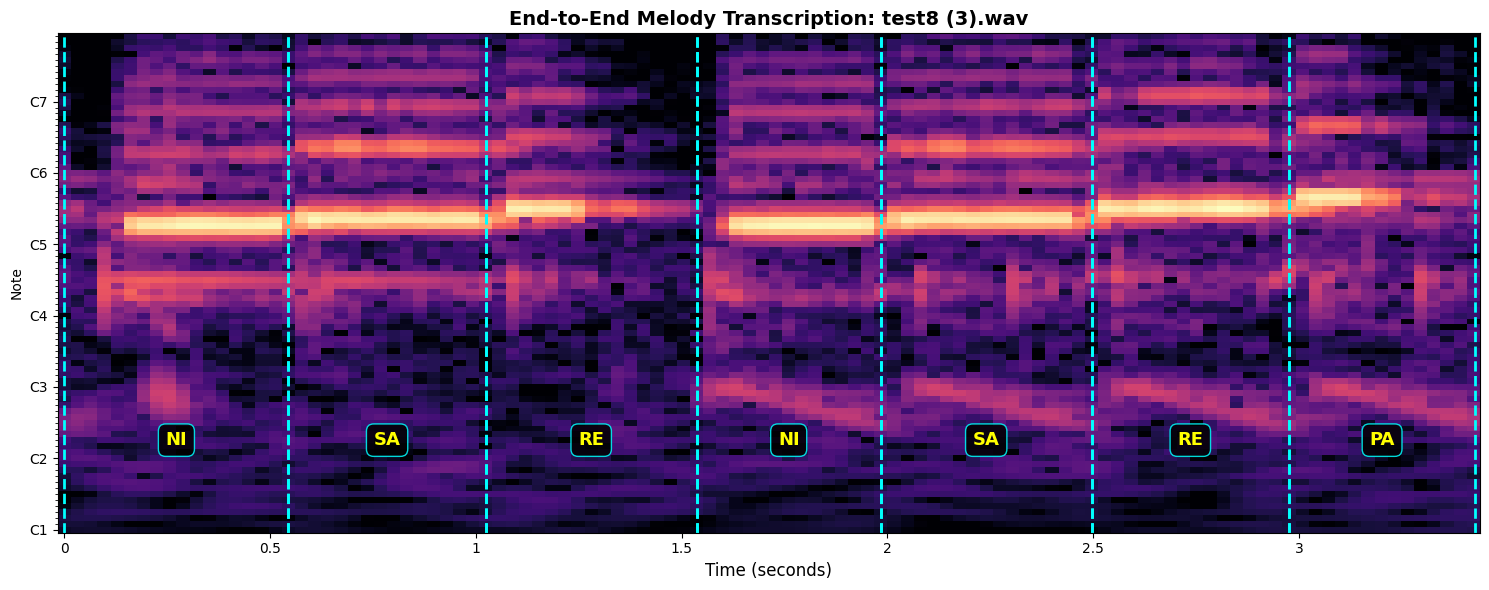


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.54s] | Predicted Swara: NI
 Segment 02 | [ 0.54s ➔  1.02s] | Predicted Swara: SA
 Segment 03 | [ 1.02s ➔  1.54s] | Predicted Swara: RE
 Segment 04 | [ 1.54s ➔  1.98s] | Predicted Swara: NI
 Segment 05 | [ 1.98s ➔  2.50s] | Predicted Swara: SA
 Segment 06 | [ 2.50s ➔  2.98s] | Predicted Swara: RE
 Segment 07 | [ 2.98s ➔  3.43s] | Predicted Swara: PA



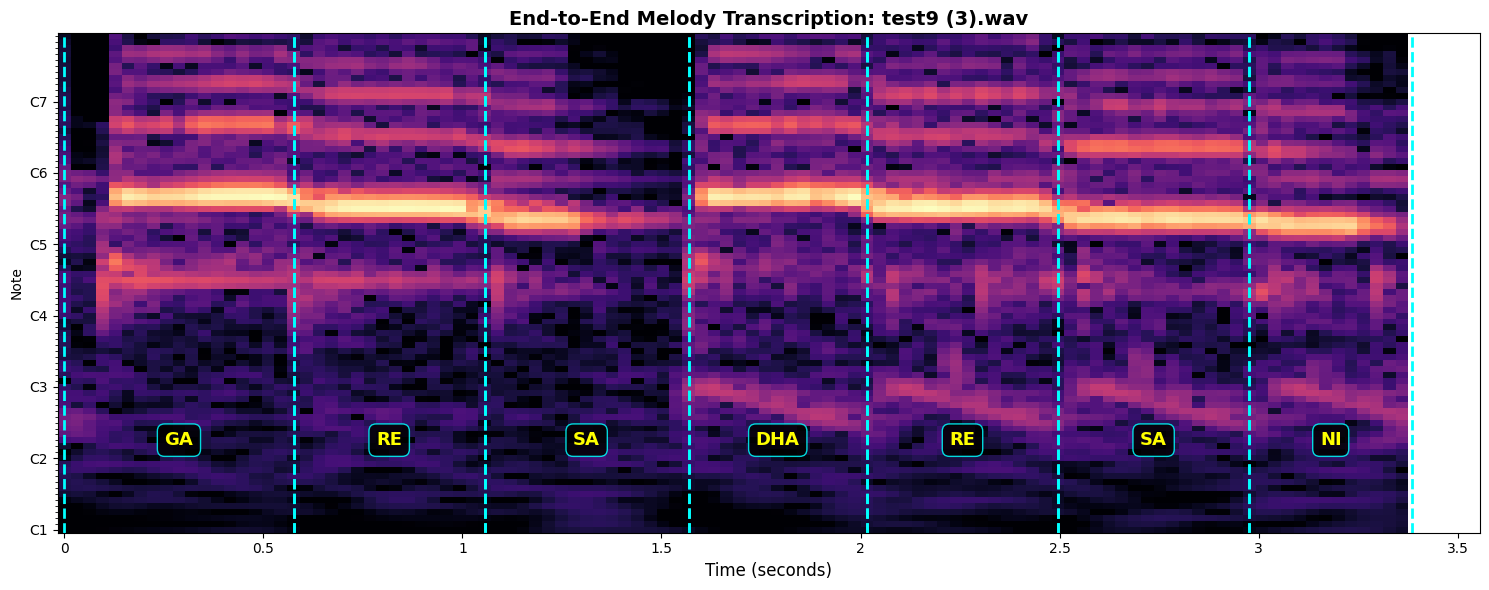


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.58s] | Predicted Swara: GA
 Segment 02 | [ 0.58s ➔  1.06s] | Predicted Swara: RE
 Segment 03 | [ 1.06s ➔  1.57s] | Predicted Swara: SA
 Segment 04 | [ 1.57s ➔  2.02s] | Predicted Swara: DHA
 Segment 05 | [ 2.02s ➔  2.50s] | Predicted Swara: RE
 Segment 06 | [ 2.50s ➔  2.98s] | Predicted Swara: SA
 Segment 07 | [ 2.98s ➔  3.39s] | Predicted Swara: NI



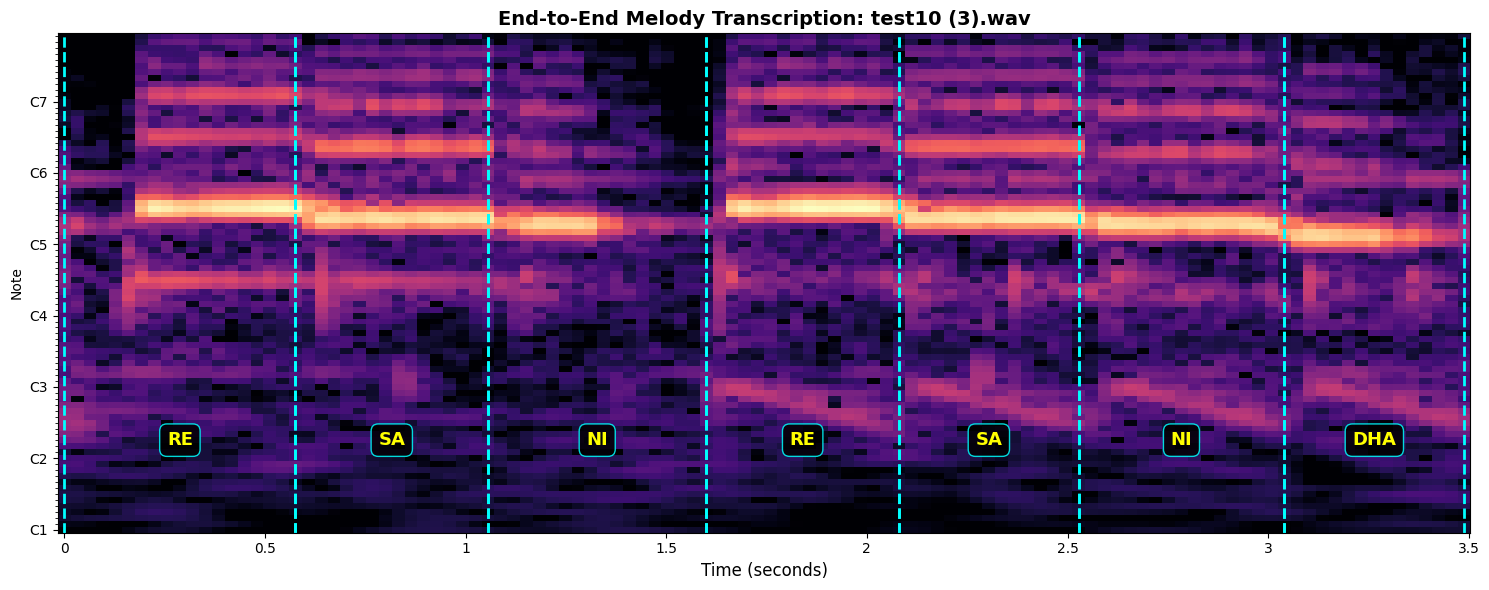


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.58s] | Predicted Swara: RE
 Segment 02 | [ 0.58s ➔  1.06s] | Predicted Swara: SA
 Segment 03 | [ 1.06s ➔  1.60s] | Predicted Swara: NI
 Segment 04 | [ 1.60s ➔  2.08s] | Predicted Swara: RE
 Segment 05 | [ 2.08s ➔  2.53s] | Predicted Swara: SA
 Segment 06 | [ 2.53s ➔  3.04s] | Predicted Swara: NI
 Segment 07 | [ 3.04s ➔  3.49s] | Predicted Swara: DHA



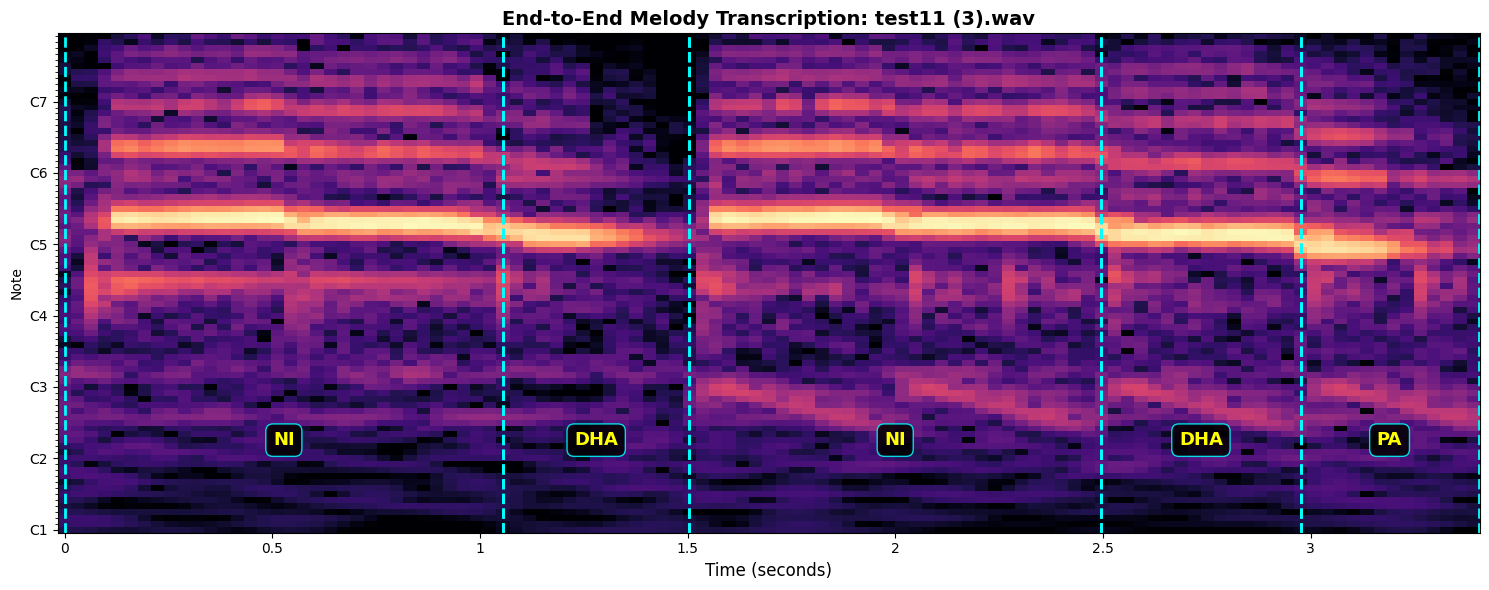


  AUDIO TRANSCRIPTION SUMMARY (5 Notes Detected)
 Segment 01 | [ 0.00s ➔  1.06s] | Predicted Swara: NI
 Segment 02 | [ 1.06s ➔  1.50s] | Predicted Swara: DHA
 Segment 03 | [ 1.50s ➔  2.50s] | Predicted Swara: NI
 Segment 04 | [ 2.50s ➔  2.98s] | Predicted Swara: DHA
 Segment 05 | [ 2.98s ➔  3.40s] | Predicted Swara: PA



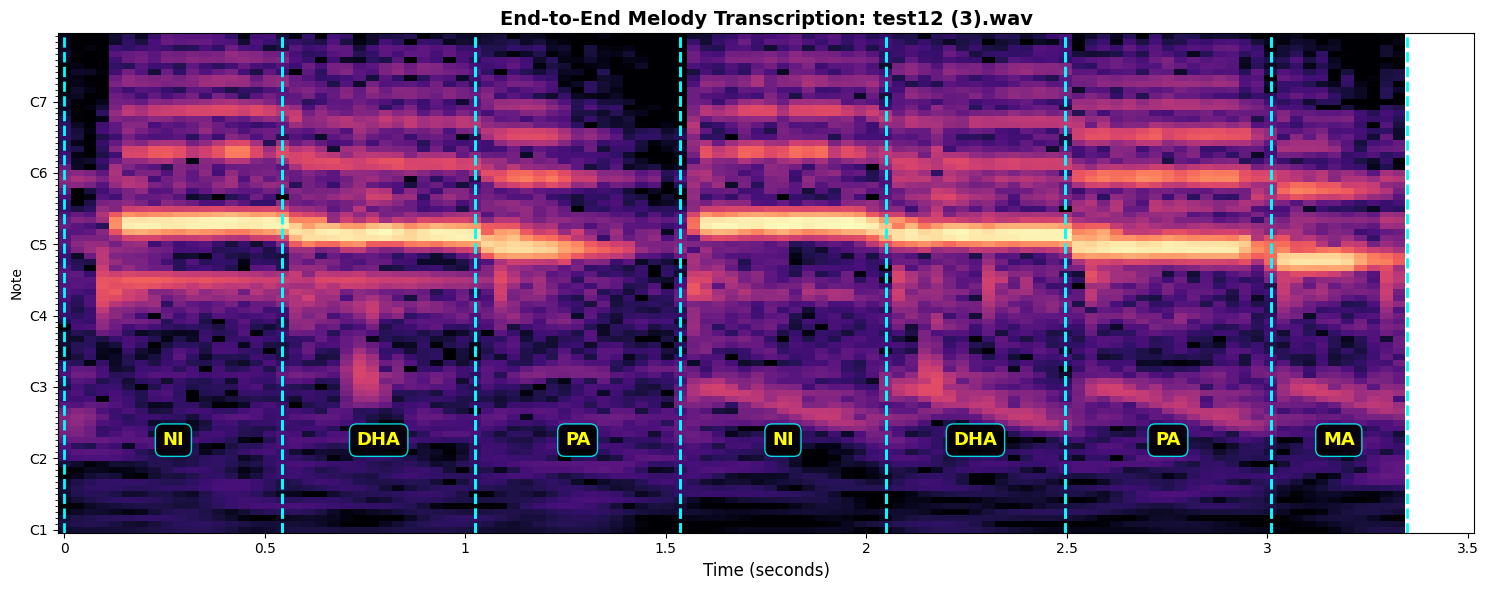


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.54s] | Predicted Swara: NI
 Segment 02 | [ 0.54s ➔  1.02s] | Predicted Swara: DHA
 Segment 03 | [ 1.02s ➔  1.54s] | Predicted Swara: PA
 Segment 04 | [ 1.54s ➔  2.05s] | Predicted Swara: NI
 Segment 05 | [ 2.05s ➔  2.50s] | Predicted Swara: DHA
 Segment 06 | [ 2.50s ➔  3.01s] | Predicted Swara: PA
 Segment 07 | [ 3.01s ➔  3.35s] | Predicted Swara: MA



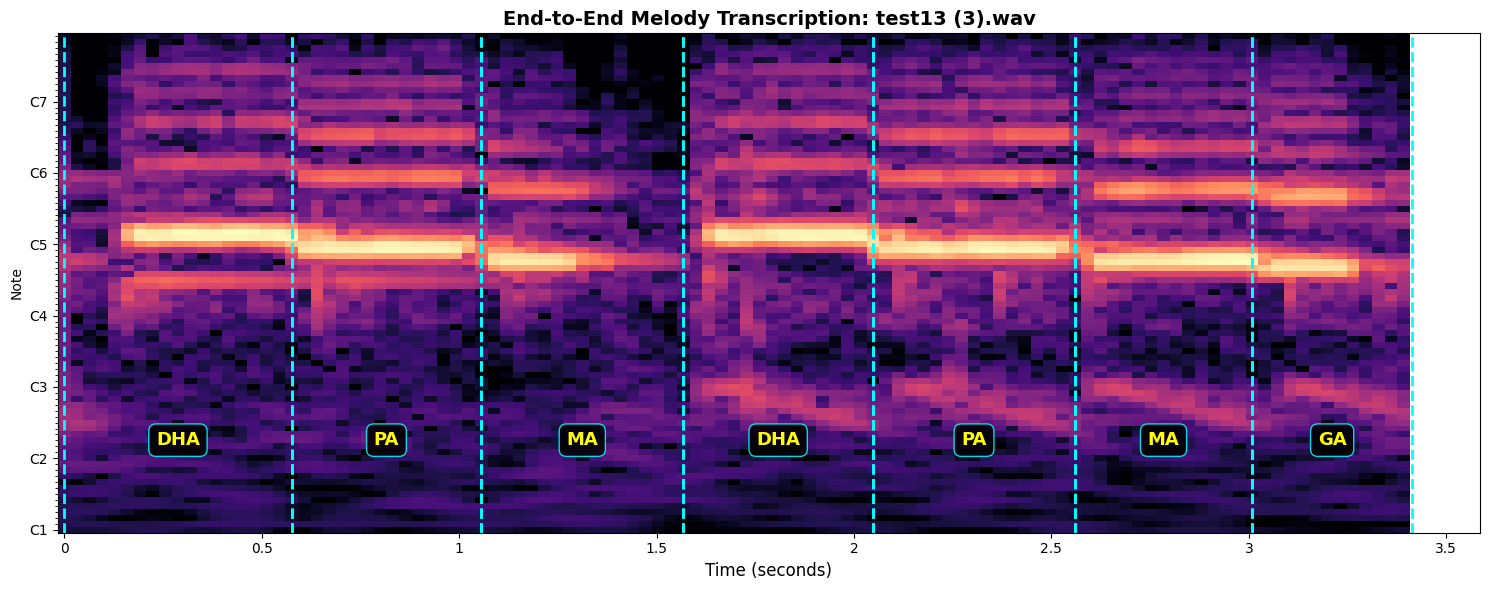


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.58s] | Predicted Swara: DHA
 Segment 02 | [ 0.58s ➔  1.06s] | Predicted Swara: PA
 Segment 03 | [ 1.06s ➔  1.57s] | Predicted Swara: MA
 Segment 04 | [ 1.57s ➔  2.05s] | Predicted Swara: DHA
 Segment 05 | [ 2.05s ➔  2.56s] | Predicted Swara: PA
 Segment 06 | [ 2.56s ➔  3.01s] | Predicted Swara: MA
 Segment 07 | [ 3.01s ➔  3.41s] | Predicted Swara: GA



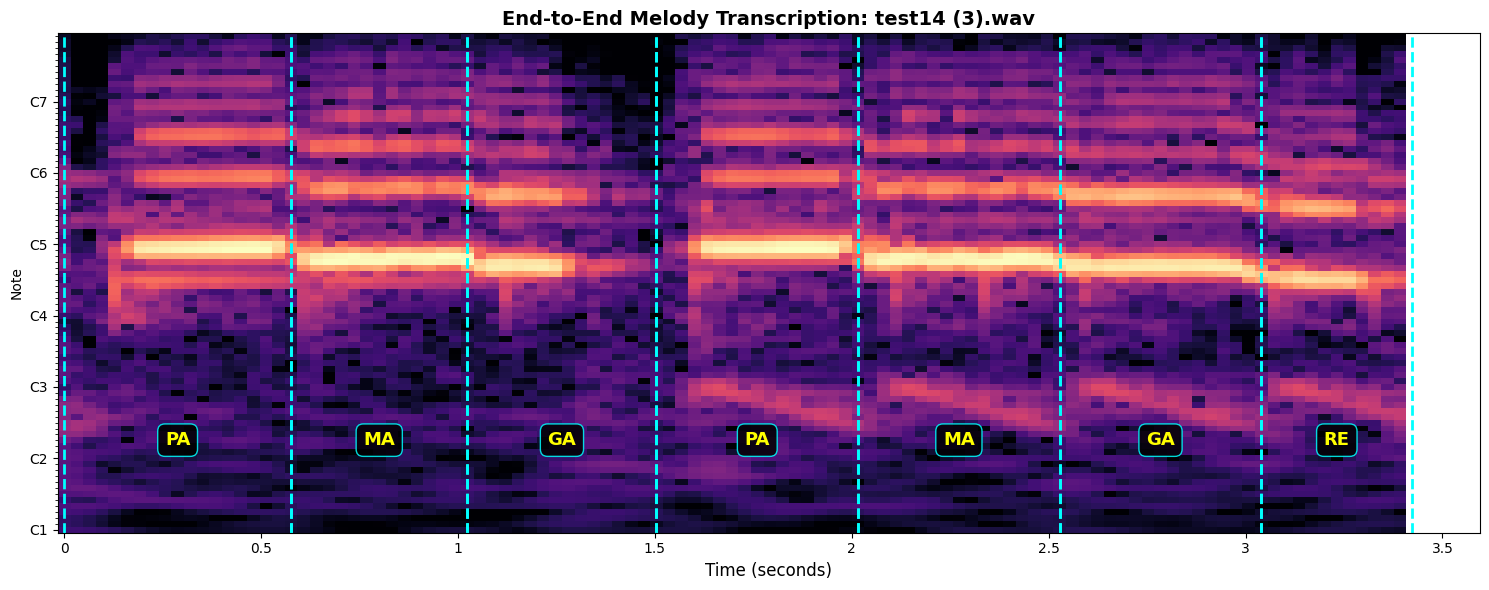


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.58s] | Predicted Swara: PA
 Segment 02 | [ 0.58s ➔  1.02s] | Predicted Swara: MA
 Segment 03 | [ 1.02s ➔  1.50s] | Predicted Swara: GA
 Segment 04 | [ 1.50s ➔  2.02s] | Predicted Swara: PA
 Segment 05 | [ 2.02s ➔  2.53s] | Predicted Swara: MA
 Segment 06 | [ 2.53s ➔  3.04s] | Predicted Swara: GA
 Segment 07 | [ 3.04s ➔  3.42s] | Predicted Swara: RE



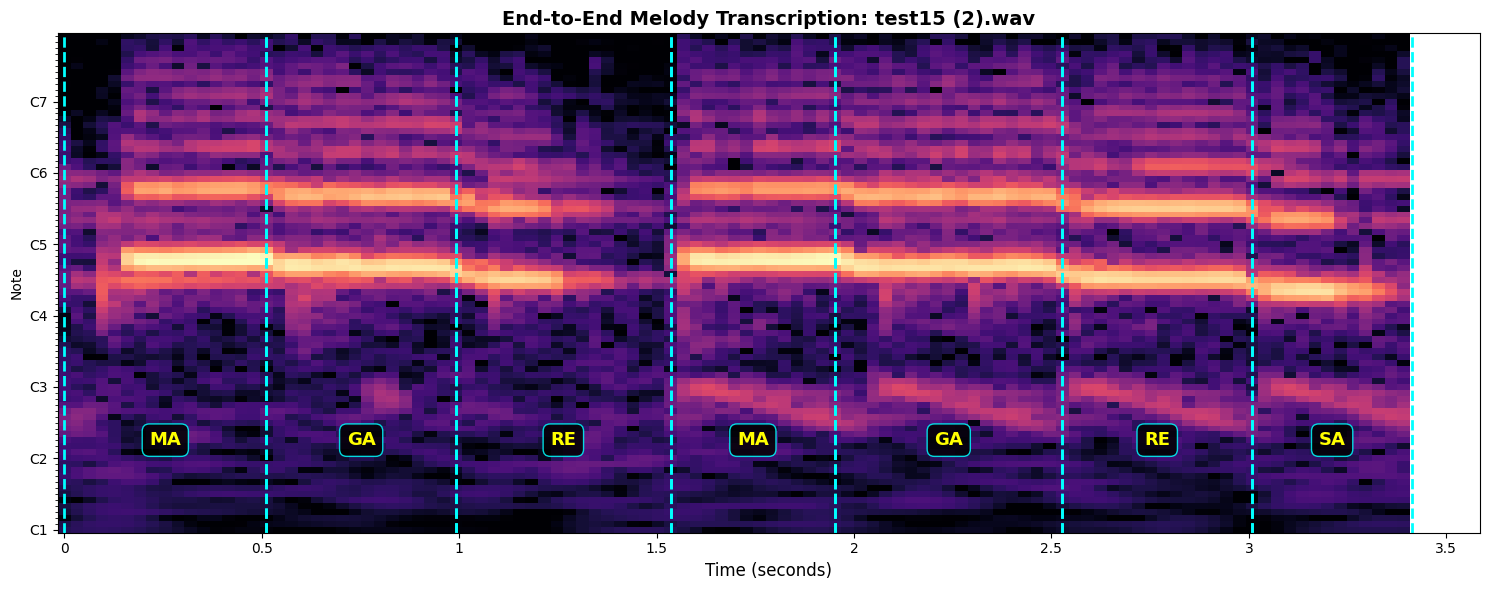


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.51s] | Predicted Swara: MA
 Segment 02 | [ 0.51s ➔  0.99s] | Predicted Swara: GA
 Segment 03 | [ 0.99s ➔  1.54s] | Predicted Swara: RE
 Segment 04 | [ 1.54s ➔  1.95s] | Predicted Swara: MA
 Segment 05 | [ 1.95s ➔  2.53s] | Predicted Swara: GA
 Segment 06 | [ 2.53s ➔  3.01s] | Predicted Swara: RE
 Segment 07 | [ 3.01s ➔  3.41s] | Predicted Swara: SA



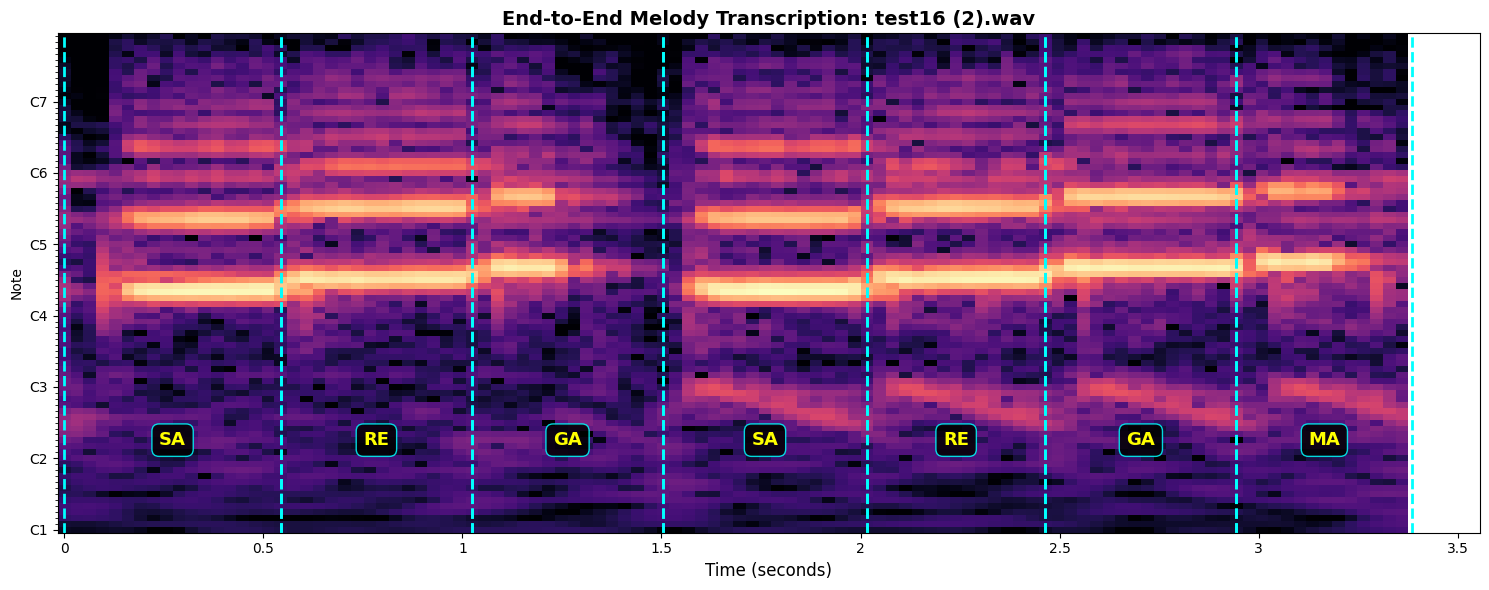


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.54s] | Predicted Swara: SA
 Segment 02 | [ 0.54s ➔  1.02s] | Predicted Swara: RE
 Segment 03 | [ 1.02s ➔  1.50s] | Predicted Swara: GA
 Segment 04 | [ 1.50s ➔  2.02s] | Predicted Swara: SA
 Segment 05 | [ 2.02s ➔  2.46s] | Predicted Swara: RE
 Segment 06 | [ 2.46s ➔  2.94s] | Predicted Swara: GA
 Segment 07 | [ 2.94s ➔  3.39s] | Predicted Swara: MA



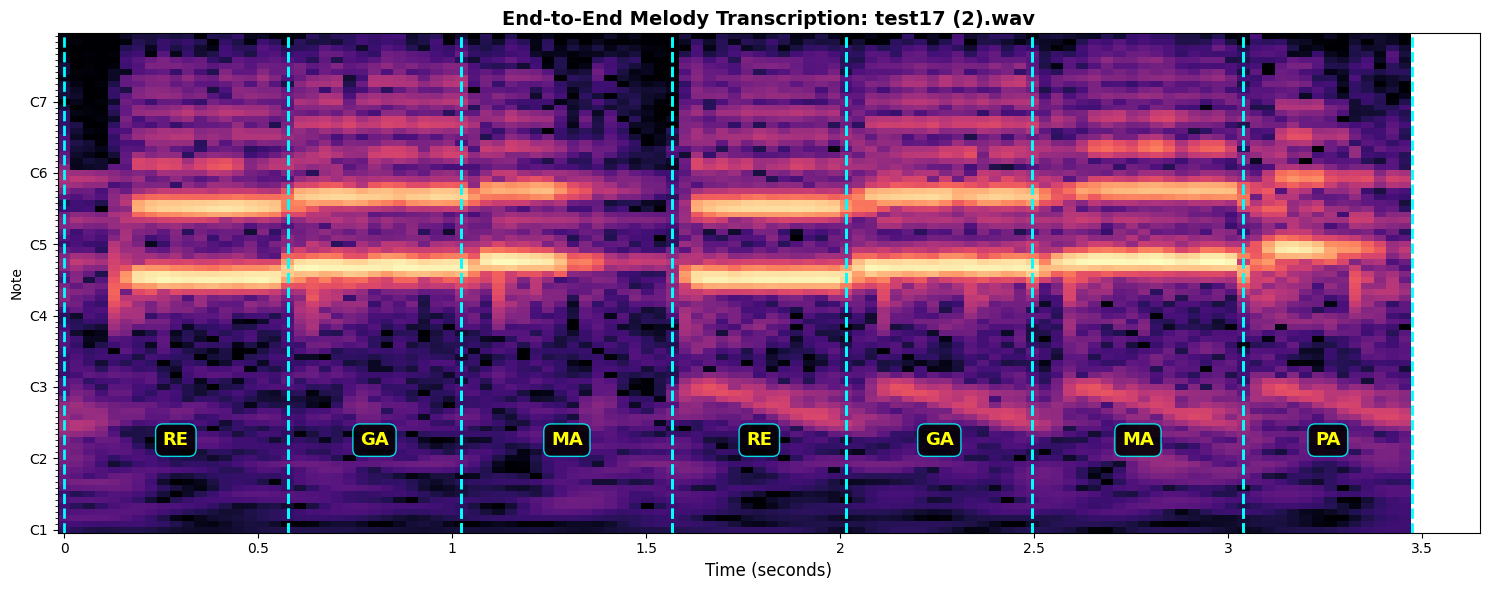


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.58s] | Predicted Swara: RE
 Segment 02 | [ 0.58s ➔  1.02s] | Predicted Swara: GA
 Segment 03 | [ 1.02s ➔  1.57s] | Predicted Swara: MA
 Segment 04 | [ 1.57s ➔  2.02s] | Predicted Swara: RE
 Segment 05 | [ 2.02s ➔  2.50s] | Predicted Swara: GA
 Segment 06 | [ 2.50s ➔  3.04s] | Predicted Swara: MA
 Segment 07 | [ 3.04s ➔  3.48s] | Predicted Swara: PA



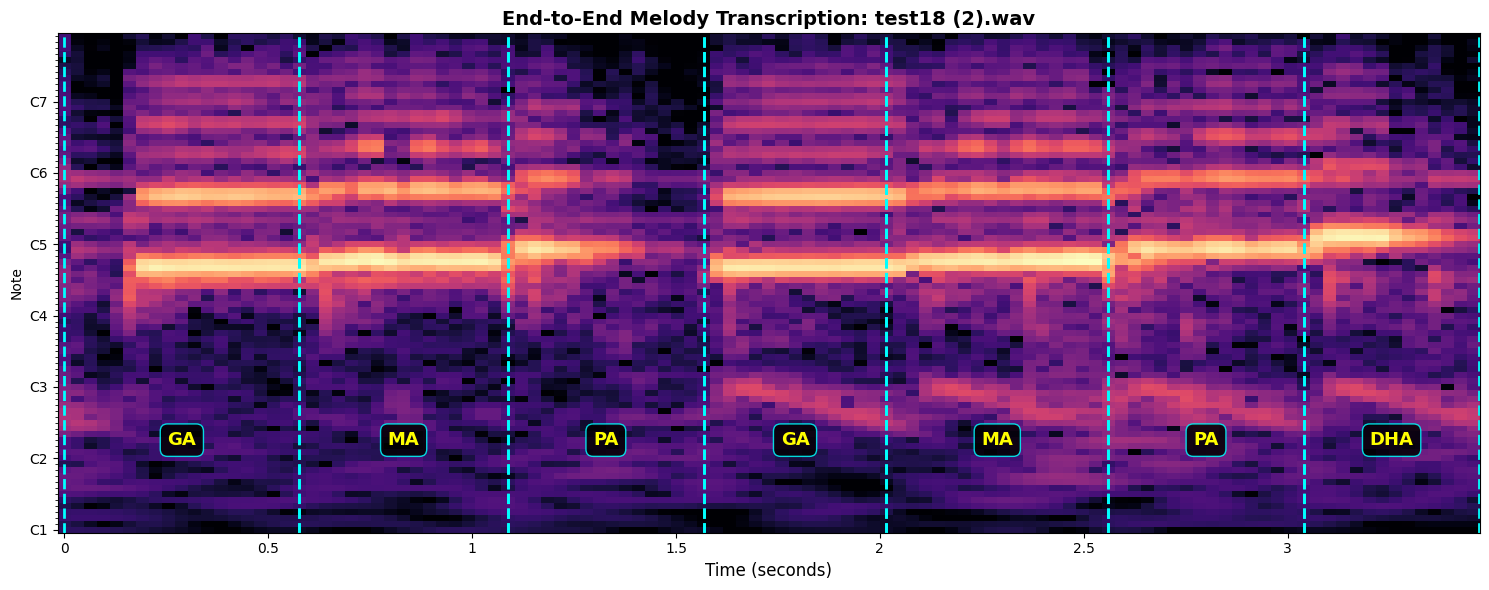


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.58s] | Predicted Swara: GA
 Segment 02 | [ 0.58s ➔  1.09s] | Predicted Swara: MA
 Segment 03 | [ 1.09s ➔  1.57s] | Predicted Swara: PA
 Segment 04 | [ 1.57s ➔  2.02s] | Predicted Swara: GA
 Segment 05 | [ 2.02s ➔  2.56s] | Predicted Swara: MA
 Segment 06 | [ 2.56s ➔  3.04s] | Predicted Swara: PA
 Segment 07 | [ 3.04s ➔  3.47s] | Predicted Swara: DHA



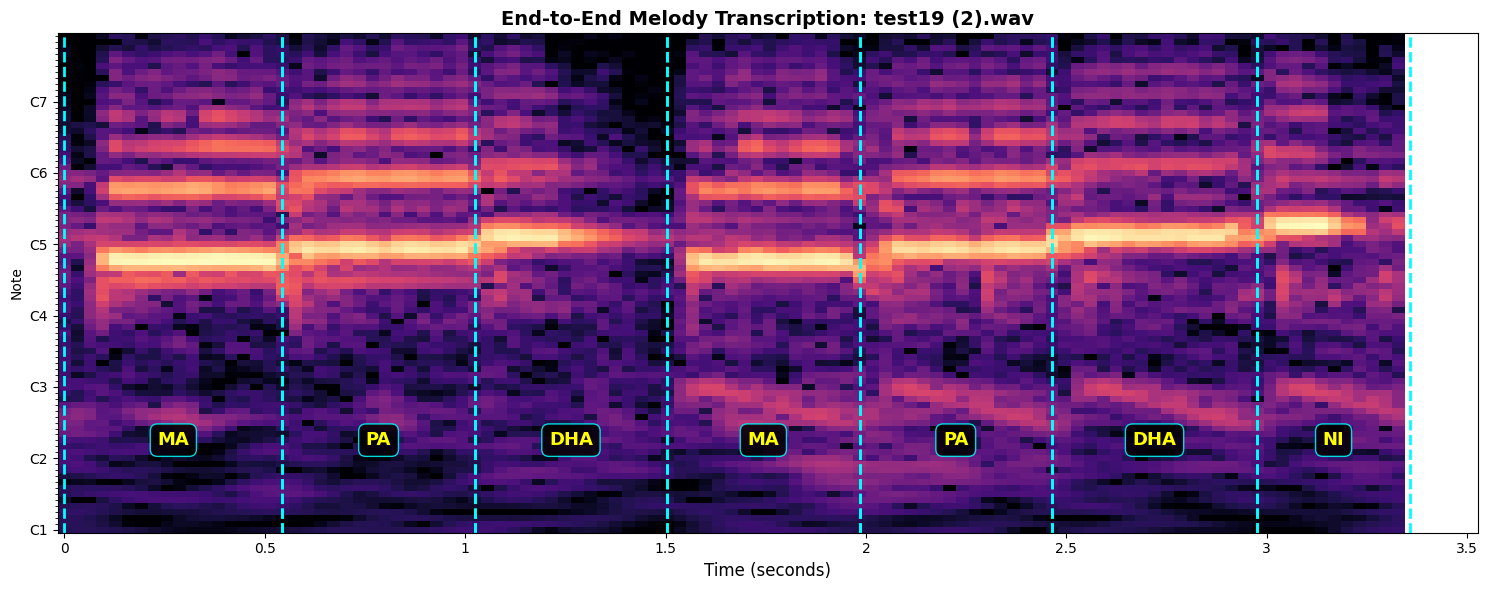


  AUDIO TRANSCRIPTION SUMMARY (7 Notes Detected)
 Segment 01 | [ 0.00s ➔  0.54s] | Predicted Swara: MA
 Segment 02 | [ 0.54s ➔  1.02s] | Predicted Swara: PA
 Segment 03 | [ 1.02s ➔  1.50s] | Predicted Swara: DHA
 Segment 04 | [ 1.50s ➔  1.98s] | Predicted Swara: MA
 Segment 05 | [ 1.98s ➔  2.46s] | Predicted Swara: PA
 Segment 06 | [ 2.46s ➔  2.98s] | Predicted Swara: DHA
 Segment 07 | [ 2.98s ➔  3.36s] | Predicted Swara: NI



In [ ]:
import os
import numpy as np
import librosa
import librosa.display
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from google.colab import files
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

# ==========================================
# 1. LOAD PRE-TRAINED MODELS FROM DRIVE
# ==========================================

# Adjust paths if your model checkpoints are saved elsewhere
SEGMENTATION_WEIGHTS_PATH = '/content/drive/MyDrive/crnn_flute_segmentation_checkpoint/crnn_flute_weights.pth'
CLASSIFIER_WEIGHTS_PATH   = '/content/drive/MyDrive/recording for paper/best_swara_classifier.pth'

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Load Segmentation Model (CRNNAttention)
seg_model = CRNNAttention(n_bins=CONFIG['n_bins']).to(device)
if os.path.exists(SEGMENTATION_WEIGHTS_PATH):
    seg_model.load_state_dict(torch.load(SEGMENTATION_WEIGHTS_PATH, map_location=device))
    print("✅ Loaded Segmentation Model weights.")
seg_model.eval()

# Load Classification Model (RealSwaraClassifier)
clf_model = RealSwaraClassifier(n_bins=CONFIG_CLF['n_bins'], num_classes=7).to(device)
if os.path.exists(CLASSIFIER_WEIGHTS_PATH):
    clf_model.load_state_dict(torch.load(CLASSIFIER_WEIGHTS_PATH, map_location=device))
    print("✅ Loaded Swara Classifier Model weights.")
clf_model.eval()


# ==========================================
# 2. ADAPTIVE PEAK PICKING HELPER
# ==========================================
def get_segment_boundaries(preds, hop_length=512, sr=16000):
    """Smooths boundary predictions and applies local dynamic thresholding."""
    smooth_preds = gaussian_filter1d(preds, sigma=1.0)

    # Rolling local mean window
    window_size = 15
    local_mean = np.convolve(smooth_preds, np.ones(window_size)/window_size, mode='same')
    dynamic_threshold = local_mean + 0.12

    peaks, _ = find_peaks(
        smooth_preds,
        height=dynamic_threshold,
        distance=12,    # Minimum ~380ms between cuts
        prominence=0.08
    )

    return librosa.frames_to_time(peaks, sr=sr, hop_length=hop_length)


# ==========================================
# 3. MASTER MERGED INFERENCE PIPELINE
# ==========================================
def transcribe_melody(audio_path, seg_model, clf_model, config_seg, config_clf):
    # --- STEP 1: LOAD & SEGMENT AUDIO ---
    y, sr = librosa.load(audio_path, sr=config_seg['sr'])
    total_duration = len(y) / sr

    # Compute full audio CQT for Segmentation
    cqt_full = np.abs(librosa.cqt(y, sr=sr, hop_length=config_seg['hop_length'],
                                  n_bins=config_seg['n_bins'],
                                  bins_per_octave=config_seg['bins_per_octave']))
    cqt_db = librosa.amplitude_to_db(cqt_full, ref=np.max)
    cqt_norm = (cqt_db - cqt_db.min()) / (cqt_db.max() - cqt_db.min() + 1e-6)

    cqt_tensor = torch.tensor(cqt_norm, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        seg_preds = seg_model(cqt_tensor).squeeze().cpu().numpy()

    peak_times = get_segment_boundaries(seg_preds, hop_length=config_seg['hop_length'], sr=sr)

    # Create segment time ranges [(0, t1), (t1, t2), ..., (tk, total_duration)]
    raw_cuts = [0.0] + list(peak_times) + [total_duration]
    segment_intervals = []

    # Filter out ghost segments (< 150ms)
    for i in range(len(raw_cuts) - 1):
        start_t, end_t = raw_cuts[i], raw_cuts[i+1]
        if end_t - start_t >= 0.15:
            segment_intervals.append((start_t, end_t))

    # --- STEP 2: CLASSIFY EACH SEGMENT ---
    predictions = []
    target_samples = int(config_clf['target_duration'] * sr)

    for start_t, end_t in segment_intervals:
        start_sample = int(start_t * sr)
        end_sample = int(end_t * sr)
        slice_y = y[start_sample:end_sample]

        # Standardize length to 2.0 seconds for classifier
        if len(slice_y) > target_samples:
            slice_y = slice_y[:target_samples]
        else:
            slice_y = np.pad(slice_y, (0, target_samples - len(slice_y)))

        # Compute slice CQT for Classifier
        cqt_slice = np.abs(librosa.cqt(slice_y, sr=sr, hop_length=config_clf['hop_length'],
                                       n_bins=config_clf['n_bins'],
                                       bins_per_octave=config_clf['bins_per_octave']))
        slice_db = librosa.amplitude_to_db(cqt_slice, ref=np.max)
        slice_norm = (slice_db - slice_db.min()) / (slice_db.max() - slice_db.min() + 1e-6)

        slice_tensor = torch.tensor(slice_norm, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = clf_model(slice_tensor)
            pred_id = torch.argmax(logits, dim=1).item()
            predictions.append(id2swara[pred_id])

    # --- STEP 3: VISUALIZATION & OUTPUT ---
    fig, ax = plt.subplots(figsize=(15, 6))

    # Display full CQT Spectrogram
    librosa.display.specshow(cqt_db, sr=sr, hop_length=config_seg['hop_length'],
                             x_axis='time', y_axis='cqt_note', ax=ax, cmap='magma')

    # Draw boundary cuts and overlay predicted Swara text
    for idx, ((start_t, end_t), swara) in enumerate(zip(segment_intervals, predictions)):
        mid_t = (start_t + end_t) / 2.0

        # Vertical cut lines
        ax.axvline(x=start_t, color='cyan', linestyle='--', linewidth=2)
        ax.axvline(x=end_t, color='cyan', linestyle='--', linewidth=2)

        # Swara label box on top of segment
        ax.text(mid_t, config_seg['n_bins'] - 6, swara.upper(),
                color='yellow', fontsize=13, fontweight='bold', ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.4', facecolor='black', edgecolor='cyan', alpha=0.85))

    ax.set_title(f"End-to-End Melody Transcription: {os.path.basename(audio_path)}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Time (seconds)", fontsize=12)
    plt.tight_layout()
    plt.show()

    # Print formatted transcription summary table
    print("\n" + "="*50)
    print(f"  AUDIO TRANSCRIPTION SUMMARY ({len(predictions)} Notes Detected)")
    print("="*50)
    for idx, ((s, e), note) in enumerate(zip(segment_intervals, predictions)):
        print(f" Segment {idx+1:02d} | [{s:5.2f}s ➔ {e:5.2f}s] | Predicted Swara: {note.upper()}")
    print("="*50 + "\n")


# ==========================================
# 4. RUN ON UPLOADED AUDIO FILES
# ==========================================
print("Upload a test melody (.wav) file to run full segmentation + classification:")
uploaded = files.upload()

for fn in uploaded.keys():
    transcribe_melody(fn, seg_model, clf_model, CONFIG, CONFIG_CLF)

In [ ]:
import os
import torch

# Define path for the unified system file
UNIFIED_SAVE_PATH = '/content/drive/MyDrive/full_melody_transcriber_system.pt'

# Bundle models, weights, configs, and mappings into one dictionary
master_checkpoint = {
    'seg_model_state': seg_model.state_dict(),
    'clf_model_state': swara_model.state_dict(),  # Uses your trained RealSwaraClassifier
    'config_seg': CONFIG,
    'config_clf': CONFIG_CLF,
    'id2swara': id2swara,
    'swara2id': swara2id,
    'allowed_classes': ALLOWED_CLASSES
}

torch.save(master_checkpoint, UNIFIED_SAVE_PATH)
print(f"✅ Unified system successfully saved to Google Drive:\n ➔ {UNIFIED_SAVE_PATH}")

✅ Unified system successfully saved to Google Drive:
 ➔ /content/drive/MyDrive/full_melody_transcriber_system.pt


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading system checkpoint from: /content/drive/MyDrive/full_melody_transcriber_system.pt...
✅ Pipeline restored successfully and ready for inference!


Saving test1.wav to test1 (4).wav
Saving test2.wav to test2 (4).wav
Saving test3.wav to test3 (4).wav
Saving test4.wav to test4 (4).wav
Saving test5.wav to test5 (4).wav
Saving test6.wav to test6 (4).wav
Saving test7.wav to test7 (4).wav
Saving test8.wav to test8 (4).wav
Saving test9.wav to test9 (4).wav
Saving test10.wav to test10 (4).wav
Saving test11.wav to test11 (4).wav
Saving test12.wav to test12 (4).wav
Saving test13.wav to test13 (4).wav
Saving test14.wav to test14 (4).wav
Saving test15.wav to test15 (3).wav
Saving test16.wav to test16 (3).wav
Saving test17.wav to test17 (3).wav
Saving test18.wav to test18 (3).wav
Saving test19.wav to test19 (3).wav


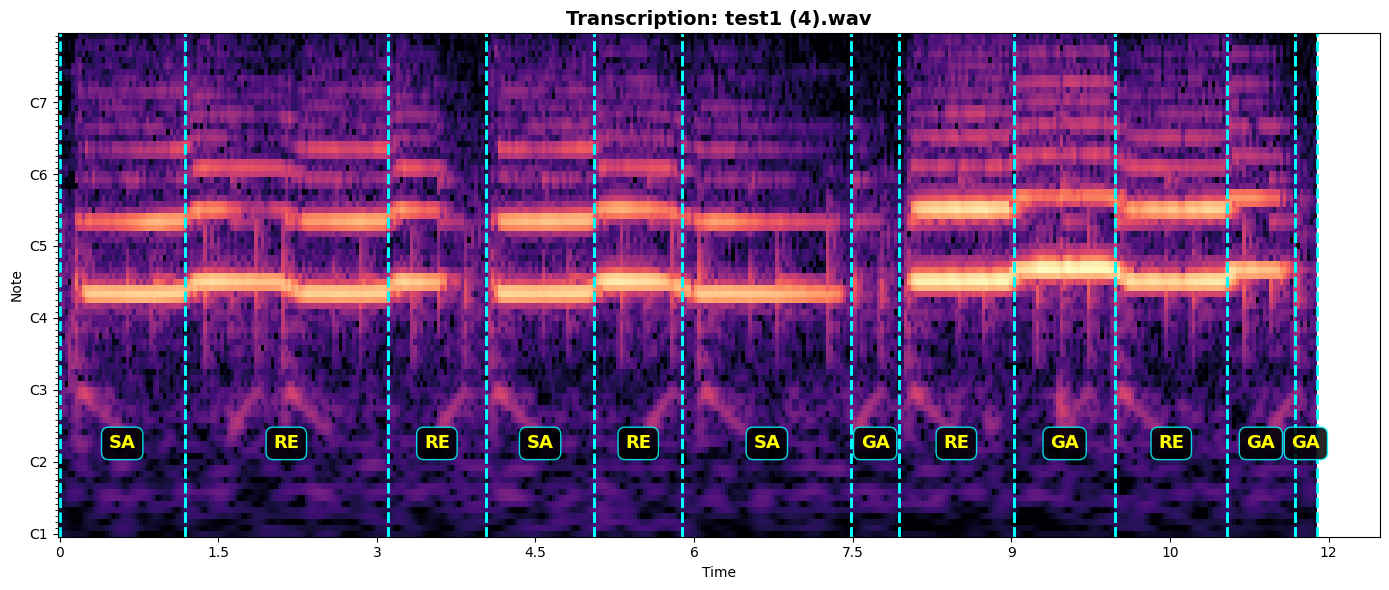


--- TRANSCRIPTION FOR test1 (4).wav ---
  Note 01 [ 0.00s ->  1.18s]: SA
  Note 02 [ 1.18s ->  3.10s]: RE
  Note 03 [ 3.10s ->  4.03s]: RE
  Note 04 [ 4.03s ->  5.06s]: SA
  Note 05 [ 5.06s ->  5.89s]: RE
  Note 06 [ 5.89s ->  7.49s]: SA
  Note 07 [ 7.49s ->  7.94s]: GA
  Note 08 [ 7.94s ->  9.02s]: RE
  Note 09 [ 9.02s ->  9.98s]: GA
  Note 10 [ 9.98s -> 11.04s]: RE
  Note 11 [11.04s -> 11.68s]: GA
  Note 12 [11.68s -> 11.89s]: GA
---------------------------------------------


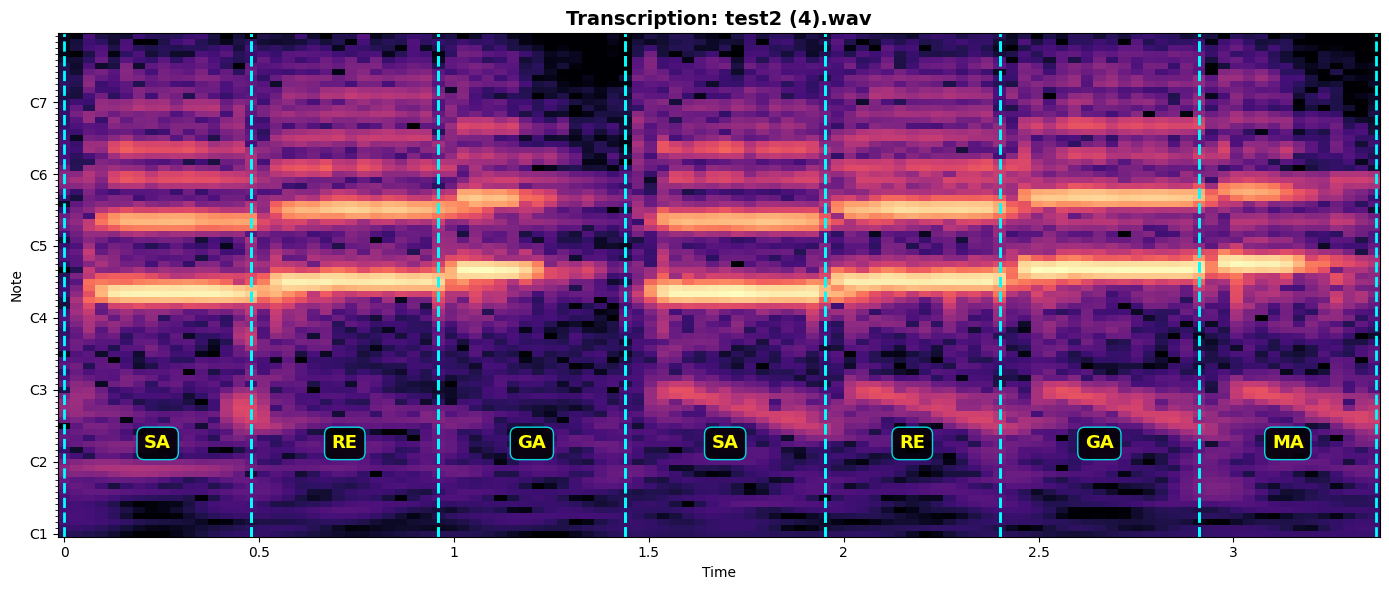


--- TRANSCRIPTION FOR test2 (4).wav ---
  Note 01 [ 0.00s ->  0.48s]: SA
  Note 02 [ 0.48s ->  0.96s]: RE
  Note 03 [ 0.96s ->  1.44s]: GA
  Note 04 [ 1.44s ->  1.95s]: SA
  Note 05 [ 1.95s ->  2.40s]: RE
  Note 06 [ 2.40s ->  2.91s]: GA
  Note 07 [ 2.91s ->  3.37s]: MA
---------------------------------------------


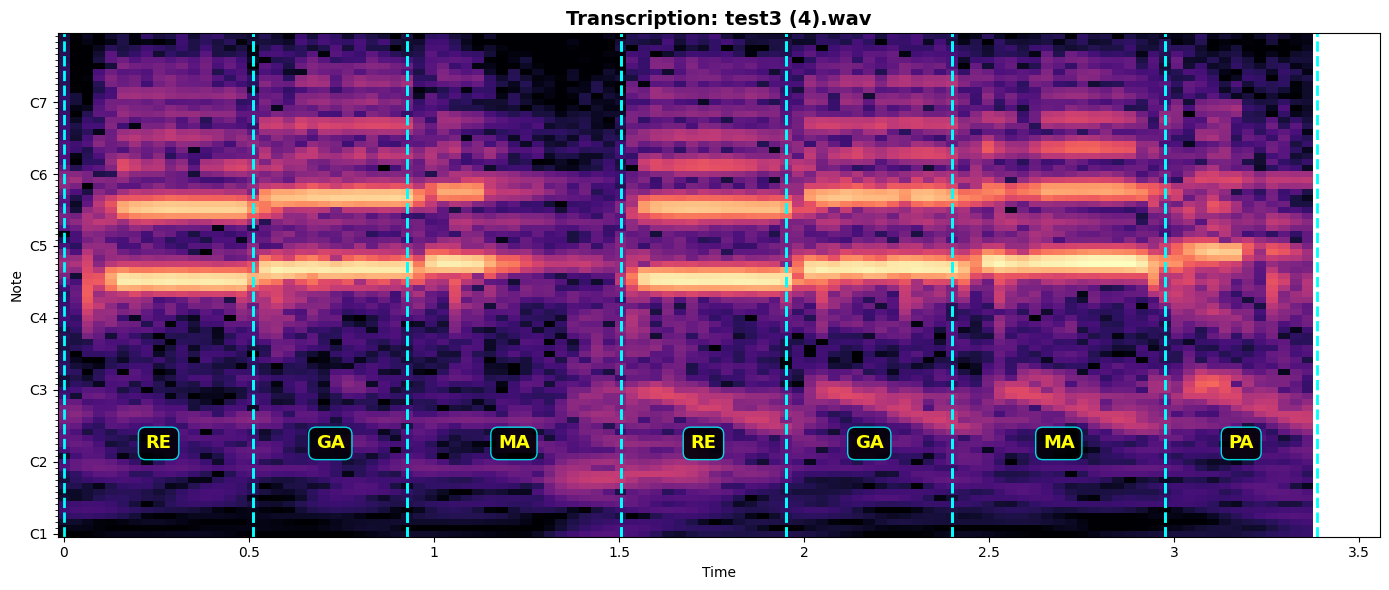


--- TRANSCRIPTION FOR test3 (4).wav ---
  Note 01 [ 0.00s ->  0.51s]: RE
  Note 02 [ 0.51s ->  0.93s]: GA
  Note 03 [ 0.93s ->  1.50s]: MA
  Note 04 [ 1.50s ->  1.95s]: RE
  Note 05 [ 1.95s ->  2.40s]: GA
  Note 06 [ 2.40s ->  2.98s]: MA
  Note 07 [ 2.98s ->  3.39s]: PA
---------------------------------------------


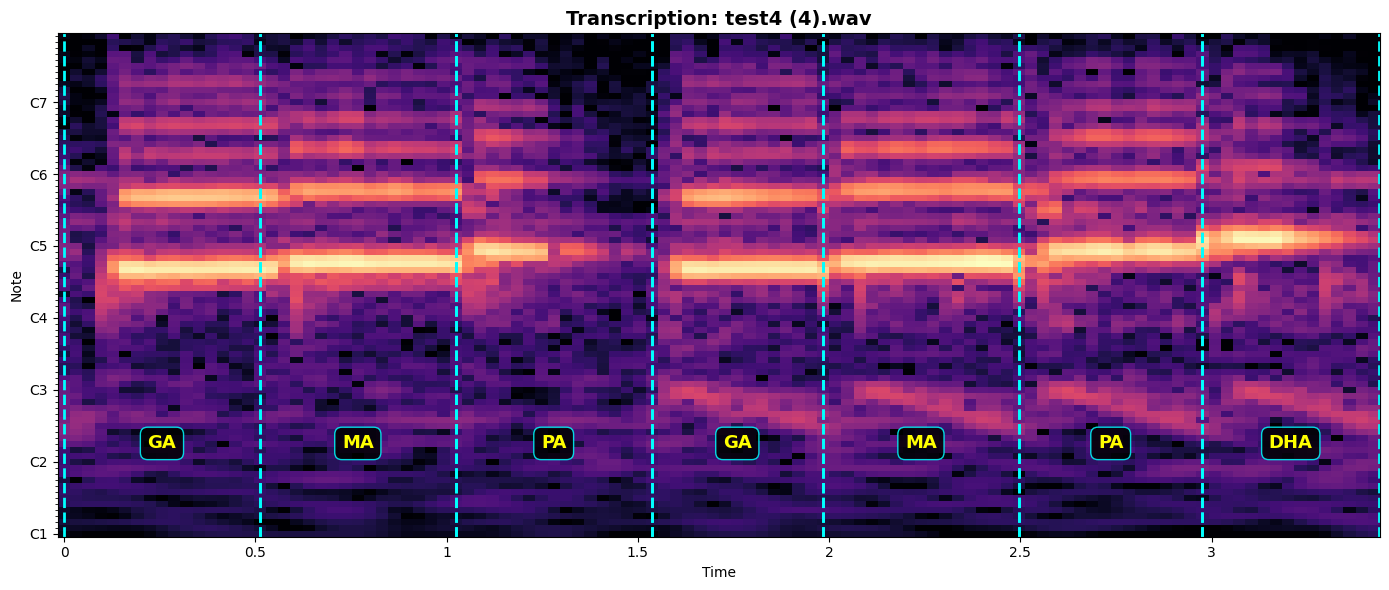


--- TRANSCRIPTION FOR test4 (4).wav ---
  Note 01 [ 0.00s ->  0.51s]: GA
  Note 02 [ 0.51s ->  1.02s]: MA
  Note 03 [ 1.02s ->  1.54s]: PA
  Note 04 [ 1.54s ->  1.98s]: GA
  Note 05 [ 1.98s ->  2.50s]: MA
  Note 06 [ 2.50s ->  2.98s]: PA
  Note 07 [ 2.98s ->  3.44s]: DHA
---------------------------------------------


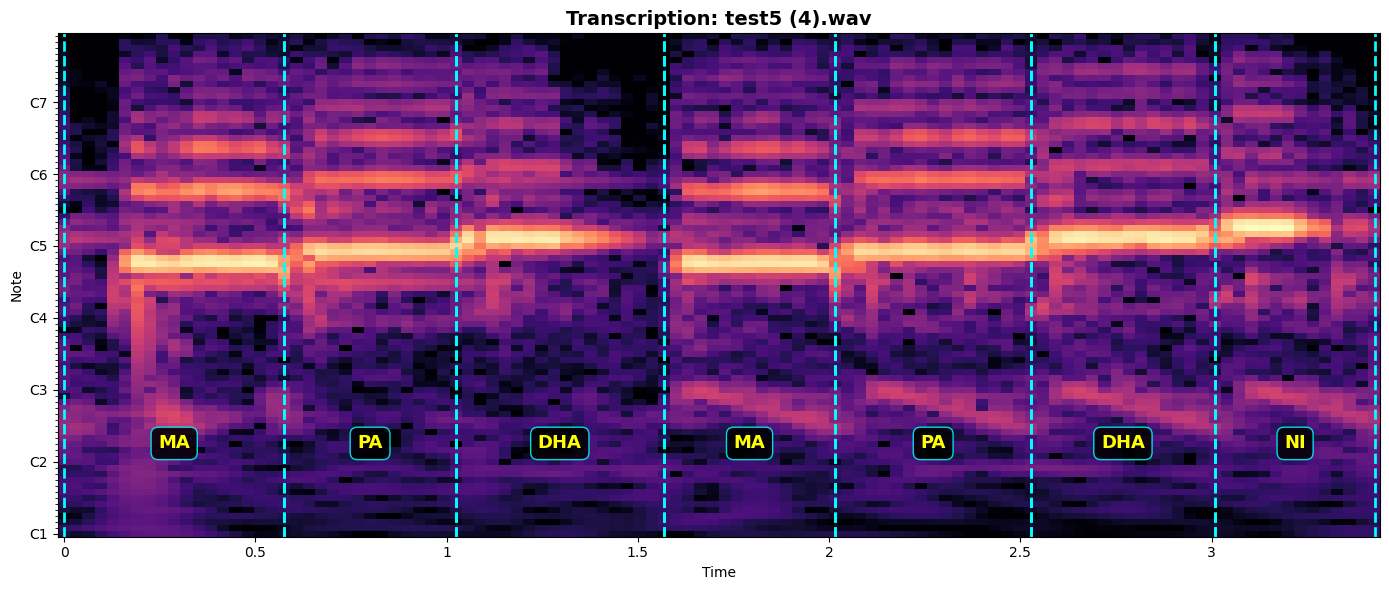


--- TRANSCRIPTION FOR test5 (4).wav ---
  Note 01 [ 0.00s ->  0.58s]: MA
  Note 02 [ 0.58s ->  1.02s]: PA
  Note 03 [ 1.02s ->  1.57s]: DHA
  Note 04 [ 1.57s ->  2.02s]: MA
  Note 05 [ 2.02s ->  2.53s]: PA
  Note 06 [ 2.53s ->  3.01s]: DHA
  Note 07 [ 3.01s ->  3.43s]: NI
---------------------------------------------


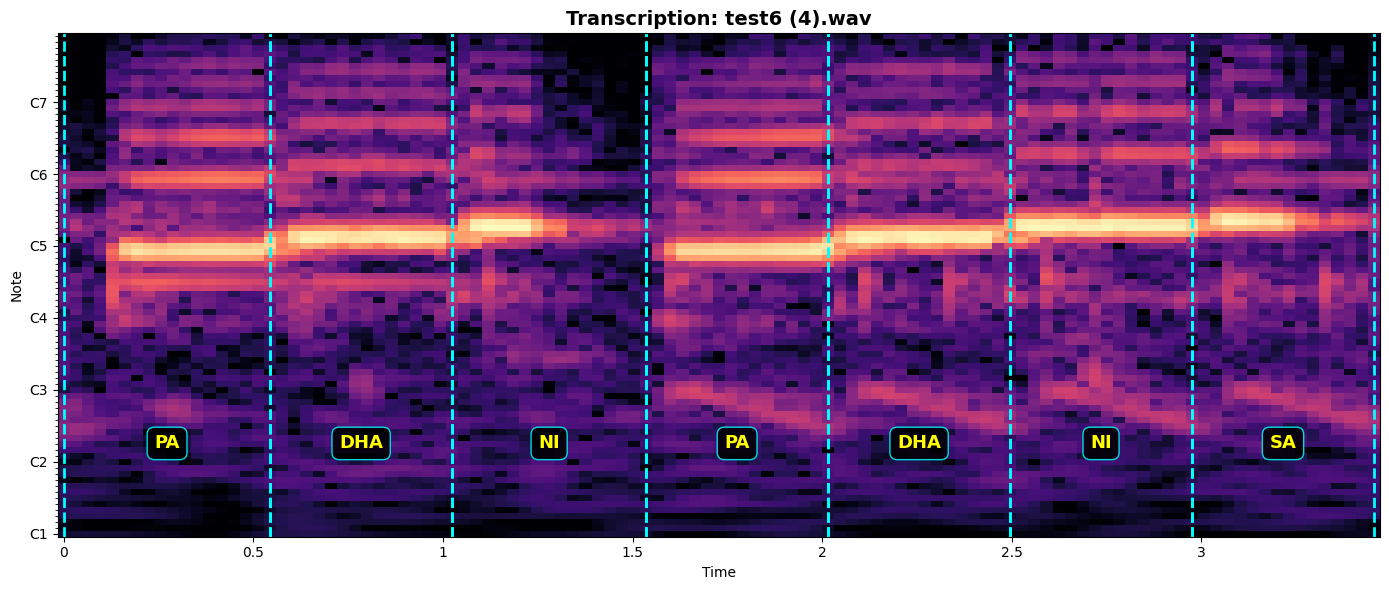


--- TRANSCRIPTION FOR test6 (4).wav ---
  Note 01 [ 0.00s ->  0.54s]: PA
  Note 02 [ 0.54s ->  1.02s]: DHA
  Note 03 [ 1.02s ->  1.54s]: NI
  Note 04 [ 1.54s ->  2.02s]: PA
  Note 05 [ 2.02s ->  2.50s]: DHA
  Note 06 [ 2.50s ->  2.98s]: NI
  Note 07 [ 2.98s ->  3.46s]: SA
---------------------------------------------


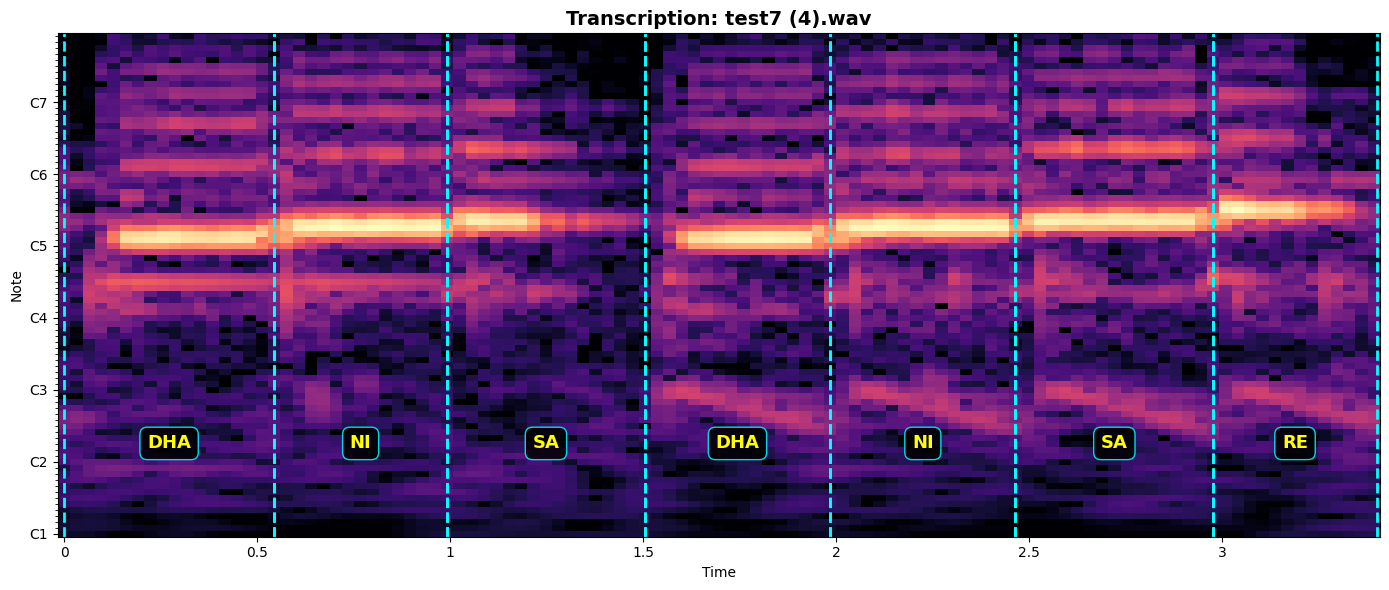


--- TRANSCRIPTION FOR test7 (4).wav ---
  Note 01 [ 0.00s ->  0.54s]: DHA
  Note 02 [ 0.54s ->  0.99s]: NI
  Note 03 [ 0.99s ->  1.50s]: SA
  Note 04 [ 1.50s ->  1.98s]: DHA
  Note 05 [ 1.98s ->  2.46s]: NI
  Note 06 [ 2.46s ->  2.98s]: SA
  Note 07 [ 2.98s ->  3.40s]: RE
---------------------------------------------


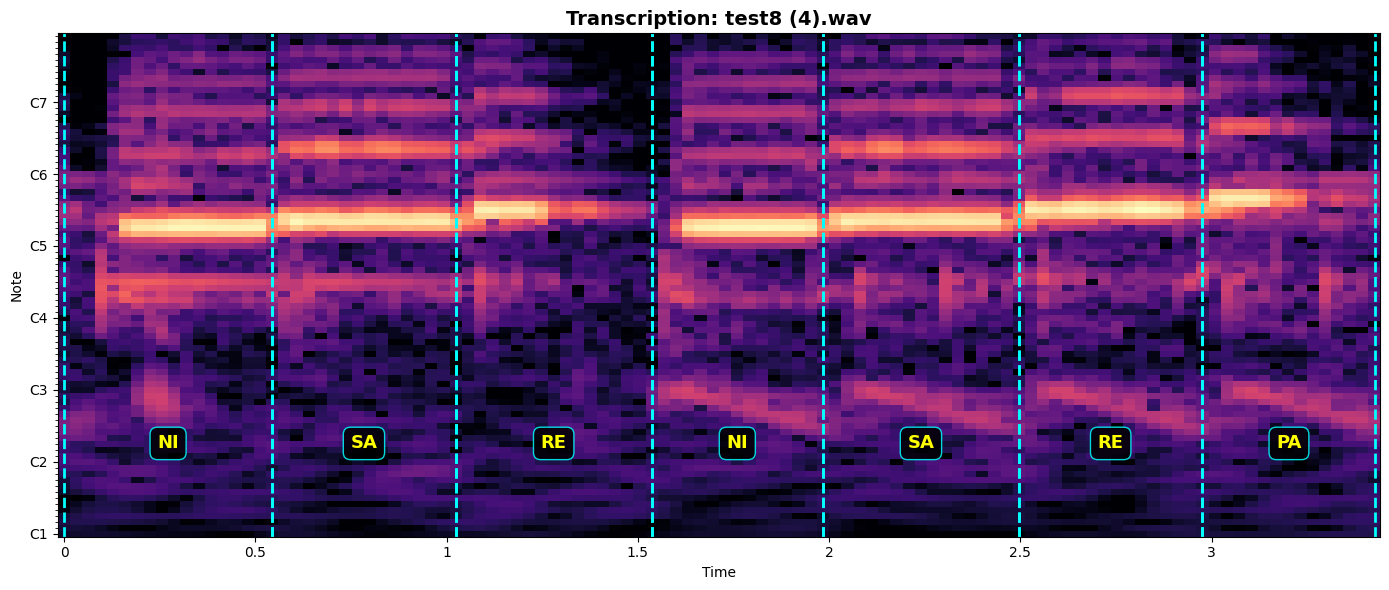


--- TRANSCRIPTION FOR test8 (4).wav ---
  Note 01 [ 0.00s ->  0.54s]: NI
  Note 02 [ 0.54s ->  1.02s]: SA
  Note 03 [ 1.02s ->  1.54s]: RE
  Note 04 [ 1.54s ->  1.98s]: NI
  Note 05 [ 1.98s ->  2.50s]: SA
  Note 06 [ 2.50s ->  2.98s]: RE
  Note 07 [ 2.98s ->  3.43s]: PA
---------------------------------------------


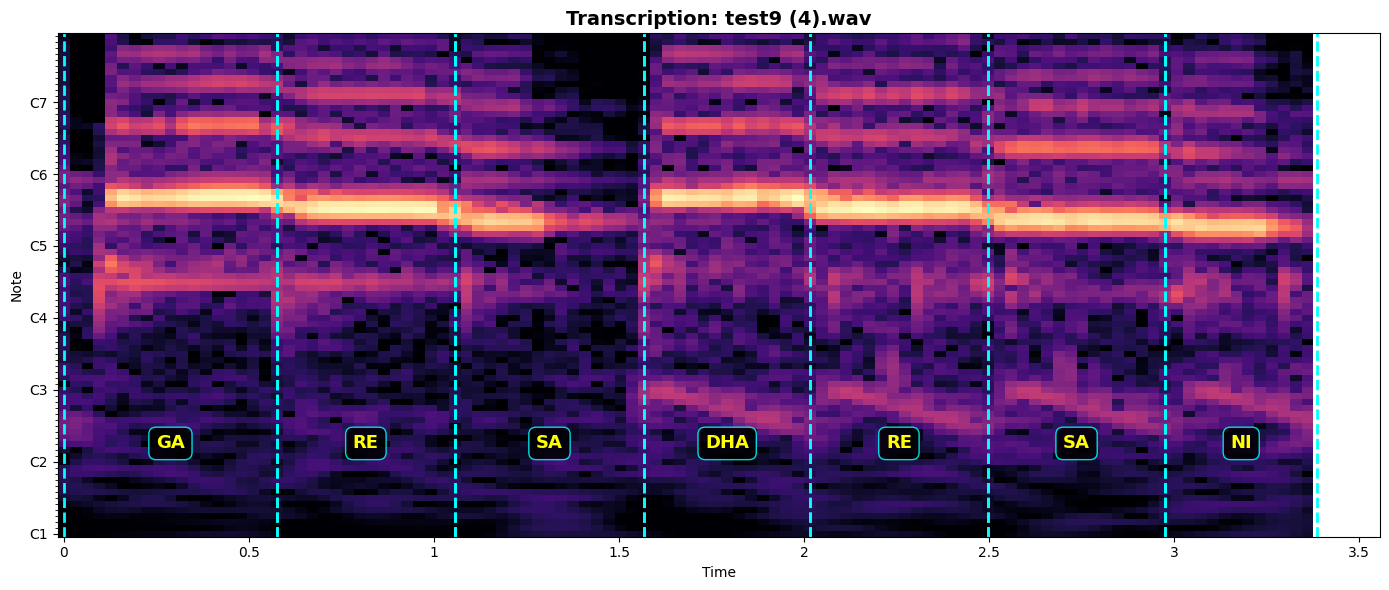


--- TRANSCRIPTION FOR test9 (4).wav ---
  Note 01 [ 0.00s ->  0.58s]: GA
  Note 02 [ 0.58s ->  1.06s]: RE
  Note 03 [ 1.06s ->  1.57s]: SA
  Note 04 [ 1.57s ->  2.02s]: DHA
  Note 05 [ 2.02s ->  2.50s]: RE
  Note 06 [ 2.50s ->  2.98s]: SA
  Note 07 [ 2.98s ->  3.39s]: NI
---------------------------------------------


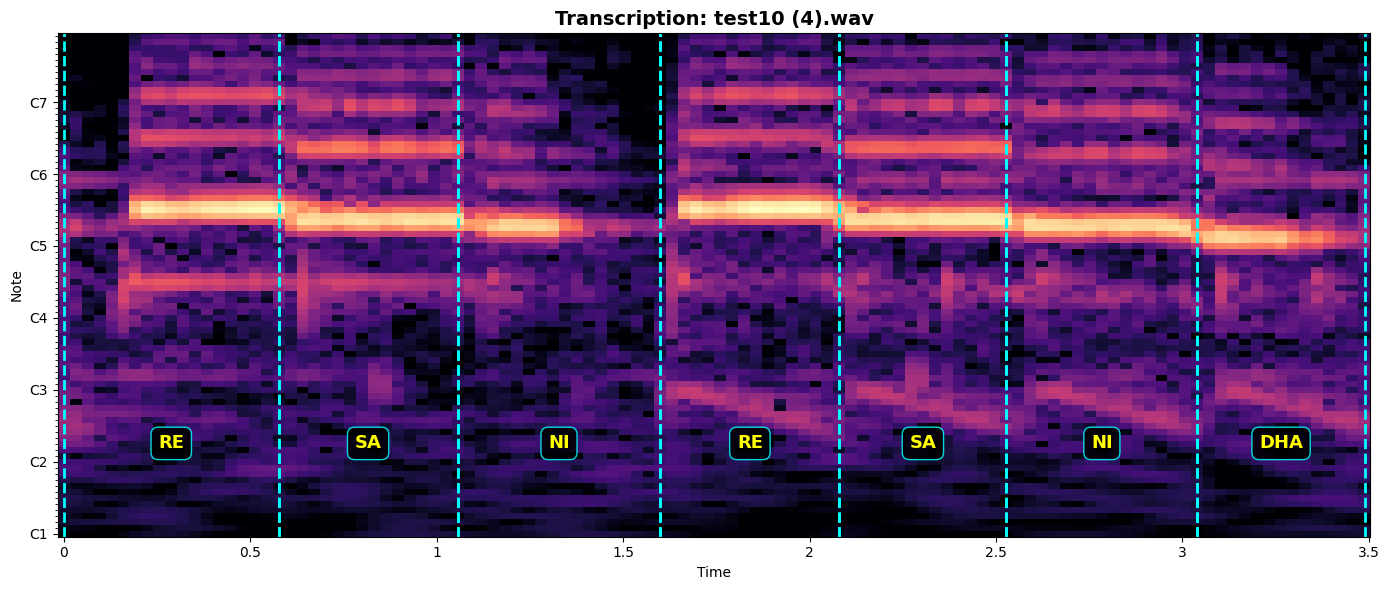


--- TRANSCRIPTION FOR test10 (4).wav ---
  Note 01 [ 0.00s ->  0.58s]: RE
  Note 02 [ 0.58s ->  1.06s]: SA
  Note 03 [ 1.06s ->  1.60s]: NI
  Note 04 [ 1.60s ->  2.08s]: RE
  Note 05 [ 2.08s ->  2.53s]: SA
  Note 06 [ 2.53s ->  3.04s]: NI
  Note 07 [ 3.04s ->  3.49s]: DHA
---------------------------------------------


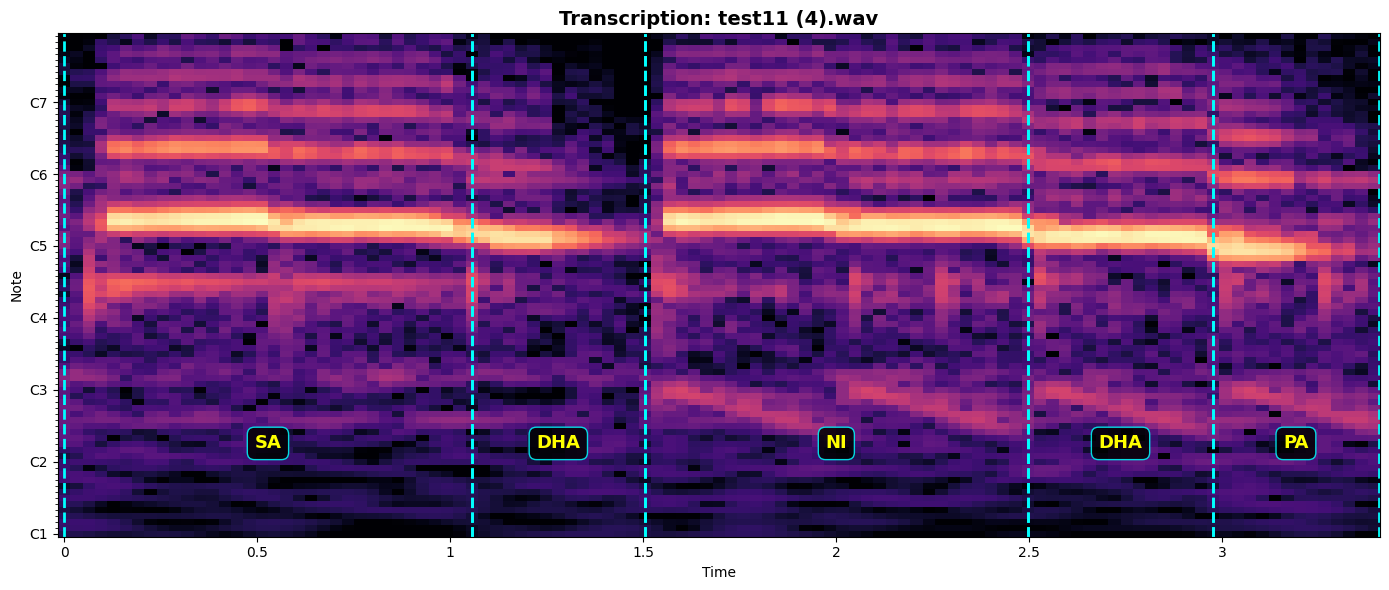


--- TRANSCRIPTION FOR test11 (4).wav ---
  Note 01 [ 0.00s ->  1.06s]: SA
  Note 02 [ 1.06s ->  1.50s]: DHA
  Note 03 [ 1.50s ->  2.50s]: NI
  Note 04 [ 2.50s ->  2.98s]: DHA
  Note 05 [ 2.98s ->  3.40s]: PA
---------------------------------------------


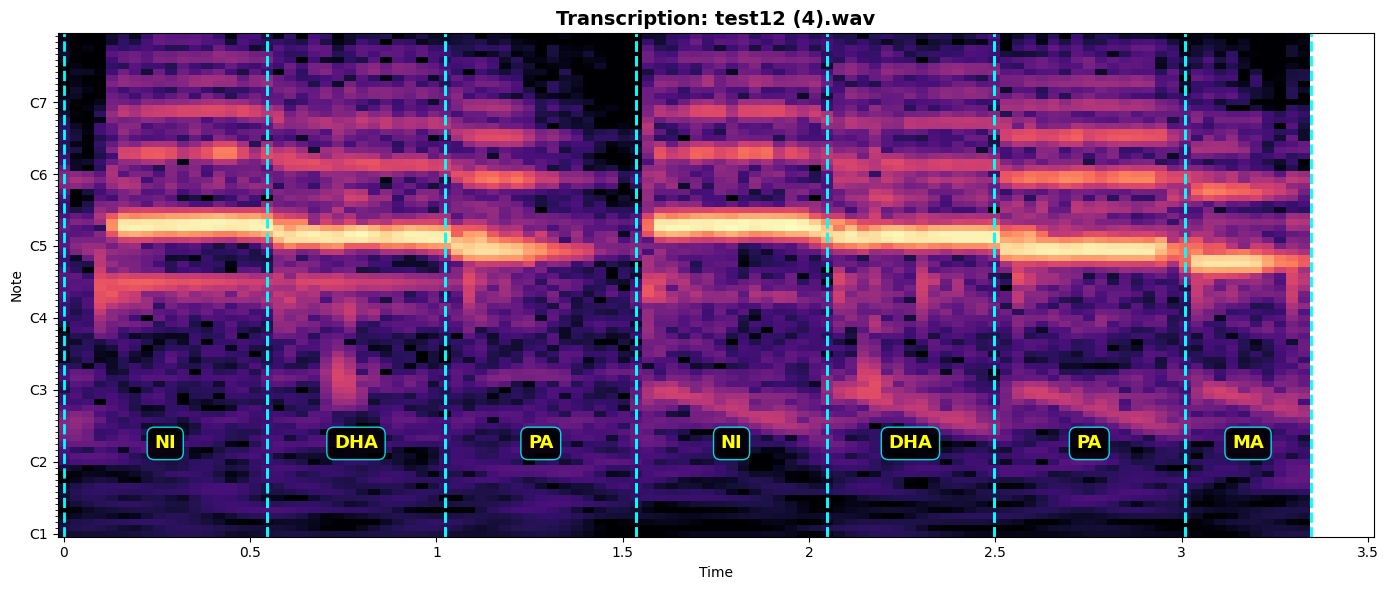


--- TRANSCRIPTION FOR test12 (4).wav ---
  Note 01 [ 0.00s ->  0.54s]: NI
  Note 02 [ 0.54s ->  1.02s]: DHA
  Note 03 [ 1.02s ->  1.54s]: PA
  Note 04 [ 1.54s ->  2.05s]: NI
  Note 05 [ 2.05s ->  2.50s]: DHA
  Note 06 [ 2.50s ->  3.01s]: PA
  Note 07 [ 3.01s ->  3.35s]: MA
---------------------------------------------


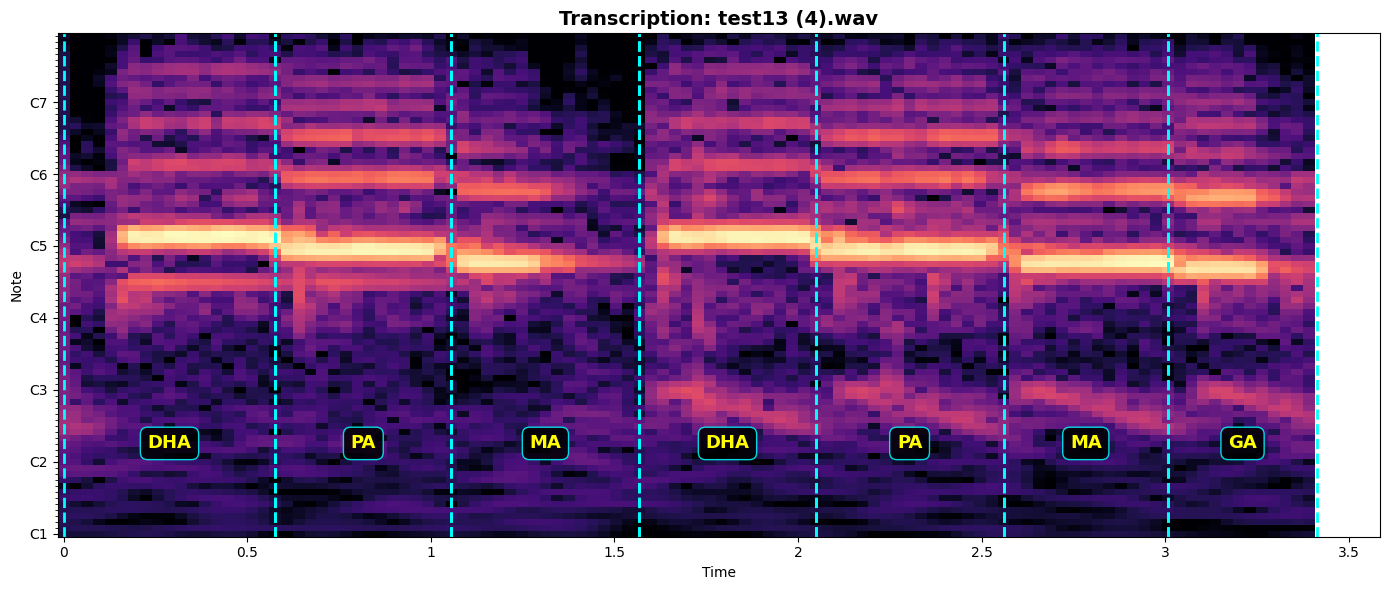


--- TRANSCRIPTION FOR test13 (4).wav ---
  Note 01 [ 0.00s ->  0.58s]: DHA
  Note 02 [ 0.58s ->  1.06s]: PA
  Note 03 [ 1.06s ->  1.57s]: MA
  Note 04 [ 1.57s ->  2.05s]: DHA
  Note 05 [ 2.05s ->  2.56s]: PA
  Note 06 [ 2.56s ->  3.01s]: MA
  Note 07 [ 3.01s ->  3.41s]: GA
---------------------------------------------


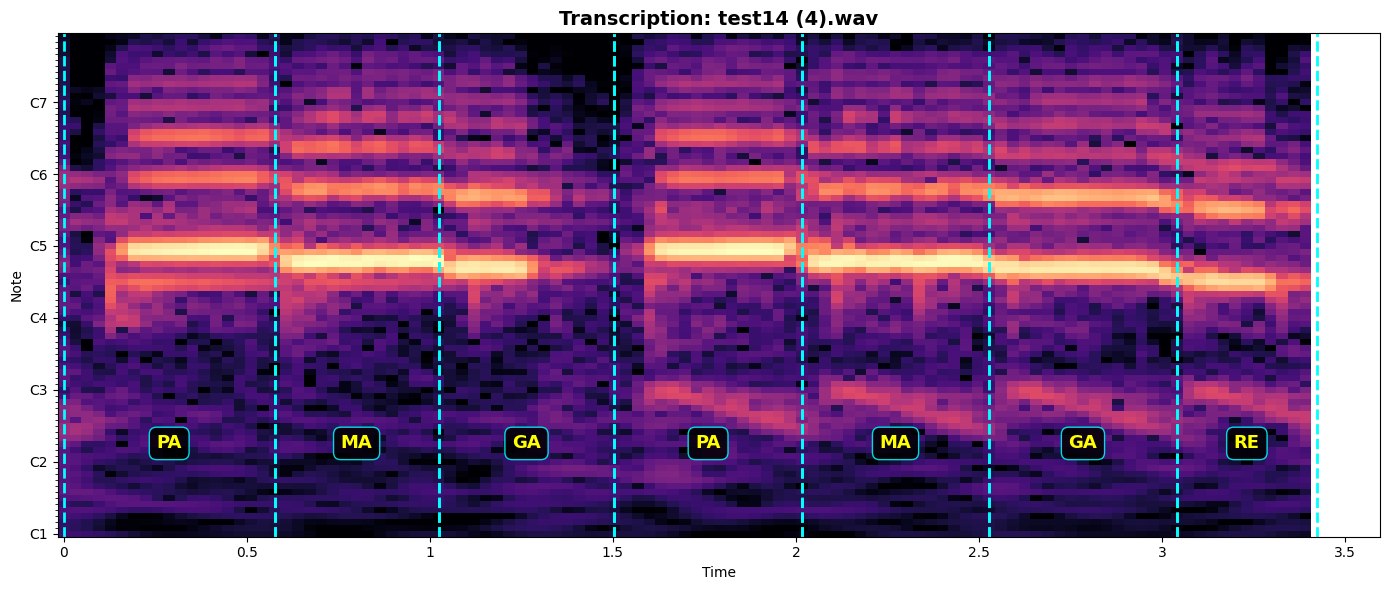


--- TRANSCRIPTION FOR test14 (4).wav ---
  Note 01 [ 0.00s ->  0.58s]: PA
  Note 02 [ 0.58s ->  1.02s]: MA
  Note 03 [ 1.02s ->  1.50s]: GA
  Note 04 [ 1.50s ->  2.02s]: PA
  Note 05 [ 2.02s ->  2.53s]: MA
  Note 06 [ 2.53s ->  3.04s]: GA
  Note 07 [ 3.04s ->  3.42s]: RE
---------------------------------------------


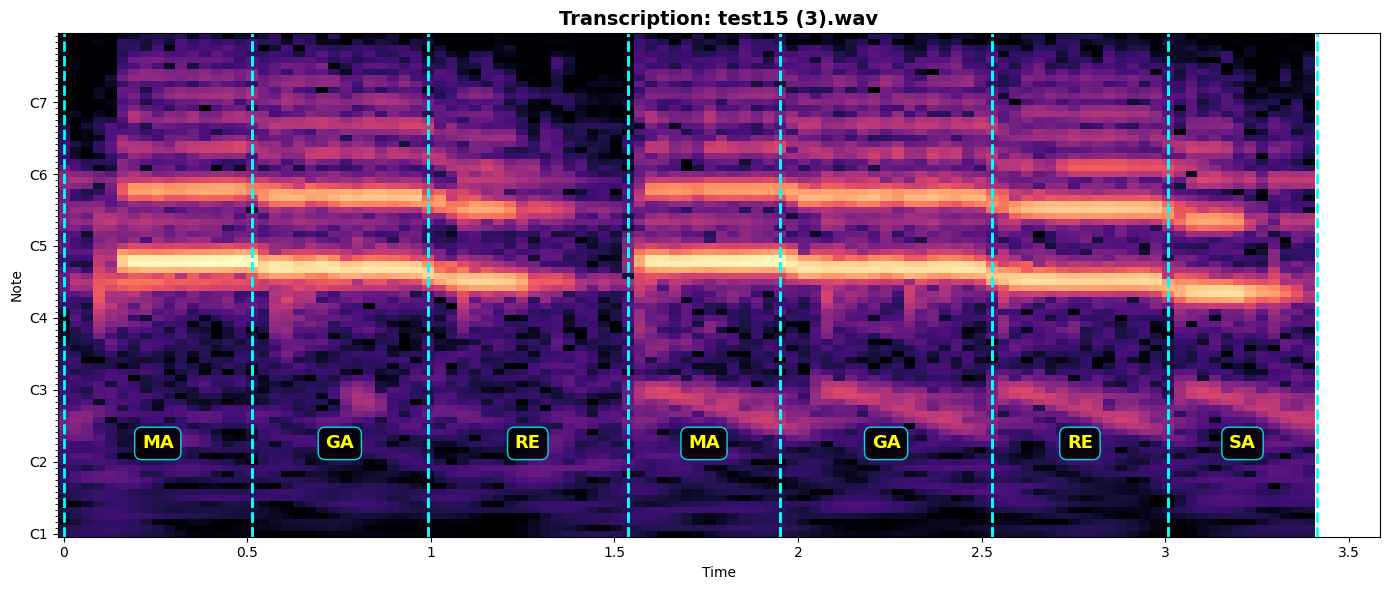


--- TRANSCRIPTION FOR test15 (3).wav ---
  Note 01 [ 0.00s ->  0.51s]: MA
  Note 02 [ 0.51s ->  0.99s]: GA
  Note 03 [ 0.99s ->  1.54s]: RE
  Note 04 [ 1.54s ->  1.95s]: MA
  Note 05 [ 1.95s ->  2.53s]: GA
  Note 06 [ 2.53s ->  3.01s]: RE
  Note 07 [ 3.01s ->  3.41s]: SA
---------------------------------------------


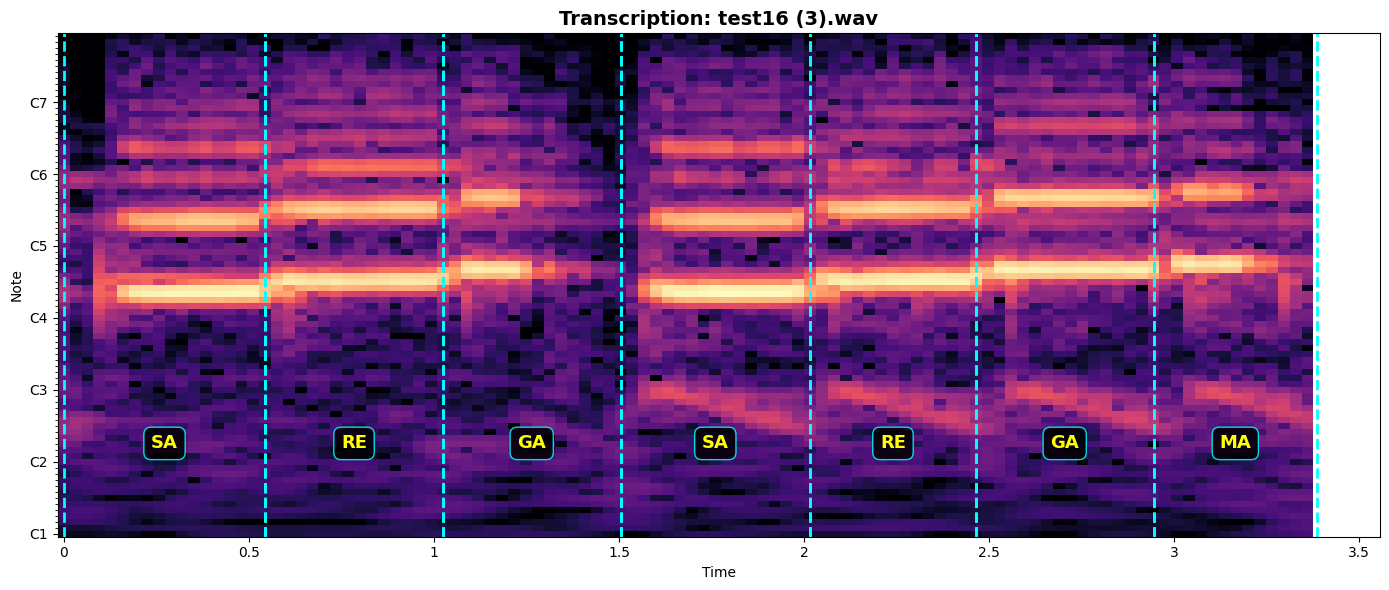


--- TRANSCRIPTION FOR test16 (3).wav ---
  Note 01 [ 0.00s ->  0.54s]: SA
  Note 02 [ 0.54s ->  1.02s]: RE
  Note 03 [ 1.02s ->  1.50s]: GA
  Note 04 [ 1.50s ->  2.02s]: SA
  Note 05 [ 2.02s ->  2.46s]: RE
  Note 06 [ 2.46s ->  2.94s]: GA
  Note 07 [ 2.94s ->  3.39s]: MA
---------------------------------------------


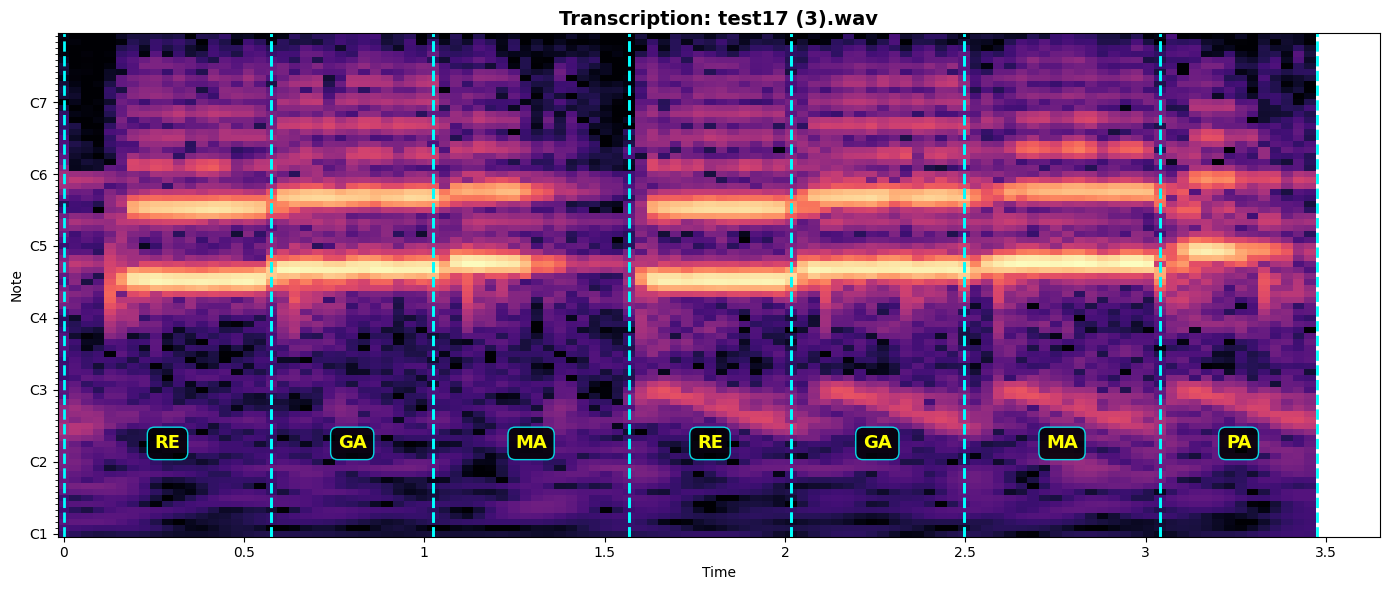


--- TRANSCRIPTION FOR test17 (3).wav ---
  Note 01 [ 0.00s ->  0.58s]: RE
  Note 02 [ 0.58s ->  1.02s]: GA
  Note 03 [ 1.02s ->  1.57s]: MA
  Note 04 [ 1.57s ->  2.02s]: RE
  Note 05 [ 2.02s ->  2.50s]: GA
  Note 06 [ 2.50s ->  3.04s]: MA
  Note 07 [ 3.04s ->  3.48s]: PA
---------------------------------------------


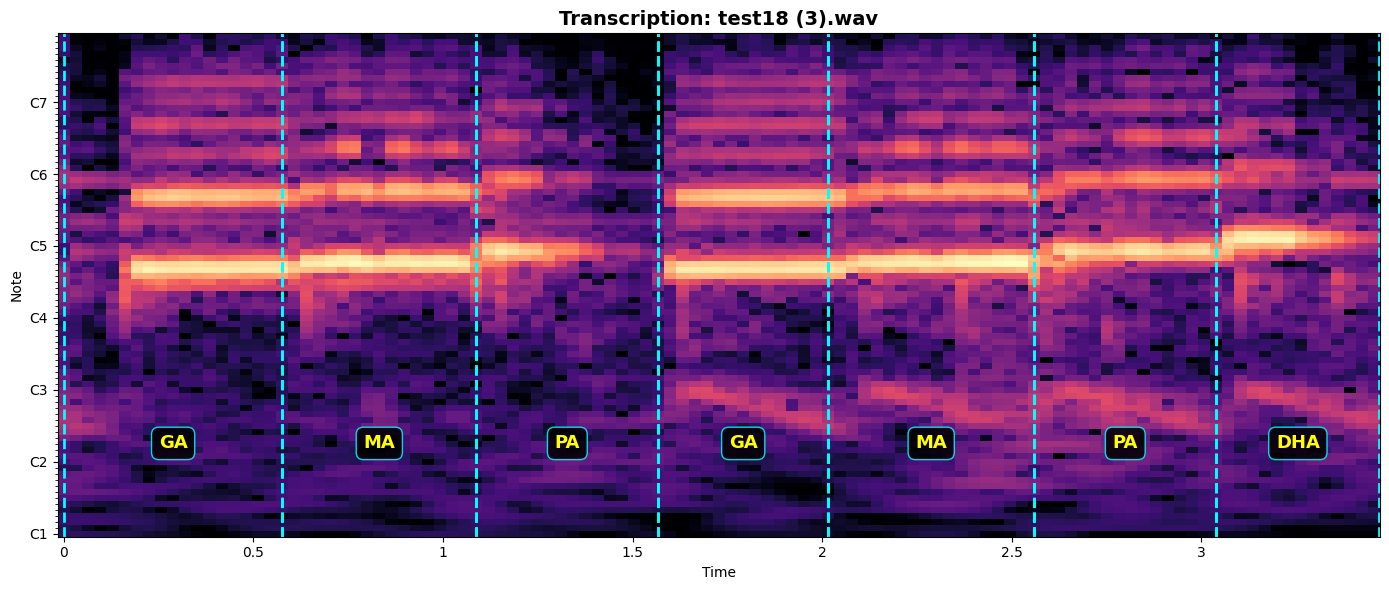


--- TRANSCRIPTION FOR test18 (3).wav ---
  Note 01 [ 0.00s ->  0.58s]: GA
  Note 02 [ 0.58s ->  1.09s]: MA
  Note 03 [ 1.09s ->  1.57s]: PA
  Note 04 [ 1.57s ->  2.02s]: GA
  Note 05 [ 2.02s ->  2.56s]: MA
  Note 06 [ 2.56s ->  3.04s]: PA
  Note 07 [ 3.04s ->  3.47s]: DHA
---------------------------------------------


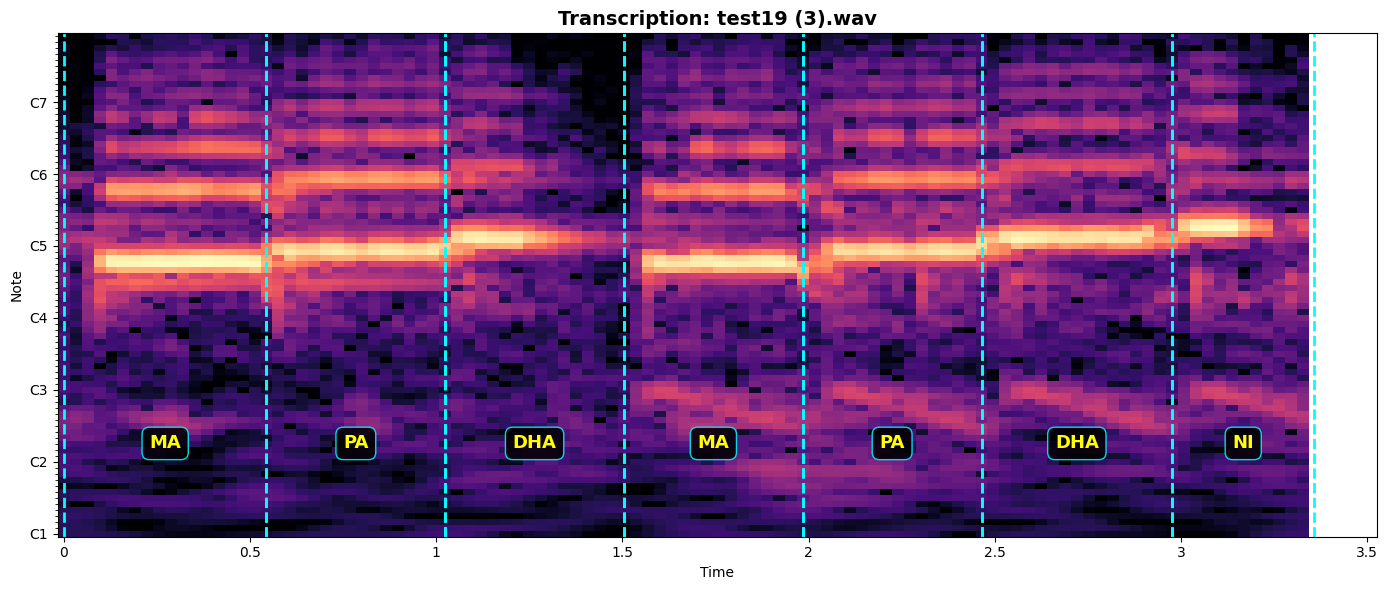


--- TRANSCRIPTION FOR test19 (3).wav ---
  Note 01 [ 0.00s ->  0.54s]: MA
  Note 02 [ 0.54s ->  1.02s]: PA
  Note 03 [ 1.02s ->  1.50s]: DHA
  Note 04 [ 1.50s ->  1.98s]: MA
  Note 05 [ 1.98s ->  2.46s]: PA
  Note 06 [ 2.46s ->  2.98s]: DHA
  Note 07 [ 2.98s ->  3.36s]: NI
---------------------------------------------


In [ ]:
import os
import numpy as np
import librosa
import librosa.display
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from google.colab import drive, files
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

# Mount Drive
drive.mount('/content/drive')

# ==========================================
# 1. MODEL ARCHITECTURES (FOR RECONSTRUCTION)
# ==========================================

class TemporalAttentionPooling(nn.Module):
    def __init__(self, in_dim):
        super(TemporalAttentionPooling, self).__init__()
        self.attn = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        attn_weights = torch.softmax(self.attn(x), dim=1)
        return torch.sum(x * attn_weights, dim=1)

class CRNNAttention(nn.Module):
    def __init__(self, n_bins=84):
        super(CRNNAttention, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d((2, 1)),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d((2, 1)),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d((2, 1))
        )
        self.rnn = nn.LSTM(64 * (n_bins // 8), 128, bidirectional=True, batch_first=True)
        self.attention = nn.MultiheadAttention(embed_dim=256, num_heads=4, batch_first=True)
        self.fc = nn.Sequential(nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1), nn.Sigmoid())

    def forward(self, x):
        x = self.cnn(x)
        b, c, f, t = x.size()
        x = x.permute(0, 3, 1, 2).contiguous().view(b, t, c * f)
        rnn_out, _ = self.rnn(x)
        attn_out, _ = self.attention(rnn_out, rnn_out, rnn_out)
        return self.fc(attn_out).squeeze(-1)

class RealSwaraClassifier(nn.Module):
    def __init__(self, n_bins=84, num_classes=7):
        super(RealSwaraClassifier, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d((2, 1)), nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d((2, 1)), nn.Dropout2d(0.2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d((2, 1)), nn.Dropout2d(0.2)
        )
        self.attention = TemporalAttentionPooling(128 * (n_bins // 8))
        self.fc = nn.Sequential(nn.Linear(128 * (n_bins // 8), 128), nn.ReLU(), nn.Dropout(0.4), nn.Linear(128, num_classes))

    def forward(self, x):
        feat = self.cnn(x)
        b, c, f, t = feat.size()
        feat = feat.permute(0, 3, 1, 2).contiguous().view(b, t, c * f)
        return self.fc(self.attention(feat))


# ==========================================
# 2. MASTER TRANSCRIBER WRAPPER CLASS
# ==========================================

class UnifiedMelodyTranscriber:
    def __init__(self, checkpoint_path, device='cuda' if torch.cuda.is_available() else 'cpu'):
        self.device = device

        # Load master dictionary from drive
        print(f"Loading system checkpoint from: {checkpoint_path}...")
        checkpoint = torch.load(checkpoint_path, map_location=self.device)

        self.cfg_seg = checkpoint['config_seg']
        self.cfg_clf = checkpoint['config_clf']
        self.id2swara = checkpoint['id2swara']

        # Instantiate and restore models
        self.seg_model = CRNNAttention(n_bins=self.cfg_seg['n_bins']).to(self.device)
        self.seg_model.load_state_dict(checkpoint['seg_model_state'])
        self.seg_model.eval()

        self.clf_model = RealSwaraClassifier(n_bins=self.cfg_clf['n_bins'], num_classes=len(self.id2swara)).to(self.device)
        self.clf_model.load_state_dict(checkpoint['clf_model_state'])
        self.clf_model.eval()

        print("✅ Pipeline restored successfully and ready for inference!")

    def _get_peaks(self, preds, sr):
        smooth_preds = gaussian_filter1d(preds, sigma=1.0)
        local_mean = np.convolve(smooth_preds, np.ones(15)/15, mode='same')
        dynamic_threshold = local_mean + 0.12
        peaks, _ = find_peaks(smooth_preds, height=dynamic_threshold, distance=12, prominence=0.08)
        return librosa.frames_to_time(peaks, sr=sr, hop_length=self.cfg_seg['hop_length'])

    def predict(self, audio_path):
        y, sr = librosa.load(audio_path, sr=self.cfg_seg['sr'])
        total_duration = len(y) / sr

        # 1. Segment Audio
        cqt_full = np.abs(librosa.cqt(y, sr=sr, hop_length=self.cfg_seg['hop_length'],
                                      n_bins=self.cfg_seg['n_bins'], bins_per_octave=self.cfg_seg['bins_per_octave']))
        cqt_db = librosa.amplitude_to_db(cqt_full, ref=np.max)
        cqt_norm = (cqt_db - cqt_db.min()) / (cqt_db.max() - cqt_db.min() + 1e-6)

        cqt_tensor = torch.tensor(cqt_norm, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(self.device)

        with torch.no_grad():
            seg_preds = self.seg_model(cqt_tensor).squeeze().cpu().numpy()

        peak_times = self._get_peaks(seg_preds, sr)
        raw_cuts = [0.0] + list(peak_times) + [total_duration]
        intervals = [(raw_cuts[i], raw_cuts[i+1]) for i in range(len(raw_cuts)-1) if (raw_cuts[i+1] - raw_cuts[i]) >= 0.15]

        # 2. Classify Each Segment
        predictions = []
        target_samples = int(self.cfg_clf['target_duration'] * sr)

        for start_t, end_t in intervals:
            slice_y = y[int(start_t * sr):int(end_t * sr)]
            if len(slice_y) > target_samples:
                slice_y = slice_y[:target_samples]
            else:
                slice_y = np.pad(slice_y, (0, target_samples - len(slice_y)))

            cqt_slice = np.abs(librosa.cqt(slice_y, sr=sr, hop_length=self.cfg_clf['hop_length'],
                                           n_bins=self.cfg_clf['n_bins'], bins_per_octave=self.cfg_clf['bins_per_octave']))
            slice_db = librosa.amplitude_to_db(cqt_slice, ref=np.max)
            slice_norm = (slice_db - slice_db.min()) / (slice_db.max() - slice_db.min() + 1e-6)

            slice_tensor = torch.tensor(slice_norm, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(self.device)

            with torch.no_grad():
                logits = self.clf_model(slice_tensor)
                pred_id = torch.argmax(logits, dim=1).item()
                predictions.append(self.id2swara[pred_id])

        # 3. Plot Result
        fig, ax = plt.subplots(figsize=(14, 6))
        librosa.display.specshow(cqt_db, sr=sr, hop_length=self.cfg_seg['hop_length'], x_axis='time', y_axis='cqt_note', ax=ax, cmap='magma')

        for (s, e), note in zip(intervals, predictions):
            mid_t = (s + e) / 2.0
            ax.axvline(x=s, color='cyan', linestyle='--', linewidth=2)
            ax.axvline(x=e, color='cyan', linestyle='--', linewidth=2)
            ax.text(mid_t, self.cfg_seg['n_bins'] - 6, note.upper(), color='yellow', fontsize=13, fontweight='bold',
                    ha='center', va='center', bbox=dict(boxstyle='round,pad=0.4', facecolor='black', edgecolor='cyan', alpha=0.85))

        ax.set_title(f"Transcription: {os.path.basename(audio_path)}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

        # Print Summary
        print(f"\n--- TRANSCRIPTION FOR {os.path.basename(audio_path)} ---")
        for i, ((s, e), note) in enumerate(zip(intervals, predictions)):
            print(f"  Note {i+1:02d} [{s:5.2f}s -> {e:5.2f}s]: {note.upper()}")
        print("-" * 45)

# Initialize Transcriber from the single file
SYSTEM_PATH = '/content/drive/MyDrive/full_melody_transcriber_system.pt'
transcriber = UnifiedMelodyTranscriber(SYSTEM_PATH)

# Upload and Test
uploaded = files.upload()
for fn in uploaded.keys():
    transcriber.predict(fn)